In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import random
import warnings
from datetime import datetime

import gdown
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq
from matplotlib import gridspec
from sklearn.preprocessing import MinMaxScaler

from nichecompass.models import NicheCompass
from nichecompass.utils import (add_gps_from_gp_dict_to_adata,
                                compute_communication_gp_network,
                                visualize_communication_gp_network,
                                create_new_color_dict,
                                extract_gp_dict_from_mebocost_ms_interactions,
                                extract_gp_dict_from_nichenet_lrt_interactions,
                                extract_gp_dict_from_omnipath_lr_interactions,
                                filter_and_combine_gp_dict_gps_v2,
                                generate_enriched_gp_info_plots)

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/anndata/__init__.py:44: FutureWarning: Importing read_loom from `anndata`

In [3]:
### Dataset ###
dataset = "kidney_biopsy"
species = "human"
spatial_key = "spatial"
n_neighbors = 4

### Model ###
# AnnData Keys
counts_key = "counts"
adj_key = "spatial_connectivities"
gp_names_key = "nichecompass_gp_names"
active_gp_names_key = "nichecompass_active_gp_names"
gp_targets_mask_key = "nichecompass_gp_targets"
gp_targets_categories_mask_key = "nichecompass_gp_targets_categories"
gp_sources_mask_key = "nichecompass_gp_sources"
gp_sources_categories_mask_key = "nichecompass_gp_sources_categories"
latent_key = "nichecompass_latent"

# Architecture
conv_layer_encoder = "gatv2conv" # change to "gatv2conv" if enough compute and memory
active_gp_thresh_ratio = 0.01

# Trainer
n_epochs = 400
n_epochs_all_gps = 25
lr = 0.001
lambda_edge_recon = 500000.
lambda_gene_expr_recon = 300.
lambda_l1_masked = 0. # prior GP  regularization
lambda_l1_addon = 30. # de novo GP regularization
edge_batch_size = 1024 # increase if more memory available or decrease to save memory
n_sampled_neighbors = 4
use_cuda_if_available = True

### Analysis ###
cell_type_key = "cell_type_manual"
latent_leiden_resolution = 0.6
latent_cluster_key = f"latent_leiden_{str(latent_leiden_resolution)}"
sample_key = "TMA_ID"
spot_size = 15
differential_gp_test_results_key = "nichecompass_differential_gp_test_results"

In [4]:
warnings.filterwarnings("ignore")

In [5]:
# Get time of notebook execution for timestamping saved artifacts
now = datetime.now()
current_timestamp = now.strftime("%d%m%Y_%H%M%S")

In [6]:
current_timestamp

'04092025_125840'

In [6]:
#current_timestamp = "04092025_125840"

In [7]:
# Define paths
ga_data_folder_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/data/gene_annotations"
gp_data_folder_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/data/gene_programs"
so_data_folder_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/data/spatial_omics"
omnipath_lr_network_file_path = f"{gp_data_folder_path}/omnipath_lr_network.csv"
collectri_tf_network_file_path = f"{gp_data_folder_path}/collectri_tf_network_{species}.csv"
nichenet_lr_network_file_path = f"{gp_data_folder_path}/nichenet_lr_network_v2_{species}.csv"
nichenet_ligand_target_matrix_file_path = f"{gp_data_folder_path}/nichenet_ligand_target_matrix_v2_{species}.csv"
mebocost_enzyme_sensor_interactions_folder_path = f"{gp_data_folder_path}/metabolite_enzyme_sensor_gps"
gene_orthologs_mapping_file_path = f"{ga_data_folder_path}/human_mouse_gene_orthologs.csv"
artifacts_folder_path = f"/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/artifacts"
model_folder_path = f"{artifacts_folder_path}/single_sample/{current_timestamp}/model"
figure_folder_path = f"{artifacts_folder_path}/single_sample/{current_timestamp}/figures"

In [8]:
os.makedirs(model_folder_path, exist_ok=True)
os.makedirs(figure_folder_path, exist_ok=True)
os.makedirs(so_data_folder_path, exist_ok=True)

In [9]:
os.makedirs(ga_data_folder_path, exist_ok=True)
os.makedirs(gp_data_folder_path, exist_ok=True)
os.makedirs(so_data_folder_path, exist_ok=True)

In [10]:
import os
os.makedirs("/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/data/gene_annotations", exist_ok=True)

Original shape: (10819, 45)
Missing values in genesymbol_intercell_target: 0
Cleaned shape: (10819, 45)
Missing values in genesymbol_intercell_source: 0
Final cleaned shape: (10819, 45)
Saved cleaned OmniPath file


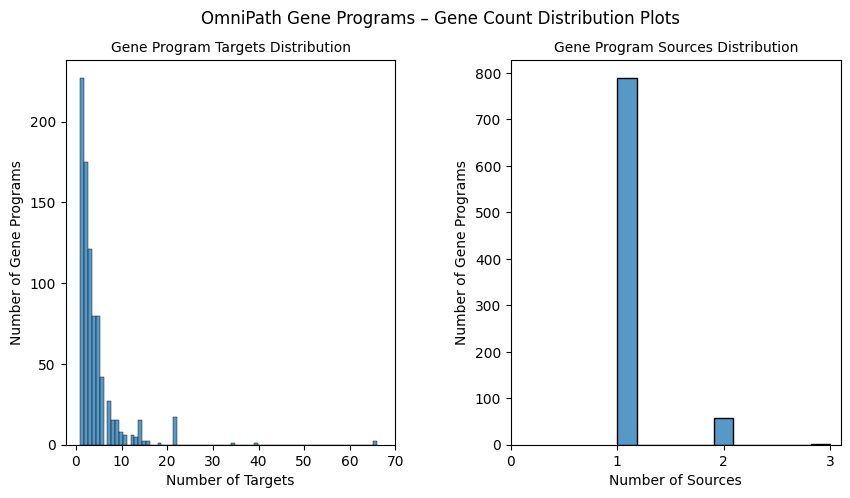

In [11]:
import pandas as pd

# Load the OmniPath file
omnipath_df = pd.read_csv(omnipath_lr_network_file_path)
print(f"Original shape: {omnipath_df.shape}")
print(f"Missing values in genesymbol_intercell_target: {omnipath_df['genesymbol_intercell_target'].isna().sum()}")

# Remove rows with missing target gene symbols
omnipath_df_cleaned = omnipath_df.dropna(subset=['genesymbol_intercell_target'])
print(f"Cleaned shape: {omnipath_df_cleaned.shape}")

# Also check and clean source column if needed
print(f"Missing values in genesymbol_intercell_source: {omnipath_df_cleaned['genesymbol_intercell_source'].isna().sum()}")
omnipath_df_cleaned = omnipath_df_cleaned.dropna(subset=['genesymbol_intercell_source'])
print(f"Final cleaned shape: {omnipath_df_cleaned.shape}")

# Save the cleaned file
omnipath_df_cleaned.to_csv(omnipath_lr_network_file_path, index=False)
print("Saved cleaned OmniPath file")

# Now try the function again
omnipath_gp_dict = extract_gp_dict_from_omnipath_lr_interactions(
    species="human",
    load_from_disk=True,
    save_to_disk=True,
    lr_network_file_path=omnipath_lr_network_file_path,
    gene_orthologs_mapping_file_path=None,
    plot_gp_gene_count_distributions=True,
    gp_gene_count_distributions_save_path=f"{figure_folder_path}/omnipath_gp_gene_count_distributions.pdf"
)

In [12]:
# Display example OmniPath GP
omnipath_gp_names = list(omnipath_gp_dict.keys())
random.shuffle(omnipath_gp_names)
omnipath_gp_name = omnipath_gp_names[0]
print(f"{omnipath_gp_name}: {omnipath_gp_dict[omnipath_gp_name]}")

GDF6_ligand_receptor_GP: {'sources': ['GDF6'], 'targets': ['BMPR2', 'ACVR2A', 'BMPR1B', 'ACVR2B', 'BMPR1A'], 'sources_categories': ['ligand'], 'targets_categories': ['receptor', 'receptor', 'receptor', 'receptor', 'receptor']}


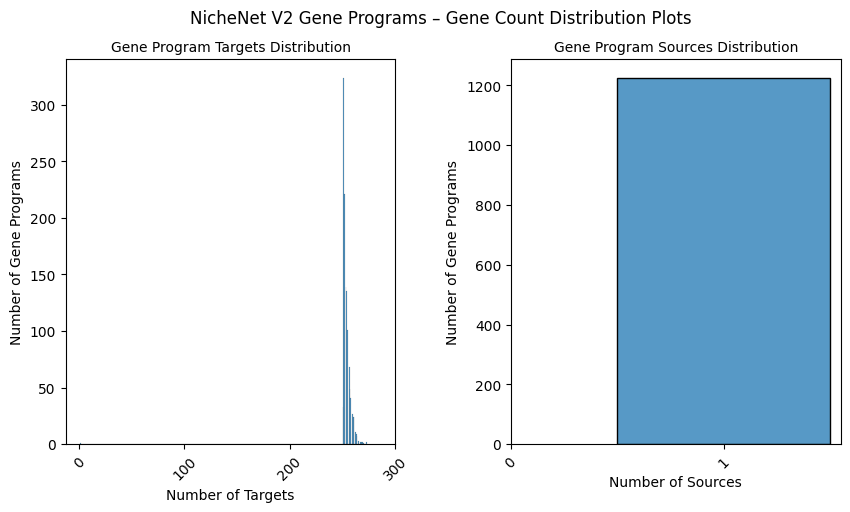

In [13]:
# Retrieve NicheNet GPs (source: ligand genes; target: receptor genes, target genes)
nichenet_gp_dict = extract_gp_dict_from_nichenet_lrt_interactions(
    species=species,
    version="v2",
    keep_target_genes_ratio=1.,
    max_n_target_genes_per_gp=250,
    load_from_disk=False,
    save_to_disk=True,
    lr_network_file_path=nichenet_lr_network_file_path,
    ligand_target_matrix_file_path=nichenet_ligand_target_matrix_file_path,
    gene_orthologs_mapping_file_path=gene_orthologs_mapping_file_path,
    plot_gp_gene_count_distributions=True)

In [14]:
# Display example NicheNet GP
nichenet_gp_names = list(nichenet_gp_dict.keys())
random.shuffle(nichenet_gp_names)
nichenet_gp_name = nichenet_gp_names[0]
print(f"{nichenet_gp_name}: {nichenet_gp_dict[nichenet_gp_name]}")

WNT6_ligand_receptor_target_gene_GP: {'sources': ['WNT6'], 'targets': ['FZD1', 'LRP5', 'FZD3', 'FZD4', 'FZD7', 'LRP6', 'FZD10', 'FZD2', 'FZD5', 'FZD6', 'FZD8', 'FZD9', 'A4GALT', 'AARD', 'ABCA1', 'ABCC3', 'ADAM12', 'ADAM19', 'ADAM2', 'ADAM28', 'ADAR', 'ADGRB1', 'AGT', 'AKR1B1', 'AP1B1', 'AP1G2', 'AP2S1', 'ASH2L', 'ATP4B', 'AURKB', 'BIK', 'BPGM', 'BTG4', 'C8G', 'CASQ2', 'CCDC86', 'CCL2', 'CCR3', 'CCR8', 'CD44', 'CD48', 'CD5', 'CD5L', 'CD74', 'CD79B', 'CD96', 'CDH5', 'CDO1', 'CEACAM1', 'CELF1', 'CFC1', 'CFHR1', 'CHRNA7', 'CKAP4', 'CKMT2', 'CLEC16A', 'CLN3', 'CMBL', 'CMPK2', 'CNGA2', 'COL9A1', 'CPN1', 'CPS1', 'CRMP1', 'CSF2RB', 'CXCL1', 'CYBA', 'CYP2E1', 'DBP', 'DCC', 'DHCR24', 'DIO2', 'DNAJB13', 'DNAJC11', 'DPF3', 'DPYSL4', 'EFNB2', 'EIF2AK2', 'ETV4', 'EYA2', 'F10', 'F2R', 'FABP5', 'FGF18', 'FNTB', 'FOS', 'FOXN3', 'FPR2', 'FXYD3', 'G0S2', 'GABRG2', 'GBP4', 'GDF15', 'GFAP', 'GJD2', 'GLI1', 'GNMT', 'GPX3', 'GRIN2C', 'GRIN2D', 'GRM8', 'GSTA4', 'HAND1', 'HDGFL1', 'HDHD5', 'HEY1', 'HINT1P1', '

In [15]:
import os

# Check if the directory exists and what's in it
print(f"MEBOCOST directory exists: {os.path.exists(mebocost_enzyme_sensor_interactions_folder_path)}")
if os.path.exists(mebocost_enzyme_sensor_interactions_folder_path):
    print(f"Contents: {os.listdir(mebocost_enzyme_sensor_interactions_folder_path)}")
else:
    print("Creating MEBOCOST directory...")
    os.makedirs(mebocost_enzyme_sensor_interactions_folder_path, exist_ok=True)

MEBOCOST directory exists: True
Contents: ['human_metabolite_enzymes.tsv', 'human_metabolite_sensors.tsv']


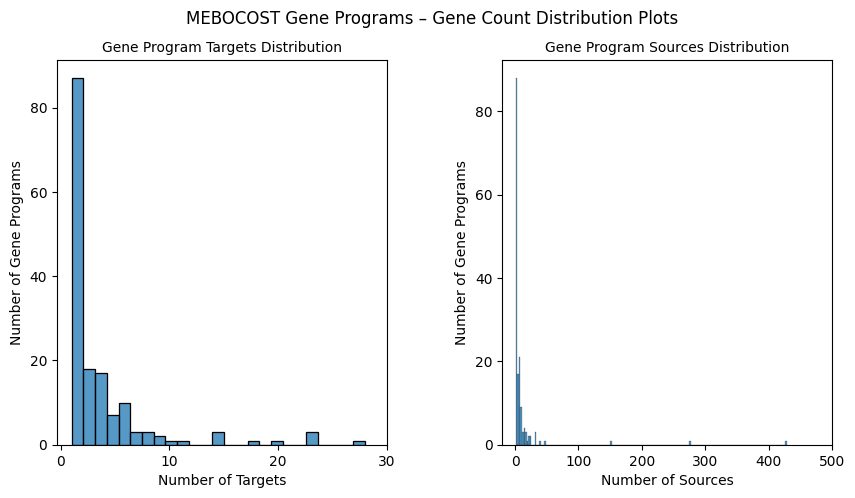

In [16]:
# Retrieve MEBOCOST GPs (source: enzyme genes; target: sensor genes)
mebocost_gp_dict = extract_gp_dict_from_mebocost_ms_interactions(
    dir_path=mebocost_enzyme_sensor_interactions_folder_path,
    species=species,
    plot_gp_gene_count_distributions=True)

In [17]:
# Display example MEBOCOST GP
mebocost_gp_names = list(mebocost_gp_dict.keys())
random.shuffle(mebocost_gp_names)
mebocost_gp_name = mebocost_gp_names[0]
print(f"{mebocost_gp_name}: {mebocost_gp_dict[mebocost_gp_name]}")

Adenosine monophosphate_metabolite_enzyme_sensor_GP: {'sources': ['AACS', 'AARS', 'AARS2', 'ACSBG1', 'ACSBG2', 'ACSL1', 'ACSL3', 'ACSL4', 'ACSL5', 'ACSL6', 'ACSM1', 'ACSM2A', 'ACSM2B', 'ACSM3', 'ACSM4', 'ACSM5', 'ACSM6', 'ACSS1', 'ACSS2', 'ACSS3', 'ADK', 'ADPGK', 'ADPRM', 'ADSL', 'ALDH7A1', 'ASNS', 'ASS1', 'BPNT1', 'C22orf28', 'CARNS1', 'CARS', 'CARS2', 'CDC34', 'DAK', 'DARS', 'DARS2', 'DCK', 'EARS2', 'ENPP1', 'ENPP3', 'ENTPD1', 'ENTPD3', 'ENTPD8', 'EPRS', 'FARS2', 'FARSA', 'FARSB', 'FHIT', 'GARS', 'GMPS', 'GPHN', 'HARS', 'HARS2', 'HLCS', 'IARS', 'IARS2', 'IMPAD1', 'KARS', 'LARS', 'LARS2', 'LIG1', 'LIG3', 'LIG4', 'LIPT1', 'MARS', 'MARS2', 'MOCS3', 'NADSYN1', 'NARS', 'NARS2', 'NUDT10', 'NUDT11', 'NUDT12', 'NUDT2', 'NUDT5', 'NUDT9', 'PARS2', 'PDE10A', 'PDE11A', 'PDE1A', 'PDE1B', 'PDE1C', 'PDE2A', 'PDE3A', 'PDE3B', 'PDE4A', 'PDE4B', 'PDE4C', 'PDE4D', 'PDE7A', 'PDE7B', 'PDE8A', 'PDE8B', 'PPCS', 'PRPS1', 'PRPS1L1', 'PRPS2', 'QARS', 'RARS', 'RARS2', 'RTCA', 'SARS', 'SARS2', 'SEPHS1', 'SEPHS2

In [18]:
# Filter and combine GPs
gp_dicts = [omnipath_gp_dict, nichenet_gp_dict, mebocost_gp_dict]
combined_gp_dict = filter_and_combine_gp_dict_gps_v2(
    gp_dicts,
    verbose=True)

print(f"Number of gene programs after filtering and combining: "
      f"{len(combined_gp_dict)}.")

Combining ACE2_ligand_receptor_GP and ACE2_ligand_receptor_target_gene_GP.
Combining ADCYAP1_ligand_receptor_GP and ADCYAP1_ligand_receptor_target_gene_GP.
Combining ADGRE5_ligand_receptor_GP and ADGRE5_ligand_receptor_target_gene_GP.
Combining ADIPOQ_ligand_receptor_GP and ADIPOQ_ligand_receptor_target_gene_GP.
Combining ADM_ligand_receptor_GP and ADM_ligand_receptor_target_gene_GP.
Combining ADM2_ligand_receptor_GP and ADM2_ligand_receptor_target_gene_GP.
Combining AGRP_ligand_receptor_GP and AGRP_ligand_receptor_target_gene_GP.
Combining AGT_ligand_receptor_GP and AGT_ligand_receptor_target_gene_GP.
Combining ALCAM_ligand_receptor_GP and ALCAM_ligand_receptor_target_gene_GP.
Combining ALKAL1_ligand_receptor_GP and ALKAL1_ligand_receptor_target_gene_GP.
Combining ALKAL2_ligand_receptor_GP and ALKAL2_ligand_receptor_target_gene_GP.
Combining AMBN_ligand_receptor_GP and AMBN_ligand_receptor_target_gene_GP.
Combining AMELX_ligand_receptor_GP and AMELX_ligand_receptor_target_gene_GP.
Com

Combining CLCF1_ligand_receptor_GP and CLCF1_ligand_receptor_target_gene_GP.
Combining CLDN1_ligand_receptor_GP and CLDN1_ligand_receptor_target_gene_GP.
Combining CLDN16_ligand_receptor_GP and CLDN16_ligand_receptor_target_gene_GP.
Combining CLEC2A_ligand_receptor_GP and CLEC2A_ligand_receptor_target_gene_GP.
Combining CLEC2B_ligand_receptor_GP and CLEC2B_ligand_receptor_target_gene_GP.
Combining CLEC2D_ligand_receptor_GP and CLEC2D_ligand_receptor_target_gene_GP.
Combining CLEC4G_ligand_receptor_GP and CLEC4G_ligand_receptor_target_gene_GP.
Combining CLU_ligand_receptor_GP and CLU_ligand_receptor_target_gene_GP.
Combining CMTM8_ligand_receptor_GP and CMTM8_ligand_receptor_target_gene_GP.
Combining CNTN1_ligand_receptor_GP and CNTN1_ligand_receptor_target_gene_GP.
Combining CNTN2_ligand_receptor_GP and CNTN2_ligand_receptor_target_gene_GP.
Combining CNTN3_ligand_receptor_GP and CNTN3_ligand_receptor_target_gene_GP.
Combining CNTN4_ligand_receptor_GP and CNTN4_ligand_receptor_target_ge

Combining FGF1_ligand_receptor_GP and FGF1_ligand_receptor_target_gene_GP.
Combining FGF10_ligand_receptor_GP and FGF10_ligand_receptor_target_gene_GP.
Combining FGF11_ligand_receptor_GP and FGF11_ligand_receptor_target_gene_GP.
Combining FGF12_ligand_receptor_GP and FGF12_ligand_receptor_target_gene_GP.
Combining FGF13_ligand_receptor_GP and FGF13_ligand_receptor_target_gene_GP.
Combining FGF14_ligand_receptor_GP and FGF14_ligand_receptor_target_gene_GP.
Combining FGF16_ligand_receptor_GP and FGF16_ligand_receptor_target_gene_GP.
Combining FGF17_ligand_receptor_GP and FGF17_ligand_receptor_target_gene_GP.
Combining FGF18_ligand_receptor_GP and FGF18_ligand_receptor_target_gene_GP.
Combining FGF19_ligand_receptor_GP and FGF19_ligand_receptor_target_gene_GP.
Combining FGF2_ligand_receptor_GP and FGF2_ligand_receptor_target_gene_GP.
Combining FGF20_ligand_receptor_GP and FGF20_ligand_receptor_target_gene_GP.
Combining FGF21_ligand_receptor_GP and FGF21_ligand_receptor_target_gene_GP.
Com

Combining IGF1_ligand_receptor_GP and IGF1_ligand_receptor_target_gene_GP.
Combining IGF2_ligand_receptor_GP and IGF2_ligand_receptor_target_gene_GP.
Combining IGFBP3_ligand_receptor_GP and IGFBP3_ligand_receptor_target_gene_GP.
Combining IGFBPL1_ligand_receptor_GP and IGFBPL1_ligand_receptor_target_gene_GP.
Combining IGFL1_ligand_receptor_GP and IGFL1_ligand_receptor_target_gene_GP.
Combining IGFL2_ligand_receptor_GP and IGFL2_ligand_receptor_target_gene_GP.
Combining IGFL3_ligand_receptor_GP and IGFL3_ligand_receptor_target_gene_GP.
Combining IGSF11_ligand_receptor_GP and IGSF11_ligand_receptor_target_gene_GP.
Combining IHH_ligand_receptor_GP and IHH_ligand_receptor_target_gene_GP.
Combining IL10_ligand_receptor_GP and IL10_ligand_receptor_target_gene_GP.
Combining IL11_ligand_receptor_GP and IL11_ligand_receptor_target_gene_GP.
Combining IL12A_ligand_receptor_GP and IL12A_ligand_receptor_target_gene_GP.
Combining IL12B_ligand_receptor_GP and IL12B_ligand_receptor_target_gene_GP.
Com

Combining NDP_ligand_receptor_GP and NDP_ligand_receptor_target_gene_GP.
Combining NECTIN2_ligand_receptor_GP and NECTIN2_ligand_receptor_target_gene_GP.
Combining NECTIN3_ligand_receptor_GP and NECTIN3_ligand_receptor_target_gene_GP.
Combining NECTIN4_ligand_receptor_GP and NECTIN4_ligand_receptor_target_gene_GP.
Combining NELL2_ligand_receptor_GP and NELL2_ligand_receptor_target_gene_GP.
Combining NGF_ligand_receptor_GP and NGF_ligand_receptor_target_gene_GP.
Combining NID1_ligand_receptor_GP and NID1_ligand_receptor_target_gene_GP.
Combining NLGN1_ligand_receptor_GP and NLGN1_ligand_receptor_target_gene_GP.
Combining NLGN2_ligand_receptor_GP and NLGN2_ligand_receptor_target_gene_GP.
Combining NLGN3_ligand_receptor_GP and NLGN3_ligand_receptor_target_gene_GP.
Combining NLGN4X_ligand_receptor_GP and NLGN4X_ligand_receptor_target_gene_GP.
Combining NMB_ligand_receptor_GP and NMB_ligand_receptor_target_gene_GP.
Combining NMS_ligand_receptor_GP and NMS_ligand_receptor_target_gene_GP.
Com

Combining S100A9_ligand_receptor_GP and S100A9_ligand_receptor_target_gene_GP.
Combining S100B_ligand_receptor_GP and S100B_ligand_receptor_target_gene_GP.
Combining SAA1_ligand_receptor_GP and SAA1_ligand_receptor_target_gene_GP.
Combining SCGB1A1_ligand_receptor_GP and SCGB1A1_ligand_receptor_target_gene_GP.
Combining SCGB3A1_ligand_receptor_GP and SCGB3A1_ligand_receptor_target_gene_GP.
Combining SCGB3A2_ligand_receptor_GP and SCGB3A2_ligand_receptor_target_gene_GP.
Combining SCT_ligand_receptor_GP and SCT_ligand_receptor_target_gene_GP.
Combining SDC2_ligand_receptor_GP and SDC2_ligand_receptor_target_gene_GP.
Combining SECTM1_ligand_receptor_GP and SECTM1_ligand_receptor_target_gene_GP.
Combining SEMA3A_ligand_receptor_GP and SEMA3A_ligand_receptor_target_gene_GP.
Combining SEMA3B_ligand_receptor_GP and SEMA3B_ligand_receptor_target_gene_GP.
Combining SEMA3C_ligand_receptor_GP and SEMA3C_ligand_receptor_target_gene_GP.
Combining SEMA3D_ligand_receptor_GP and SEMA3D_ligand_receptor

... (3 outputs left out)

Combining IGF2_ligand_receptor_target_gene_GP and IGF2_ligand_receptor_GP.
Combining IGFBP3_ligand_receptor_target_gene_GP and IGFBP3_ligand_receptor_GP.
Combining IGFBPL1_ligand_receptor_target_gene_GP and IGFBPL1_ligand_receptor_GP.
Combining IGFL1_ligand_receptor_target_gene_GP and IGFL1_ligand_receptor_GP.
Combining IGFL2_ligand_receptor_target_gene_GP and IGFL2_ligand_receptor_GP.
Combining IGFL3_ligand_receptor_target_gene_GP and IGFL3_ligand_receptor_GP.
Combining IGSF11_ligand_receptor_target_gene_GP and IGSF11_ligand_receptor_GP.
Combining IHH_ligand_receptor_target_gene_GP and IHH_ligand_receptor_GP.
Combining IL10_ligand_receptor_target_gene_GP and IL10_ligand_receptor_GP.
Combining IL11_ligand_receptor_target_gene_GP and IL11_ligand_receptor_GP.
Combining IL12A_ligand_receptor_target_gene_GP and IL12A_ligand_receptor_GP.
Combining IL12B_ligand_receptor_target_gene_GP and IL12B_ligand_receptor_GP.
Combining IL13_ligand_receptor_target_gene_GP and IL13_ligand_receptor_GP.
Com

Combining MMRN2_ligand_receptor_target_gene_GP and MMRN2_ligand_receptor_GP.
Combining MSN_ligand_receptor_target_gene_GP and MSN_ligand_receptor_GP.
Combining MST1_ligand_receptor_target_gene_GP and MST1_ligand_receptor_GP.
Combining MSTN_ligand_receptor_target_gene_GP and MSTN_ligand_receptor_GP.
Combining MUC1_ligand_receptor_target_gene_GP and MUC1_ligand_receptor_GP.
Combining MYOC_ligand_receptor_target_gene_GP and MYOC_ligand_receptor_GP.
Combining NCR3LG1_ligand_receptor_target_gene_GP and NCR3LG1_ligand_receptor_GP.
Combining NDP_ligand_receptor_target_gene_GP and NDP_ligand_receptor_GP.
Combining NECTIN2_ligand_receptor_target_gene_GP and NECTIN2_ligand_receptor_GP.
Combining NECTIN3_ligand_receptor_target_gene_GP and NECTIN3_ligand_receptor_GP.
Combining NECTIN4_ligand_receptor_target_gene_GP and NECTIN4_ligand_receptor_GP.
Combining NELL2_ligand_receptor_target_gene_GP and NELL2_ligand_receptor_GP.
Combining NGF_ligand_receptor_target_gene_GP and NGF_ligand_receptor_GP.
Com

Combining RSPO1_ligand_receptor_target_gene_GP and RSPO1_ligand_receptor_GP.
Combining RSPO2_ligand_receptor_target_gene_GP and RSPO2_ligand_receptor_GP.
Combining RSPO3_ligand_receptor_target_gene_GP and RSPO3_ligand_receptor_GP.
Combining RSPO4_ligand_receptor_target_gene_GP and RSPO4_ligand_receptor_GP.
Combining S100A10_ligand_receptor_target_gene_GP and S100A10_ligand_receptor_GP.
Combining S100A4_ligand_receptor_target_gene_GP and S100A4_ligand_receptor_GP.
Combining S100A8_ligand_receptor_target_gene_GP and S100A8_ligand_receptor_GP.
Combining S100A9_ligand_receptor_target_gene_GP and S100A9_ligand_receptor_GP.
Combining S100B_ligand_receptor_target_gene_GP and S100B_ligand_receptor_GP.
Combining SAA1_ligand_receptor_target_gene_GP and SAA1_ligand_receptor_GP.
Combining SCGB1A1_ligand_receptor_target_gene_GP and SCGB1A1_ligand_receptor_GP.
Combining SCGB3A1_ligand_receptor_target_gene_GP and SCGB3A1_ligand_receptor_GP.
Combining SCGB3A2_ligand_receptor_target_gene_GP and SCGB3A2

Combining WNT5B_ligand_receptor_target_gene_GP and WNT5B_ligand_receptor_GP.
Combining WNT6_ligand_receptor_target_gene_GP and WNT6_ligand_receptor_GP.
Combining WNT7A_ligand_receptor_target_gene_GP and WNT7A_ligand_receptor_GP.
Combining WNT7B_ligand_receptor_target_gene_GP and WNT7B_ligand_receptor_GP.
Combining WNT8A_ligand_receptor_target_gene_GP and WNT8A_ligand_receptor_GP.
Combining WNT8B_ligand_receptor_target_gene_GP and WNT8B_ligand_receptor_GP.
Combining WNT9A_ligand_receptor_target_gene_GP and WNT9A_ligand_receptor_GP.
Combining WNT9B_ligand_receptor_target_gene_GP and WNT9B_ligand_receptor_GP.
Combining XCL1_ligand_receptor_target_gene_GP and XCL1_ligand_receptor_GP.
Combining XCL2_ligand_receptor_target_gene_GP and XCL2_ligand_receptor_GP.
Combining ZP3_ligand_receptor_target_gene_GP and ZP3_ligand_receptor_GP.
Combining Deoxycytidine_metabolite_enzyme_sensor_GP and Deoxyguanosine_metabolite_enzyme_sensor_GP.
Combining Deoxycytidine_metabolite_enzyme_sensor_GP and Cytidin

In [19]:
adata = sc.read_h5ad("/beegfs/home/lfrommer/projects/kidney_biopsy/xenium_with_niches.h5ad")

In [20]:
adata5 = adata[adata.obs["latent_leiden_0.4"] == "5"].copy()

adata = adata5.copy()

In [20]:
import numpy as np
import pandas as pd

# Build a set of labels to exclude (spellings must match your obs exactly)
to_exclude = {
    "Unassigned",
    "Appollo d0 A2 CTRL",          # check spelling: "Appollo" vs "Apollo"
    "Utrecht2 C2 T18-04025 K4 DN",
    "Utrecht2 C3 T17-11176 K24 TIN",
    "Utrecht 2 A5 T03-04110 K29 MN",  # note the space in "Utrecht 2"
    "Utrecht2 C5 T17-03068 K23 TIN",
    "Utrecht1 B5 T18-01374 K25 TIN",
    "Utrecht1 D5 T13-04884 K71 FSGS",
    "Utrecht1 B1 T18-13048 K46 MN",
    "Utrecht1 D1 T15-05977 K78 FSGS",
    "Utrecht2 B6 T18-04295 K60 IgAN",
}

# Create a boolean mask: keep rows not in to_exclude and not NaN
mask_keep = ~adata.obs["TMA_ID"].isin(to_exclude) & adata.obs["TMA_ID"].notna()

# Subset AnnData (this returns a view; use .copy() if you want an independent object)
adata_filt = adata[mask_keep].copy()

# Optional: drop unused categories if TMA_ID is categorical
if pd.api.types.is_categorical_dtype(adata_filt.obs["TMA_ID"]):
    adata_filt.obs["TMA_ID"] = adata_filt.obs["TMA_ID"].cat.remove_unused_categories()

adata_filt

adata = adata_filt.copy()

In [21]:
# Compute spatial neighborhood
sq.gr.spatial_neighbors(adata,
                        coord_type="generic",
                        spatial_key=spatial_key,
                        n_neighs=n_neighbors)

# Make adjacency matrix symmetric
adata.obsp[adj_key] = (
    adata.obsp[adj_key].maximum(
        adata.obsp[adj_key].T))

In [22]:
# Add the GP dictionary as binary masks to the adata
add_gps_from_gp_dict_to_adata(
    gp_dict=combined_gp_dict,
    adata=adata,
    gp_targets_mask_key=gp_targets_mask_key,
    gp_targets_categories_mask_key=gp_targets_categories_mask_key,
    gp_sources_mask_key=gp_sources_mask_key,
    gp_sources_categories_mask_key=gp_sources_categories_mask_key,
    gp_names_key=gp_names_key,
    min_genes_per_gp=2,
    min_source_genes_per_gp=1,
    min_target_genes_per_gp=1,
    max_genes_per_gp=None,
    max_source_genes_per_gp=None,
    max_target_genes_per_gp=None)

In [23]:
cell_type_colors = create_new_color_dict(
    adata=adata,
    cat_key=cell_type_key)

Number of nodes (observations): 19924
Number of node features (genes): 468


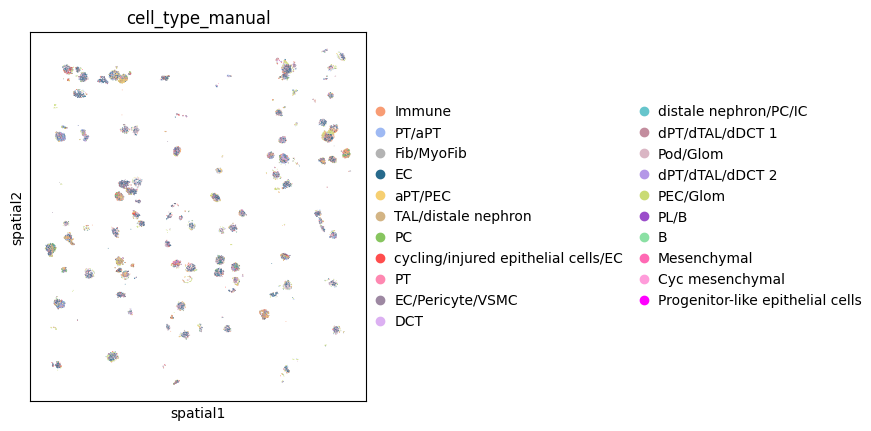

In [24]:
print(f"Number of nodes (observations): {adata.layers['counts'].shape[0]}")
print(f"Number of node features (genes): {adata.layers['counts'].shape[1]}")

# Visualize cell-level annotated data in physical space
sc.pl.spatial(adata,
              color=cell_type_key,
              palette=cell_type_colors,
              spot_size=spot_size)        

In [25]:
adata

AnnData object with n_obs × n_vars = 19924 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [26]:
# Initialize model
model = NicheCompass(adata,
                     counts_key=counts_key,
                     adj_key=adj_key,
                     gp_names_key=gp_names_key,
                     active_gp_names_key=active_gp_names_key,
                     gp_targets_mask_key=gp_targets_mask_key,
                     gp_targets_categories_mask_key=gp_targets_categories_mask_key,
                     gp_sources_mask_key=gp_sources_mask_key,
                     gp_sources_categories_mask_key=gp_sources_categories_mask_key,
                     latent_key=latent_key,
                     conv_layer_encoder=conv_layer_encoder,
                     active_gp_thresh_ratio=active_gp_thresh_ratio)

--- INITIALIZING NEW NETWORK MODULE: VARIATIONAL GENE PROGRAM GRAPH AUTOENCODER ---
LOSS -> include_edge_recon_loss: True, include_gene_expr_recon_loss: True, rna_recon_loss: nb
NODE LABEL METHOD -> one-hop-norm
ACTIVE GP THRESHOLD RATIO -> 0.01
LOG VARIATIONAL -> True
ONE HOP GCN NORM RNA NODE LABEL AGGREGATOR
ENCODER -> n_input: 468, n_cat_covariates_embed_input: 0, n_hidden: 216, n_latent: 116, n_addon_latent: 100, n_fc_layers: 1, n_layers: 1, conv_layer: gatv2conv, n_attention_heads: 4, dropout_rate: 0.0, 
COSINE SIM GRAPH DECODER -> dropout_rate: 0.0
MASKED TARGET RNA DECODER -> n_prior_gp_input: 116, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 468
MASKED SOURCE RNA DECODER -> n_prior_gp_input: 116, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 468


In [27]:
# Train model
model.train(n_epochs=n_epochs,
            n_epochs_all_gps=n_epochs_all_gps,
            lr=lr,
            lambda_edge_recon=lambda_edge_recon,
            lambda_gene_expr_recon=lambda_gene_expr_recon,
            lambda_l1_masked=lambda_l1_masked,
            edge_batch_size=edge_batch_size,
            n_sampled_neighbors=n_sampled_neighbors,
            use_cuda_if_available=use_cuda_if_available,
            verbose=False)


--- INITIALIZING TRAINER ---
Number of training nodes: 17932
Number of validation nodes: 1992
Number of training edges: 43211
Number of validation edges: 4801
Edge batch size: 1024
Node batch size: None

--- MODEL TRAINING ---
Epoch 1/400 |--------------------| 0.2% train_global_loss: 721092.7398; train_optim_loss: 721092.7398; val_global_loss: 726038.3000; val_optim_loss: 726038.3000
Epoch 2/400 |--------------------| 0.5% train_global_loss: 638730.2703; train_optim_loss: 638730.2703; val_global_loss: 622171.4000; val_optim_loss: 622171.4000
Epoch 3/400 |--------------------| 0.8% train_global_loss: 592397.7064; train_optim_loss: 592397.7064; val_global_loss: 599534.1000; val_optim_loss: 599534.1000
Epoch 4/400 |--------------------| 1.0% train_global_loss: 576919.8648; train_optim_loss: 576919.8648; val_global_loss: 587146.7500; val_optim_loss: 587146.7500
Epoch 5/400 |--------------------| 1.2% train_global_loss: 568070.3924; train_optim_loss: 568070.3924; val_global_loss: 577681.1

In [28]:
# Compute latent neighbor graph
sc.pp.neighbors(model.adata,
                use_rep=latent_key,
                key_added=latent_key)

# Compute UMAP embedding
sc.tl.umap(model.adata,
           neighbors_key=latent_key)

In [29]:
# Save trained model
model.save(dir_path=model_folder_path,
           overwrite=True,
           save_adata=True,
           adata_file_name="adata.h5ad")

In [30]:
#load_timestamp = "04092025_125840"
load_timestamp = current_timestamp # uncomment if you trained the model in this notebook

figure_folder_path = f"{artifacts_folder_path}/single_sample/{load_timestamp}/figures"
model_folder_path = f"{artifacts_folder_path}/single_sample/{load_timestamp}/model"

os.makedirs(figure_folder_path, exist_ok=True)

In [31]:
# Load trained model
model = NicheCompass.load(dir_path=model_folder_path,
                          adata=None,
                          adata_file_name="adata.h5ad",
                          gp_names_key=gp_names_key)

--- INITIALIZING NEW NETWORK MODULE: VARIATIONAL GENE PROGRAM GRAPH AUTOENCODER ---
LOSS -> include_edge_recon_loss: True, include_gene_expr_recon_loss: True, rna_recon_loss: nb
NODE LABEL METHOD -> one-hop-norm
ACTIVE GP THRESHOLD RATIO -> 0.01
LOG VARIATIONAL -> True
ONE HOP GCN NORM RNA NODE LABEL AGGREGATOR
ENCODER -> n_input: 468, n_cat_covariates_embed_input: 0, n_hidden: 216, n_latent: 116, n_addon_latent: 100, n_fc_layers: 1, n_layers: 1, conv_layer: gatv2conv, n_attention_heads: 4, dropout_rate: 0.0, 
COSINE SIM GRAPH DECODER -> dropout_rate: 0.0
MASKED TARGET RNA DECODER -> n_prior_gp_input: 116, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 468
MASKED SOURCE RNA DECODER -> n_prior_gp_input: 116, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 468


In [32]:
samples = model.adata.obs[sample_key].unique().tolist()

In [33]:
cell_type_colors = create_new_color_dict(
    adata=model.adata,
    cat_key=cell_type_key)

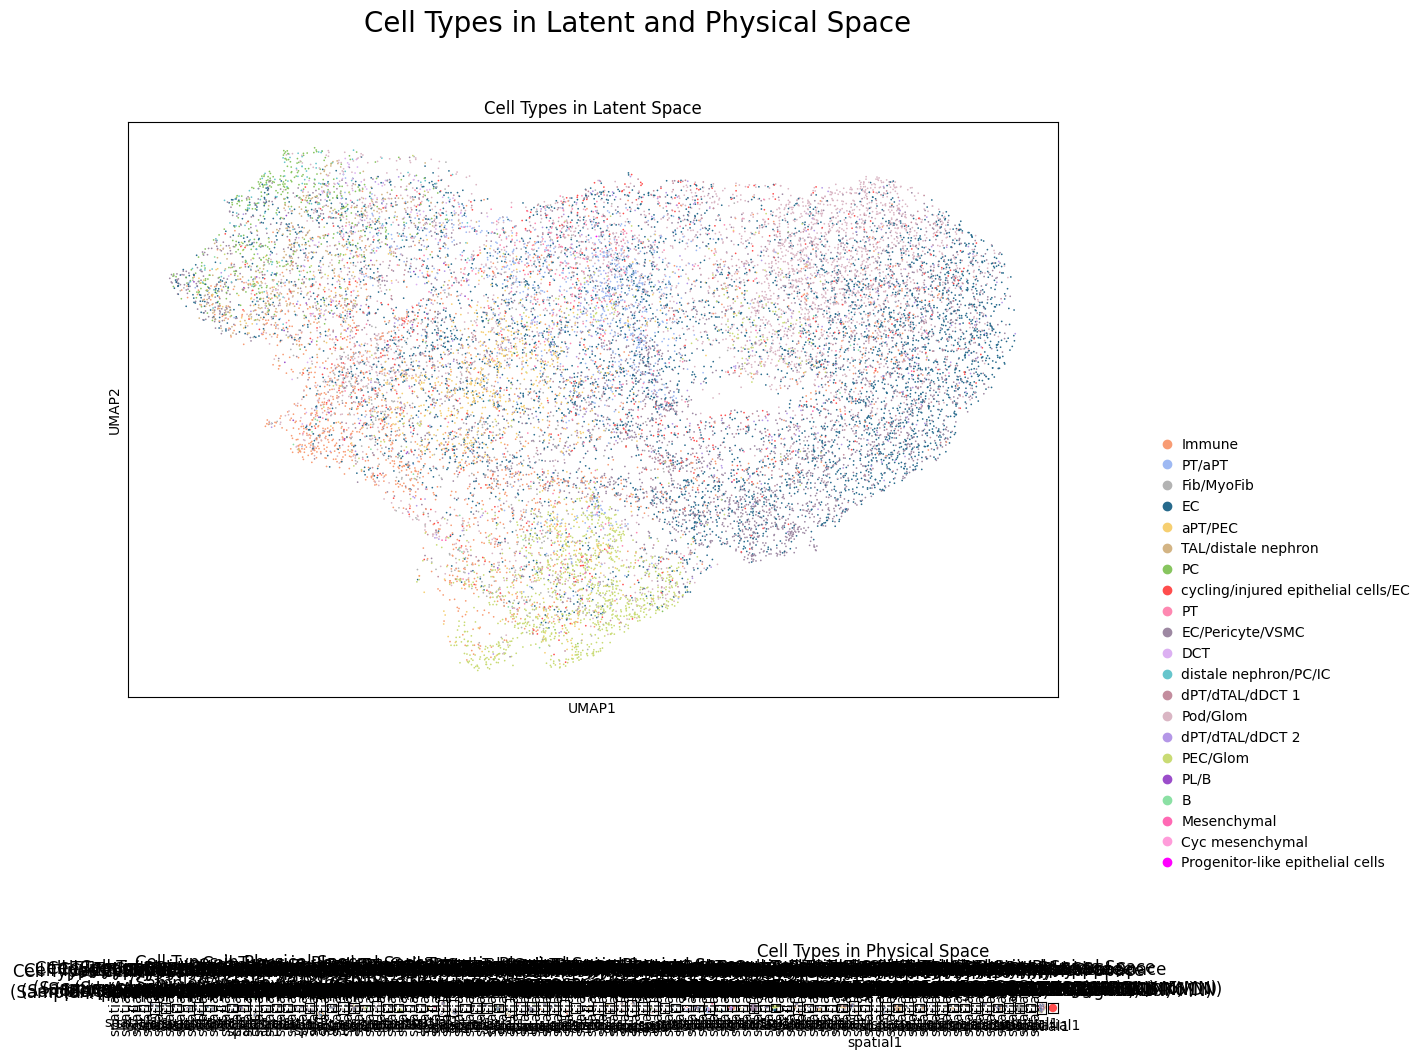

In [34]:
# Create plot of cell type annotations in physical and latent space
groups = None
save_fig = True
file_path = f"{figure_folder_path}/" \
            "cell_types_latent_physical_space.pdf"

fig = plt.figure(figsize=(12, 14))
title = fig.suptitle(t=f"Cell Types " \
                       "in Latent and Physical Space",
                     y=0.96,
                     x=0.55,
                     fontsize=20)
spec1 = gridspec.GridSpec(ncols=1,
                          nrows=2,
                          width_ratios=[1],
                          height_ratios=[3, 2])
spec2 = gridspec.GridSpec(ncols=len(samples),
                          nrows=2,
                          width_ratios=[1] * len(samples),
                          height_ratios=[3, 2])
axs = []
axs.append(fig.add_subplot(spec1[0]))
sc.pl.umap(adata=model.adata,
           color=[cell_type_key],
           groups=groups,palette=cell_type_colors,
           title=f"Cell Types in Latent Space",
           ax=axs[0],
           show=False)
for idx, sample in enumerate(samples):
    axs.append(fig.add_subplot(spec2[len(samples) + idx]))
    sc.pl.spatial(adata=model.adata[model.adata.obs[sample_key] == sample],
                  color=[cell_type_key],
                  groups=groups,
                  palette=cell_type_colors,
                  spot_size=spot_size,
                  title=f"Cell Types in Physical Space \n"
                        f"(Sample: {sample})",
                  legend_loc=None,
                  ax=axs[idx+1],
                  show=False)

# Create and position shared legend
handles, labels = axs[0].get_legend_handles_labels()
lgd = fig.legend(handles,
                 labels,
                 loc="center left",
                 bbox_to_anchor=(0.98, 0.5))
axs[0].get_legend().remove()

# Adjust, save and display plot
plt.subplots_adjust(wspace=0.2, hspace=0.25)
if save_fig:
    fig.savefig(file_path,
                bbox_extra_artists=(lgd, title),
                bbox_inches="tight")
plt.show()

In [35]:
# Compute latent Leiden clustering
sc.tl.leiden(adata=model.adata,
             resolution=latent_leiden_resolution,
             key_added=latent_cluster_key,
             neighbors_key=latent_key)

In [36]:
latent_cluster_colors = create_new_color_dict(
    adata=model.adata,
    cat_key=latent_cluster_key)

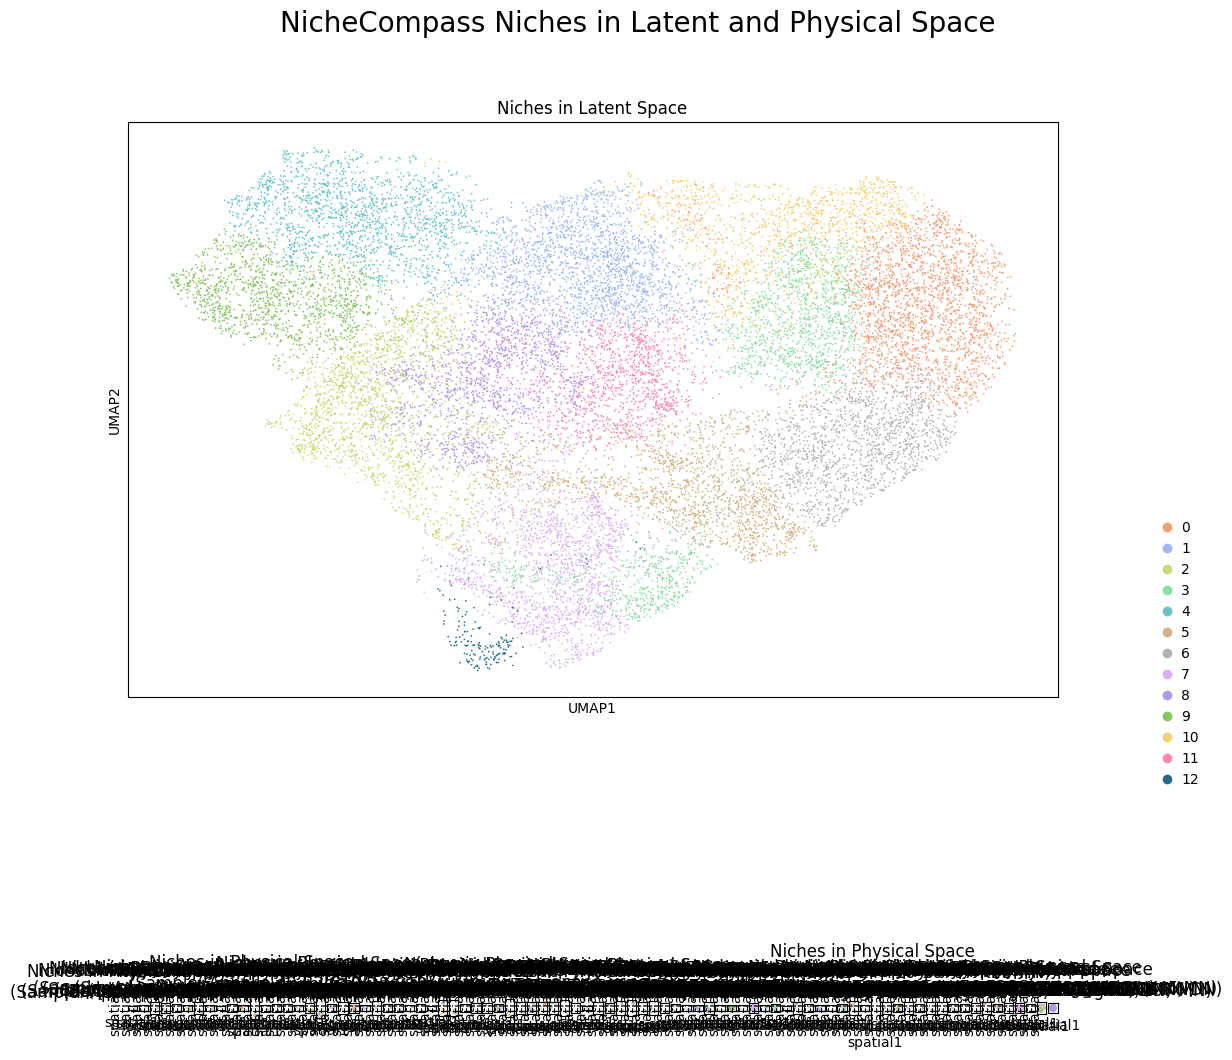

In [37]:
# Create plot of latent cluster / niche annotations in physical and latent space
groups = None # set this to a specific cluster for easy visualization, e.g. ["17"]
save_fig = True
file_path = f"{figure_folder_path}/" \
            f"res_{latent_leiden_resolution}_" \
            "niches_latent_physical_space.pdf"

fig = plt.figure(figsize=(12, 14))
title = fig.suptitle(t=f"NicheCompass Niches " \
                       "in Latent and Physical Space",
                     y=0.96,
                     x=0.55,
                     fontsize=20)
spec1 = gridspec.GridSpec(ncols=1,
                          nrows=2,
                          width_ratios=[1],
                          height_ratios=[3, 2])
spec2 = gridspec.GridSpec(ncols=len(samples),
                          nrows=2,
                          width_ratios=[1] * len(samples),
                          height_ratios=[3, 2])
axs = []
axs.append(fig.add_subplot(spec1[0]))
sc.pl.umap(adata=model.adata,
           color=[latent_cluster_key],
           groups=groups,
           palette=latent_cluster_colors,
           title=f"Niches in Latent Space",
           ax=axs[0],
           show=False)
for idx, sample in enumerate(samples):
    axs.append(fig.add_subplot(spec2[len(samples) + idx]))
    sc.pl.spatial(adata=model.adata[model.adata.obs[sample_key] == sample],
                  color=[latent_cluster_key],
                  groups=groups,
                  palette=latent_cluster_colors,
                  spot_size=spot_size,
                  title=f"Niches in Physical Space \n"
                        f"(Sample: {sample})",
                  legend_loc=None,
                  ax=axs[idx+1],
                  show=False)

# Create and position shared legend
handles, labels = axs[0].get_legend_handles_labels()
lgd = fig.legend(handles,
                 labels,
                 loc="center left",
                 bbox_to_anchor=(0.98, 0.5))
axs[0].get_legend().remove()

# Adjust, save and display plot
plt.subplots_adjust(wspace=0.2, hspace=0.25)
if save_fig:
    fig.savefig(file_path,
                bbox_extra_artists=(lgd, title),
                bbox_inches="tight")
plt.show()

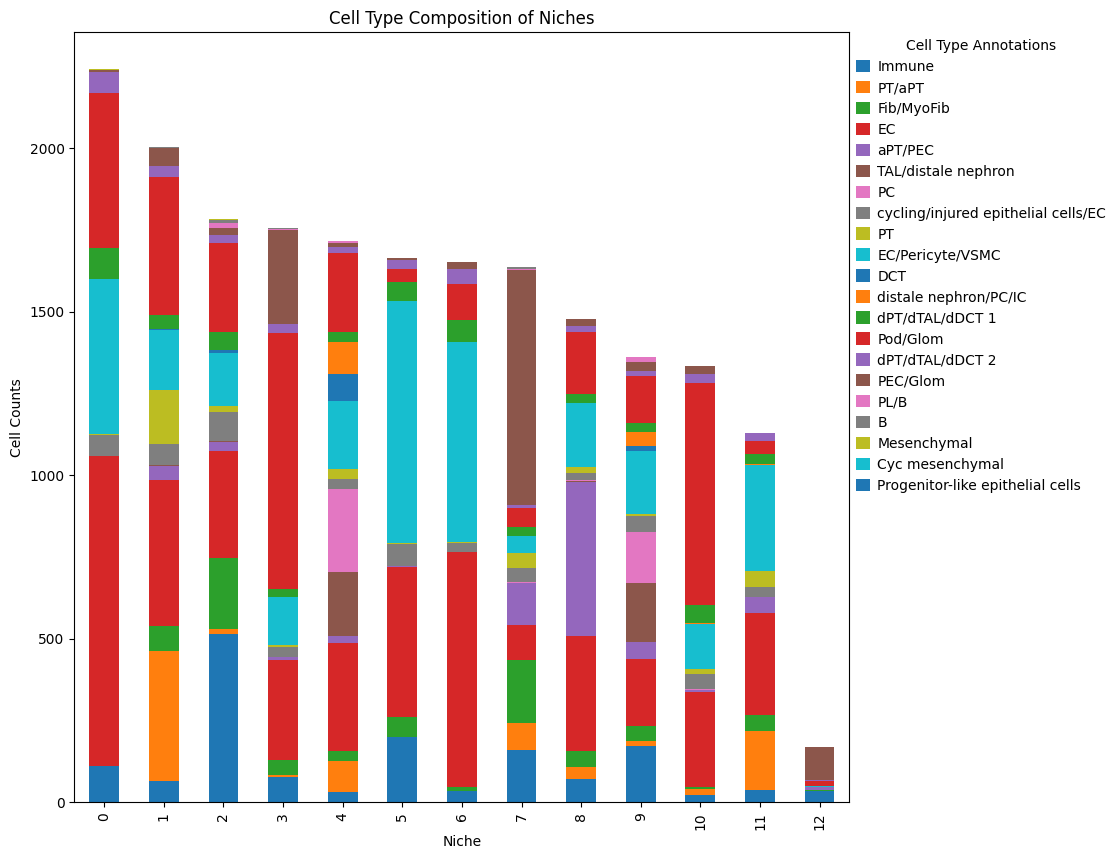

In [38]:
save_fig = True
file_path = f"{figure_folder_path}/" \
            f"res_{latent_leiden_resolution}_" \
            f"niche_composition_cell_type.pdf"

df_counts = (model.adata.obs.groupby([latent_cluster_key, cell_type_key])
             .size().unstack())
df_counts.plot(kind="bar", stacked=True, figsize=(10,10))
legend = plt.legend(bbox_to_anchor=(1, 1), loc="upper left", prop={'size': 10})
legend.set_title("Cell Type Annotations", prop={'size': 10})
plt.title("Cell Type Composition of Niches")
plt.xlabel("Niche")
plt.ylabel("Cell Counts")
if save_fig:
    plt.savefig(file_path,
                bbox_extra_artists=(legend,),
                bbox_inches="tight")

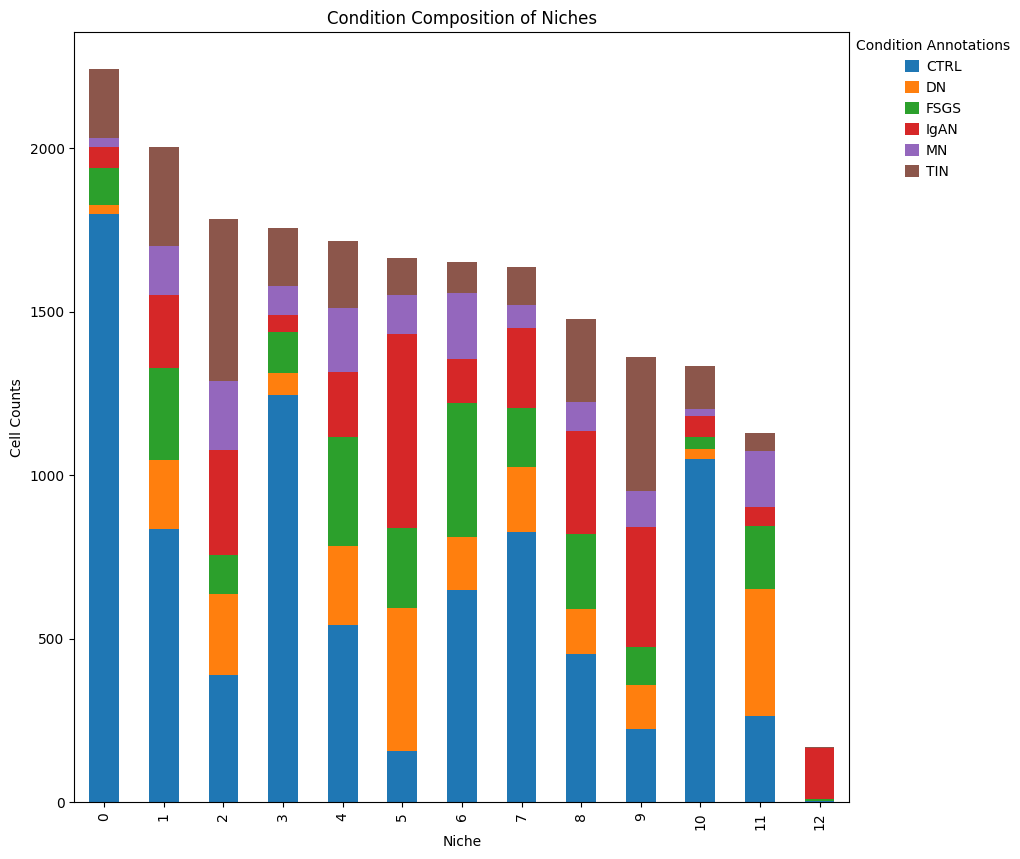

In [39]:
save_fig = True
file_path = f"{figure_folder_path}/" \
            f"res_{latent_leiden_resolution}_" \
            f"niche_composition_condition.pdf"

df_counts = (model.adata.obs.groupby([latent_cluster_key, "condition"])
             .size().unstack())
df_counts.plot(kind="bar", stacked=True, figsize=(10,10))
legend = plt.legend(bbox_to_anchor=(1, 1), loc="upper left", prop={'size': 10})
legend.set_title("Condition Annotations", prop={'size': 10})
plt.title("Condition Composition of Niches")
plt.xlabel("Niche")
plt.ylabel("Cell Counts")
if save_fig:
    plt.savefig(file_path,
                bbox_extra_artists=(legend,),
                bbox_inches="tight")

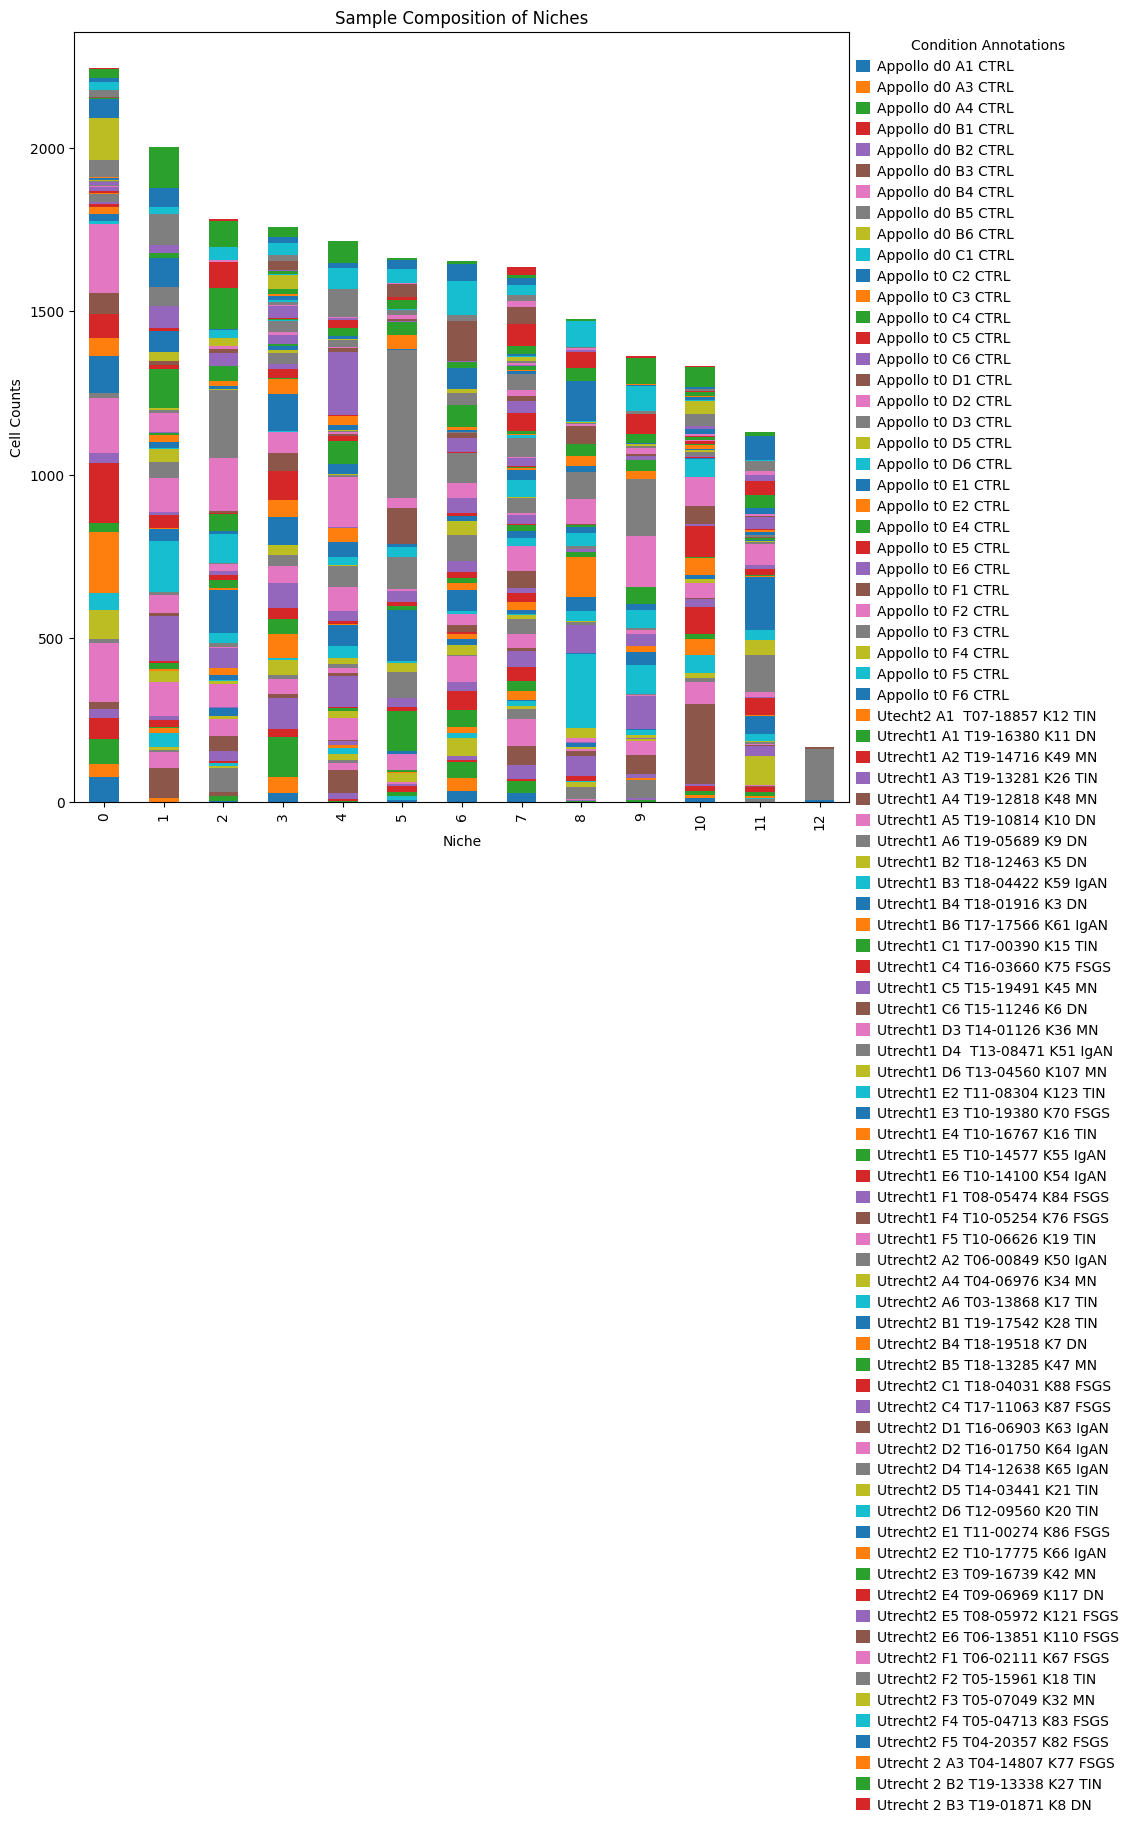

In [40]:
save_fig = True
file_path = f"{figure_folder_path}/" \
            f"res_{latent_leiden_resolution}_" \
            f"niche_composition_sample.pdf"

df_counts = (model.adata.obs.groupby([latent_cluster_key, "TMA_ID"])
             .size().unstack())
df_counts.plot(kind="bar", stacked=True, figsize=(10,10))
legend = plt.legend(bbox_to_anchor=(1, 1), loc="upper left", prop={'size': 10})
legend.set_title("Condition Annotations", prop={'size': 10})
plt.title("Sample Composition of Niches")
plt.xlabel("Niche")
plt.ylabel("Cell Counts")
if save_fig:
    plt.savefig(file_path,
                bbox_extra_artists=(legend,),
                bbox_inches="tight")

In [41]:
# Check number of active GPs
active_gps = model.get_active_gps()
print(f"Number of total gene programs: {len(model.adata.uns[gp_names_key])}.")
print(f"Number of active gene programs: {len(active_gps)}.")

Number of total gene programs: 216.
Number of active gene programs: 123.


In [42]:
# Display example active GPs
gp_summary_df = model.get_gp_summary()
gp_summary_df[gp_summary_df["gp_active"] == True].head()

,gp_name,all_gp_idx,gp_active,active_gp_idx,n_source_genes,n_non_zero_source_genes,n_target_genes,n_non_zero_target_genes,gp_source_genes,gp_target_genes,gp_source_genes_weights,gp_target_genes_weights,gp_source_genes_importances,gp_target_genes_importances
0,AFDN_ligand_receptor_GP,0,True,0,1,1,3,3,[AFDN],"[EPHA7, EPHB2, NRXN3]",[0.0069],"[-0.396, 0.3123, -0.0236]",[0.0093],"[0.536, 0.4227, 0.032]"
1,COMPLEX:INHBA_INHBB_ligand_receptor_GP,1,True,1,1,1,2,2,[INHBA],"[ACVR1B, ACVR2A]",[0.0098],"[0.0074, -0.0004]",[0.554],"[0.4207, 0.0253]"
2,COMPLEX:LAMA1_LAMB1_LAMC1_ligand_receptor_GP,2,True,2,2,2,1,1,"[LAMC1, LAMB1]",[ITGB1],"[0.3596, -0.0332]",[0.056],"[0.8012, 0.0741]",[0.1247]
3,DPP4_ligand_receptor_GP,3,True,3,1,1,1,1,[DPP4],[CXCL12],[-0.102],[-0.1488],[0.4067],[0.5933]
4,ITGA5_ligand_receptor_GP,4,True,4,1,1,1,1,[ITGA5],[ADAM15],[-0.1971],[-0.2062],[0.4888],[0.5112]


In [43]:
# Set parameters for differential gp testing
selected_cats = None
comparison_cats = "rest"
title = f"NicheCompass Strongly Enriched Niche GPs"
log_bayes_factor_thresh = 2.3
save_fig = True
file_path = f"{figure_folder_path}/" \
            f"/log_bayes_factor_{log_bayes_factor_thresh}" \
             "_niches_enriched_gps_heatmap.pdf"

In [44]:
# Run differential gp testing
enriched_gps = model.run_differential_gp_tests(
    cat_key=latent_cluster_key,
    selected_cats=selected_cats,
    comparison_cats=comparison_cats,
    log_bayes_factor_thresh=log_bayes_factor_thresh)

In [45]:
# Results are stored in a df in the adata object
model.adata.uns[differential_gp_test_results_key]

,category,gene_program,p_h0,p_h1,log_bayes_factor
0,12,CA12_ligand_receptor_target_gene_GP,0.002993,0.997007,-5.808564
1,12,CEACAM1_ligand_receptor_target_gene_GP,0.010652,0.989348,-4.531279
2,12,KDR_ligand_receptor_GP,0.986917,0.013083,4.323243
3,4,CA12_ligand_receptor_target_gene_GP,0.986041,0.013959,4.257542
4,7,Add-on_39_GP,0.983035,0.016965,4.059505
...,...,...,...,...,...
91,8,S100A4_combined_GP,0.087857,0.912143,-2.340090
92,9,FGF9_combined_GP,0.911831,0.088169,2.336205
93,7,PECAM1_combined_GP,0.911449,0.088551,2.331452
94,4,LAMC1_combined_GP,0.910238,0.089762,2.316550


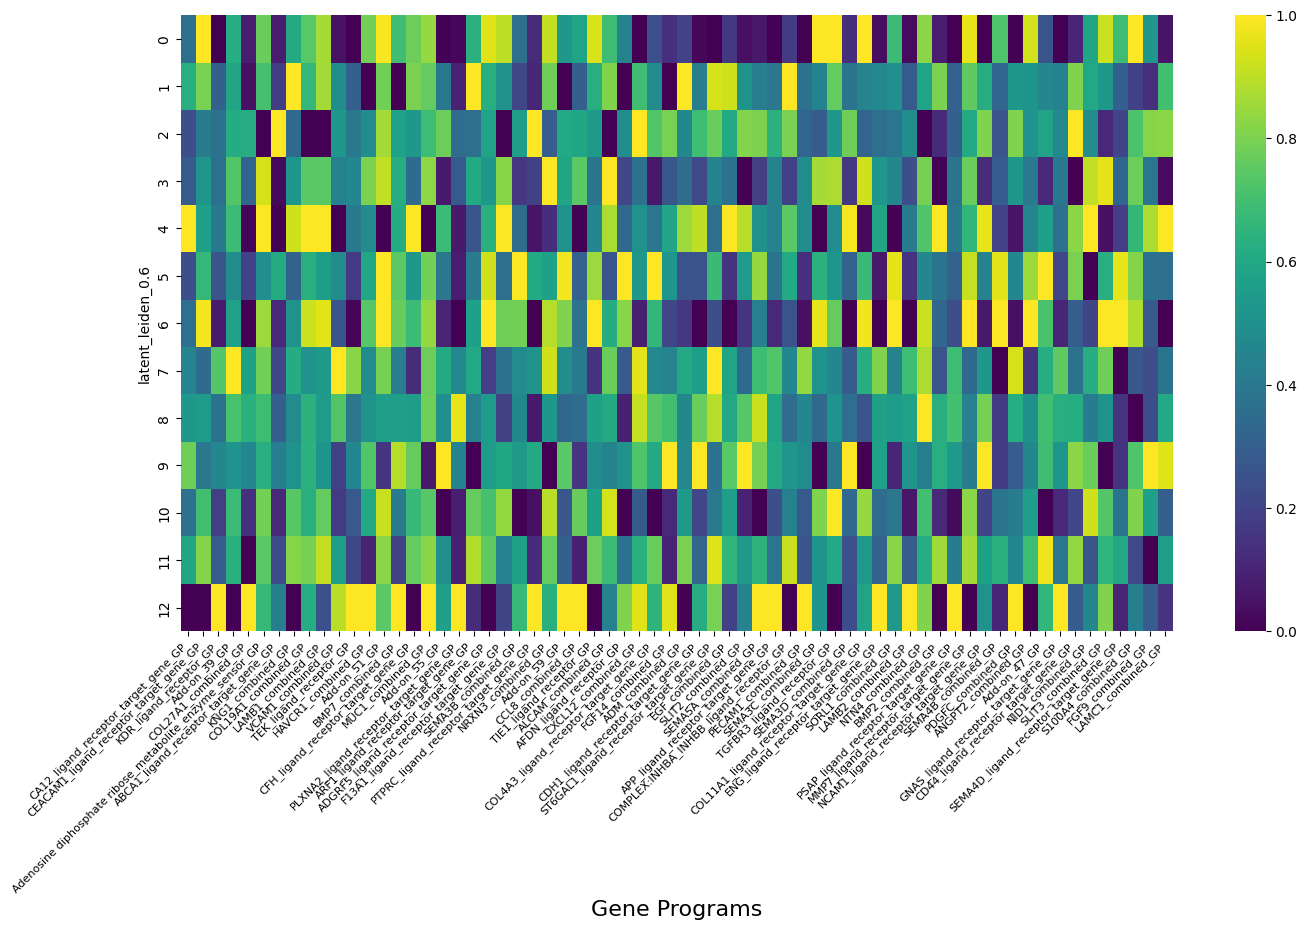

In [46]:
# Visualize GP activities of enriched GPs across niches
df = model.adata.obs[[latent_cluster_key] + enriched_gps].groupby(latent_cluster_key).mean()

scaler = MinMaxScaler()
normalized_columns = scaler.fit_transform(df)
normalized_df = pd.DataFrame(normalized_columns, columns=df.columns)
normalized_df.index = df.index

plt.figure(figsize=(16, 8))  # Set the figure size
ax = sns.heatmap(normalized_df,
            cmap='viridis',
            annot=False,
            linewidths=0)
plt.xticks(rotation=45,
           fontsize=8,
           ha="right"
          )
plt.xlabel("Gene Programs", fontsize=16)
plt.savefig(f"{figure_folder_path}/enriched_gps_heatmap.pdf",
            bbox_inches="tight")

In [47]:
# Store gene program summary of enriched gene programs
save_file = True
file_path = f"{figure_folder_path}/" \
            f"/log_bayes_factor_{log_bayes_factor_thresh}_" \
            "niche_enriched_gps_summary.csv"

gp_summary_cols = ["gp_name",
                   "n_source_genes",
                   "n_non_zero_source_genes",
                   "n_target_genes",
                   "n_non_zero_target_genes",
                   "gp_source_genes",
                   "gp_target_genes",
                   "gp_source_genes_importances",
                   "gp_target_genes_importances"]

enriched_gp_summary_df = gp_summary_df[gp_summary_df["gp_name"].isin(enriched_gps)]
cat_dtype = pd.CategoricalDtype(categories=enriched_gps, ordered=True)
enriched_gp_summary_df.loc[:, "gp_name"] = enriched_gp_summary_df["gp_name"].astype(cat_dtype)
enriched_gp_summary_df = enriched_gp_summary_df.sort_values(by="gp_name")
enriched_gp_summary_df = enriched_gp_summary_df[gp_summary_cols]

if save_file:
    enriched_gp_summary_df.to_csv(f"{file_path}")
else:
    display(enriched_gp_summary_df)

In [48]:
"""plot_label = f"log_bayes_factor_{log_bayes_factor_thresh}_cluster_{selected_cats[0] if selected_cats else 'None'}_vs_rest"
save_figs = True

generate_enriched_gp_info_plots(
    plot_label=plot_label,
    model=model,
    sample_key=sample_key,
    differential_gp_test_results_key=differential_gp_test_results_key,
    cat_key=latent_cluster_key,
    cat_palette=latent_cluster_colors,
    n_top_enriched_gp_start_idx=0,
    n_top_enriched_gp_end_idx=10,
    feature_spaces=samples, # ["latent"]
    n_top_genes_per_gp=3,
    save_figs=save_figs,
    figure_folder_path=f"{figure_folder_path}/",
    spot_size=spot_size)"""

'plot_label = f"log_bayes_factor_{log_bayes_factor_thresh}_cluster_{selected_cats[0] if selected_cats else \'None\'}_vs_rest"\nsave_figs = True\n\ngenerate_enriched_gp_info_plots(\n    plot_label=plot_label,\n    model=model,\n    sample_key=sample_key,\n    differential_gp_test_results_key=differential_gp_test_results_key,\n    cat_key=latent_cluster_key,\n    cat_palette=latent_cluster_colors,\n    n_top_enriched_gp_start_idx=0,\n    n_top_enriched_gp_end_idx=10,\n    feature_spaces=samples, # ["latent"]\n    n_top_genes_per_gp=3,\n    save_figs=save_figs,\n    figure_folder_path=f"{figure_folder_path}/",\n    spot_size=spot_size)'

In [49]:
model.adata

AnnData object with n_obs × n_vars = 19924 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [50]:
import pandas as pd
import numpy as np

# 1.1 GP summary with importances (already shown briefly in the tutorial)
gp_summary_df = model.get_gp_summary()
# Columns include:
# ['gp_name','all_gp_idx','gp_active','active_gp_idx',
#  'n_source_genes','n_non_zero_source_genes','n_target_genes','n_non_zero_target_genes',
#  'gp_source_genes','gp_target_genes','gp_source_genes_weights','gp_target_genes_weights',
#  'gp_source_genes_importances','gp_target_genes_importances']

In [51]:
gp_summary_df

,gp_name,all_gp_idx,gp_active,active_gp_idx,n_source_genes,n_non_zero_source_genes,n_target_genes,n_non_zero_target_genes,gp_source_genes,gp_target_genes,gp_source_genes_weights,gp_target_genes_weights,gp_source_genes_importances,gp_target_genes_importances
0,AFDN_ligand_receptor_GP,0,True,0,1,1,3,3,[AFDN],"[EPHA7, EPHB2, NRXN3]",[0.0069],"[-0.396, 0.3123, -0.0236]",[0.0093],"[0.536, 0.4227, 0.032]"
1,COMPLEX:INHBA_INHBB_ligand_receptor_GP,1,True,1,1,1,2,2,[INHBA],"[ACVR1B, ACVR2A]",[0.0098],"[0.0074, -0.0004]",[0.554],"[0.4207, 0.0253]"
2,COMPLEX:LAMA1_LAMB1_LAMC1_ligand_receptor_GP,2,True,2,2,2,1,1,"[LAMC1, LAMB1]",[ITGB1],"[0.3596, -0.0332]",[0.056],"[0.8012, 0.0741]",[0.1247]
3,DPP4_ligand_receptor_GP,3,True,3,1,1,1,1,[DPP4],[CXCL12],[-0.102],[-0.1488],[0.4067],[0.5933]
4,ITGA5_ligand_receptor_GP,4,True,4,1,1,1,1,[ITGA5],[ADAM15],[-0.1971],[-0.2062],[0.4888],[0.5112]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,Add-on_95_GP,211,False,<NA>,355,1,222,2,"[LINC01828, CCR2, EPHB4, RNF212B, IGF2R, ABCC4...","[GZMK, P2RX5, NLGN1, FAAH2, PTPRC, PLEKHA1, LG...","[1e-04, -0.0, 0.0, 0.0, -0.0, -0.0, -0.0, -0.0...","[1e-04, -1e-04, 0.0, -0.0, 0.0, -0.0, 0.0, 0.0...","[0.0084, 0.0064, 0.0061, 0.0058, 0.0058, 0.005...","[0.0083, 0.0083, 0.0067, 0.0058, 0.0053, 0.005..."
212,Add-on_96_GP,212,False,<NA>,355,0,222,0,"[PTGDR, ABCC4, ABCC3, CNTNAP5, SYTL2, ARHGEF3,...","[PTH1R, PCA3, TSIX, RPL3, NPIPB6, DGKG, PSD3, ...","[-0.0, -0.0, -0.0, -0.0, 0.0, 0.0, 0.0, 0.0, -...","[-0.0, -0.0, 0.0, 0.0, -0.0, -0.0, 0.0, -0.0, ...","[0.0075, 0.0069, 0.0066, 0.006, 0.0059, 0.0059...","[0.0066, 0.0063, 0.0057, 0.0057, 0.0057, 0.005..."
213,Add-on_97_GP,213,False,<NA>,355,0,222,1,"[RPLP1, ASGR2, DTX1, THSD4, HDAC7, RHOXF1-AS1,...","[CCL8, NRSN2-AS1, SLC4A9, TRPM3, PGBD5, ERICH3...","[-0.0, 0.0, -0.0, -0.0, -0.0, -0.0, 0.0, 0.0, ...","[1e-04, 0.0, 0.0, 0.0, -0.0, -0.0, 0.0, 0.0, 0...","[0.0075, 0.0062, 0.006, 0.0059, 0.0058, 0.0057...","[0.01, 0.0074, 0.0068, 0.0062, 0.0057, 0.0057,..."
214,Add-on_98_GP,214,False,<NA>,355,2,222,2,"[TRPM3, CACNA2D3, DTX1, ASGR2, PGBD5, CELSR1, ...","[PRKX, EYA3, ARGLU1, TBC1D3, MS4A6A, PRICKLE1,...","[1e-04, -1e-04, -0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...","[1e-04, 1e-04, 0.0, 0.0, 0.0, -0.0, -0.0, 0.0,...","[0.0072, 0.0074, 0.0069, 0.0069, 0.0064, 0.006...","[0.0086, 0.008, 0.0062, 0.0061, 0.0059, 0.0058..."


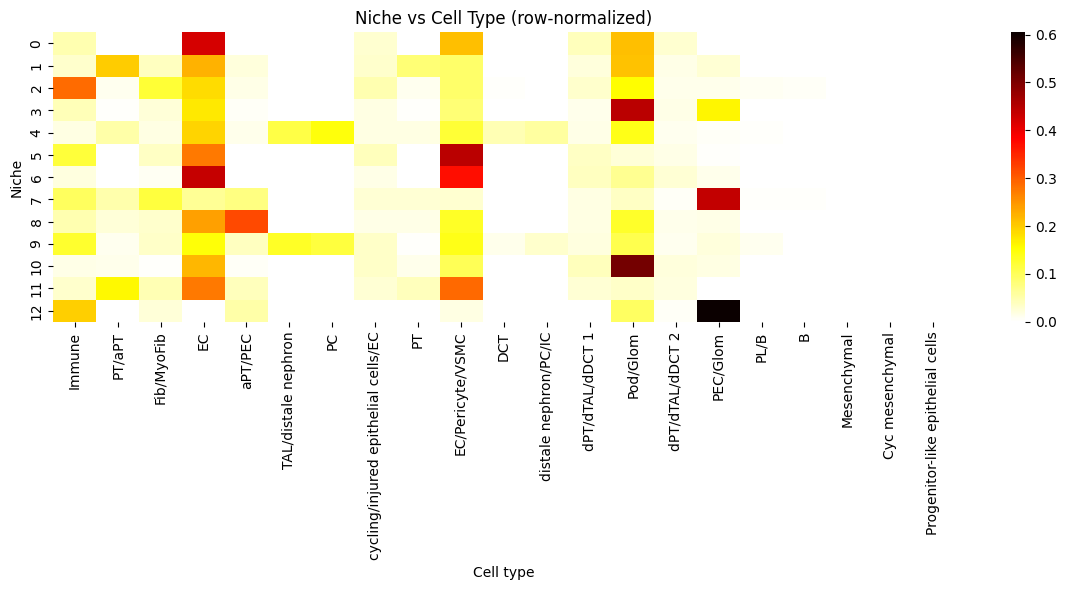

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

# 3.1 Cross-tab of niche vs cell type
ct = pd.crosstab(model.adata.obs[latent_cluster_key], model.adata.obs[cell_type_key], normalize="index")
plt.figure(figsize=(12, 6))
sns.heatmap(ct, cmap="hot_r", linewidths=0.0)
plt.title("Niche vs Cell Type (row-normalized)")
plt.xlabel("Cell type")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/niche_vs_celltype_heatmap.pdf")
plt.show()


In [53]:
import warnings

import scanpy as sc
import decoupler as dc

In [54]:
hallmark = dc.op.hallmark(organism="human")
hallmark

,source,target
0,IL2_STAT5_SIGNALING,MAFF
1,COAGULATION,MAFF
2,HYPOXIA,MAFF
3,TNFA_SIGNALING_VIA_NFKB,MAFF
4,COMPLEMENT,MAFF
...,...,...
7313,PANCREAS_BETA_CELLS,STXBP1
7314,PANCREAS_BETA_CELLS,ELP4
7315,PANCREAS_BETA_CELLS,GCG
7316,PANCREAS_BETA_CELLS,PCSK2


In [55]:
adata = dc.mt.ulm(data=model.adata, net=hallmark)

In [56]:
adata

AnnData object with n_obs × n_vars = 19910 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [57]:
score = dc.pp.get_obsm(adata=adata, key="score_ulm")
score

AnnData object with n_obs × n_vars = 19910 × 32
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule',

In [58]:
df = dc.tl.rankby_group(adata=score, groupby=latent_cluster_key, reference="rest", method="t-test_overestim_var")
df = df[df["stat"] > 0]
df

,group,reference,name,stat,meanchange,pval,padj
0,4,rest,KRAS_SIGNALING_DN,23.190326,0.467107,2.023872e-107,6.476390e-106
3,4,rest,ESTROGEN_RESPONSE_EARLY,14.446920,0.325263,7.785438e-46,6.228351e-45
5,4,rest,HYPOXIA,13.155955,0.391090,1.511677e-38,8.062277e-38
6,4,rest,ESTROGEN_RESPONSE_LATE,11.482815,0.254831,5.800090e-30,2.651470e-29
10,4,rest,APICAL_SURFACE,9.803791,0.338910,2.148210e-22,6.249338e-22
...,...,...,...,...,...,...,...
408,12,rest,APOPTOSIS,2.355081,0.197916,1.913318e-02,2.449047e-02
409,12,rest,ESTROGEN_RESPONSE_LATE,2.306877,0.151682,2.167776e-02,2.668032e-02
410,12,rest,IL2_STAT5_SIGNALING,2.210021,0.177551,2.778598e-02,3.293154e-02
412,12,rest,ALLOGRAFT_REJECTION,1.651427,0.213578,9.964742e-02,1.099558e-01


In [59]:
n_markers = 3
source_markers = (
    df.groupby("group")
    .head(n_markers)
    .drop_duplicates("name")
    .groupby("group")["name"]
    .apply(lambda x: list(x))
    .to_dict()
)
source_markers

{'0': ['UV_RESPONSE_DN', 'MTORC1_SIGNALING', 'KRAS_SIGNALING_UP'],
 '1': ['HEME_METABOLISM', 'UV_RESPONSE_UP'],
 '10': ['ANDROGEN_RESPONSE',
  'IL2_STAT5_SIGNALING',
  'EPITHELIAL_MESENCHYMAL_TRANSITION'],
 '11': [],
 '12': ['IL6_JAK_STAT3_SIGNALING'],
 '2': ['ALLOGRAFT_REJECTION',
  'INTERFERON_GAMMA_RESPONSE',
  'XENOBIOTIC_METABOLISM'],
 '3': [],
 '4': ['KRAS_SIGNALING_DN', 'ESTROGEN_RESPONSE_EARLY', 'HYPOXIA'],
 '5': ['TGF_BETA_SIGNALING', 'NOTCH_SIGNALING', 'APICAL_JUNCTION'],
 '6': [],
 '7': ['GLYCOLYSIS', 'COMPLEMENT', 'COAGULATION'],
 '8': ['INFLAMMATORY_RESPONSE'],
 '9': ['ESTROGEN_RESPONSE_LATE']}

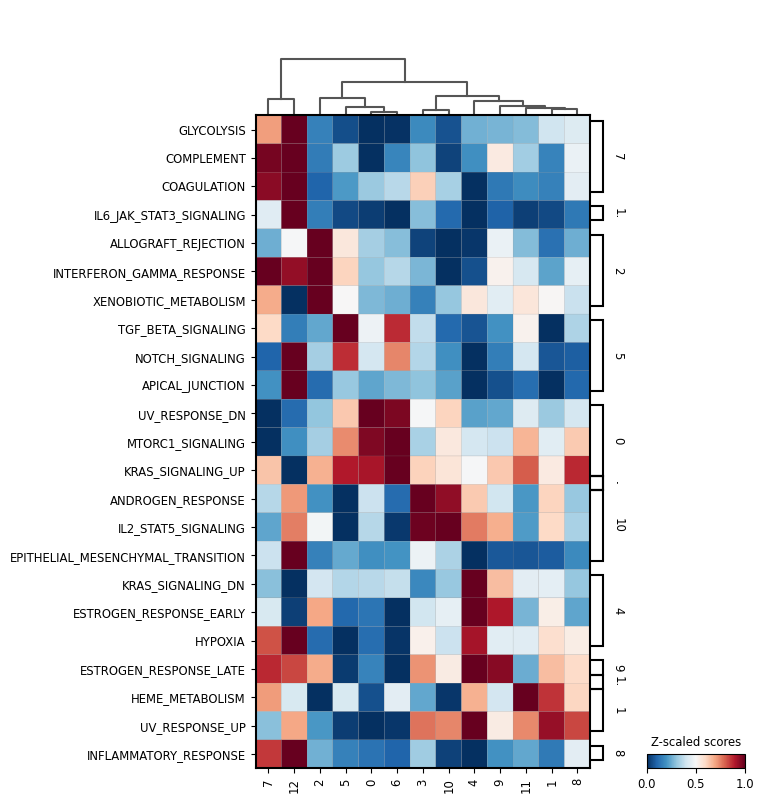

In [60]:
fig = sc.pl.matrixplot(
    adata=score,
    var_names=source_markers,
    groupby=latent_cluster_key,
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap="RdBu_r",
    swap_axes=True,
    return_fig=True
)

fig.savefig("/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/artifacts/single_sample/04092025_125840/figures/hallmark_marker_pathways.pdf")

In [61]:
list(dc.op.show_resources().name)

['Adhesome',
 'Almen2009',
 'Baccin2019',
 'CORUM_Funcat',
 'CORUM_GO',
 'CPAD',
 'CSPA',
 'CSPA_celltype',
 'CancerDrugsDB',
 'CancerGeneCensus',
 'CancerSEA',
 'CellCall',
 'CellCellInteractions',
 'CellChatDB',
 'CellChatDB_complex',
 'CellPhoneDB',
 'CellPhoneDB_complex',
 'CellTalkDB',
 'CellTypist',
 'Cellinker',
 'Cellinker_complex',
 'ComPPI',
 'CytoSig',
 'DGIdb',
 'DisGeNet',
 'EMBRACE',
 'Exocarta',
 'GO_Intercell',
 'GPCRdb',
 'Guide2Pharma',
 'HGNC',
 'HPA_secretome',
 'HPA_subcellular',
 'HPA_tissue',
 'HPMR',
 'HumanCellMap',
 'ICELLNET',
 'ICELLNET_complex',
 'IntOGen',
 'Integrins',
 'InterPro',
 'KEGG',
 'KEGG-PC',
 'Kirouac2010',
 'LOCATE',
 'LRdb',
 'Lambert2018',
 'MCAM',
 'MSigDB',
 'Matrisome',
 'MatrixDB',
 'Membranome',
 'NetPath',
 'OPM',
 'PROGENy',
 'PanglaoDB',
 'Phobius',
 'Phosphatome',
 'Ramilowski2015',
 'Ramilowski_location',
 'SIGNOR',
 'SignaLink_function',
 'SignaLink_pathway',
 'Surfaceome',
 'TCDB',
 'TFcensus',
 'TopDB',
 'UniProt_family',
 'UniP

In [62]:
markers = dc.op.resource(name="MSigDB")
markers

,genesymbol,collection,geneset
,,,
0,A1BG,reactome_pathways,REACTOME_HEMOSTASIS
1,A1BG,go_cellular_component,GOCC_PLATELET_ALPHA_GRANULE_LUMEN
2,A1BG,chemical_and_genetic_perturbations,CHENG_IMPRINTED_BY_ESTRADIOL
3,A1BG,immunesigdb,GSE13522_WT_VS_IFNG_KO_SKING_T_CRUZI_Y_STRAIN_...
4,A1BG,immunesigdb,GSE25088_CTRL_VS_IL4_AND_ROSIGLITAZONE_STIM_MA...
...,...,...,...
5895457,ZZZ3,mirna_targets_mirdb,MIR656_3P
5895458,ZZZ3,mirna_targets_mirdb,MIR513B_5P
5895459,ZZZ3,mirna_targets_mirdb,MIR449C_5P


In [63]:
markers.collection.unique()

array(['reactome_pathways', 'go_cellular_component',
       'chemical_and_genetic_perturbations', 'immunesigdb',
       'tf_targets_legacy', 'cell_type_signatures',
       'go_biological_process', 'positional', 'mirna_targets_mirdb',
       'tf_targets_gtrf', 'cancer_modules', 'vaccine_response',
       'go_molecular_function', 'oncogenic_signatures',
       'cancer_cell_atlas', 'hallmark', 'pid_pathways', 'kegg_pathways',
       'human_phenotype_ontology', 'wikipathways',
       'cancer_gene_neighborhoods', 'mirna_targets_legacy',
       'biocarta_pathways', 'kegg_medicus_pathways'], dtype=object)

In [64]:
# Filter by canonical_marker and human
markers = markers[
    markers["collection"].astype(str) == "reactome_pathways"    
]

# Remove duplicated entries
markers = markers[~markers.duplicated(["geneset", "genesymbol"])]

markers = markers.rename(columns={"geneset": "source", "genesymbol": "target"})
markers = markers[["source", "target"]]
markers

,source,target
,,
0,REACTOME_HEMOSTASIS,A1BG
5,REACTOME_RESPONSE_TO_ELEVATED_PLATELET_CYTOSOL...,A1BG
14,REACTOME_INNATE_IMMUNE_SYSTEM,A1BG
39,REACTOME_PLATELET_ACTIVATION_SIGNALING_AND_AGG...,A1BG
44,REACTOME_NEUTROPHIL_DEGRANULATION,A1BG
...,...,...
5895204,REACTOME_EPIGENETIC_REGULATION_BY_WDR5_CONTAIN...,ZZZ3
5895245,REACTOME_FORMATION_OF_WDR5_CONTAINING_HISTONE_...,ZZZ3
5895387,REACTOME_CHROMATIN_ORGANIZATION,ZZZ3


In [65]:
adata_molec = dc.mt.ulm(data=model.adata, net=markers)

In [66]:
adata_molec

AnnData object with n_obs × n_vars = 19910 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [67]:
score = dc.pp.get_obsm(adata=adata_molec, key="score_ulm")
score

AnnData object with n_obs × n_vars = 19910 × 160
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [68]:
df = dc.tl.rankby_group(adata=score, groupby=latent_cluster_key, reference="rest", method="t-test_overestim_var")
df = df[df["stat"] > 0]
df

,group,reference,name,stat,meanchange,pval,padj
0,4,rest,REACTOME_ION_CHANNEL_TRANSPORT,18.245341,0.371818,1.457906e-69,2.332649e-67
1,4,rest,REACTOME_TRANSPORT_OF_SMALL_MOLECULES,16.839674,0.495639,7.046050e-61,5.636840e-59
2,4,rest,REACTOME_SIGNALING_BY_INSULIN_RECEPTOR,16.084725,0.324674,2.265241e-55,1.208129e-53
4,4,rest,REACTOME_ASPARAGINE_N_LINKED_GLYCOSYLATION,14.099501,0.642398,1.672981e-43,5.353539e-42
25,4,rest,REACTOME_SIGNALING_BY_PTK6,9.664517,0.196559,8.182469e-22,5.035365e-21
...,...,...,...,...,...,...,...
2074,12,rest,REACTOME_INNATE_IMMUNE_SYSTEM,0.440051,0.051945,6.601964e-01,6.814931e-01
2075,12,rest,REACTOME_ASPARAGINE_N_LINKED_GLYCOSYLATION,0.392029,0.035002,6.953269e-01,7.131558e-01
2077,12,rest,REACTOME_O_LINKED_GLYCOSYLATION,0.294143,0.026290,7.688329e-01,7.785650e-01
2078,12,rest,REACTOME_SEMA3A_PLEXIN_REPULSION_SIGNALING_BY_...,0.196865,0.012053,8.440635e-01,8.493721e-01


In [69]:
n_markers = 3
source_markers = (
    df.groupby("group")
    .head(n_markers)
    .drop_duplicates("name")
    .groupby("group")["name"]
    .apply(lambda x: list(x))
    .to_dict()
)
source_markers

{'0': ['REACTOME_SIGNALING_BY_TGFBR3',
  'REACTOME_POST_TRANSLATIONAL_PROTEIN_MODIFICATION',
  'REACTOME_REGULATION_OF_INSULIN_LIKE_GROWTH_FACTOR_IGF_TRANSPORT_AND_UPTAKE_BY_INSULIN_LIKE_GROWTH_FACTOR_BINDING_PROTEINS_IGFBPS'],
 '1': ['REACTOME_SLC_MEDIATED_TRANSMEMBRANE_TRANSPORT',
  'REACTOME_TRANSPORT_OF_BILE_SALTS_AND_ORGANIC_ACIDS_METAL_IONS_AND_AMINE_COMPOUNDS',
  'REACTOME_TRANSPORT_OF_INORGANIC_CATIONS_ANIONS_AND_AMINO_ACIDS_OLIGOPEPTIDES'],
 '10': ['REACTOME_SIGNALING_BY_BMP',
  'REACTOME_SIGNALING_BY_TGFB_FAMILY_MEMBERS',
  'REACTOME_SIGNALING_BY_TGF_BETA_RECEPTOR_COMPLEX'],
 '11': [],
 '12': ['REACTOME_NERVOUS_SYSTEM_DEVELOPMENT',
  'REACTOME_INTERLEUKIN_4_AND_INTERLEUKIN_13_SIGNALING'],
 '2': ['REACTOME_DEVELOPMENTAL_CELL_LINEAGES_OF_THE_EXOCRINE_PANCREAS',
  'REACTOME_DEVELOPMENTAL_LINEAGE_OF_PANCREATIC_DUCTAL_CELLS',
  'REACTOME_ADAPTIVE_IMMUNE_SYSTEM'],
 '3': ['REACTOME_SIGNALING_BY_RECEPTOR_TYROSINE_KINASES',
  'REACTOME_NON_INTEGRIN_MEMBRANE_ECM_INTERACTIONS',
  'REACT

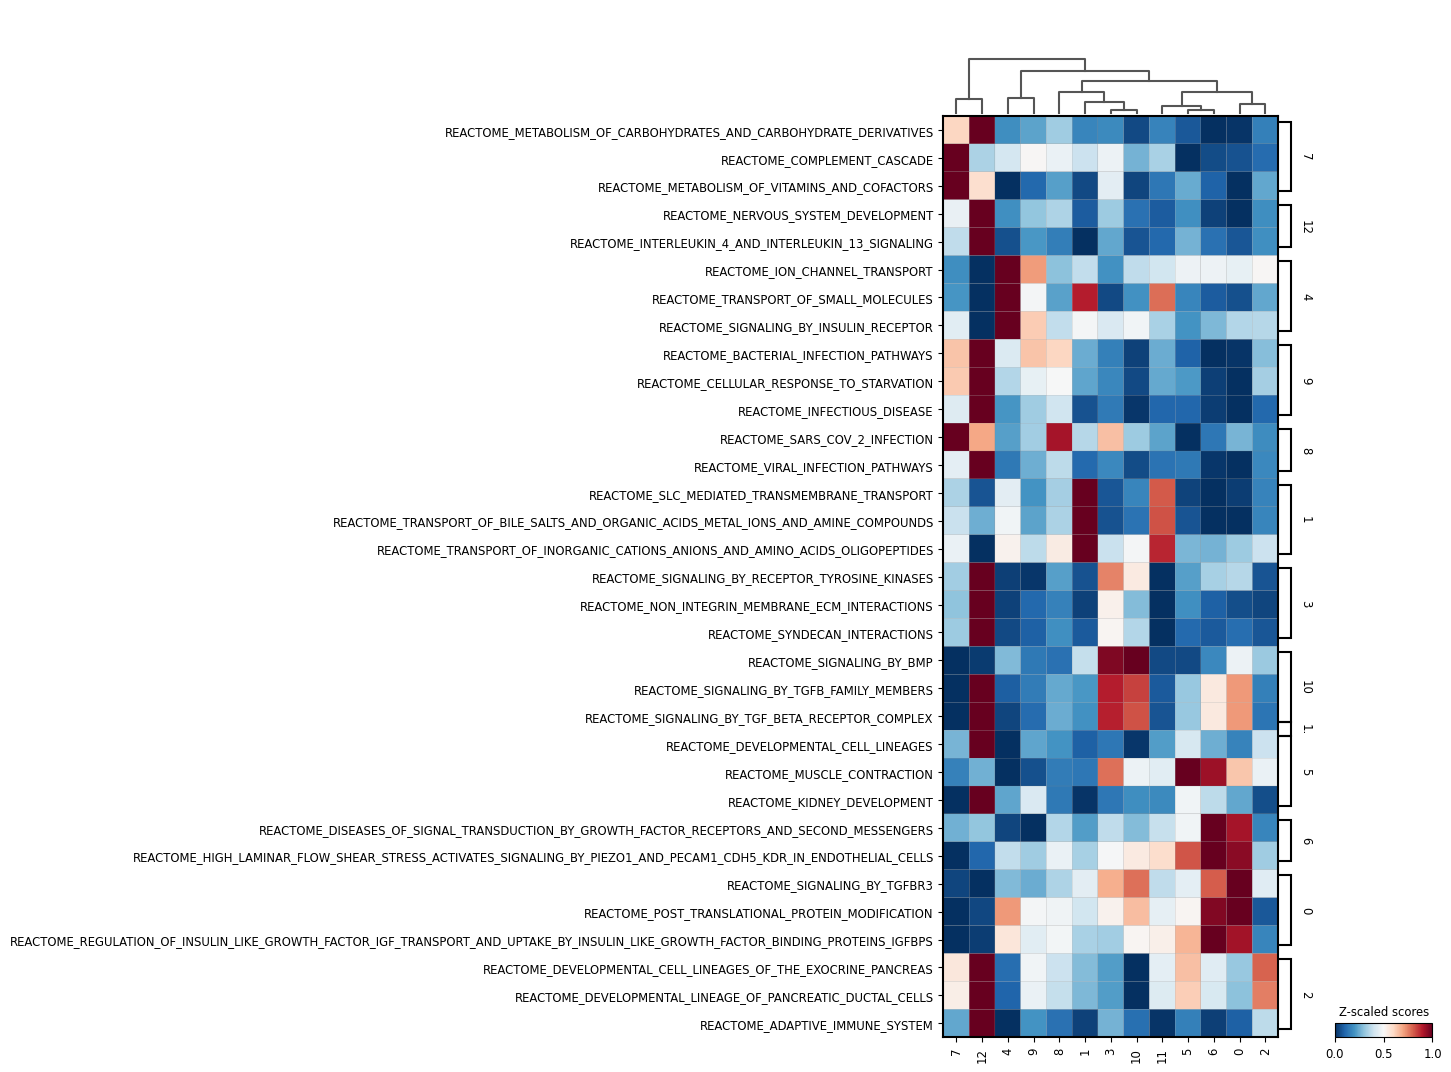

In [70]:
fig = sc.pl.matrixplot(
    adata=score,
    var_names=source_markers,
    groupby=latent_cluster_key,
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap="RdBu_r",
    swap_axes=True,
    return_fig=True
)

fig.savefig("/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/artifacts/single_sample/04092025_125840/figures/reactome_marker_pathways.pdf")

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc
import numpy as np


# Color map for niches
niche_colors = None
try:
    from nichecompass.utils import create_new_color_dict
    niche_colors = create_new_color_dict(adata=model.adata, cat_key=latent_cluster_key)
except Exception:
    pass

# Plot each TMA_ID in its own panel
tma_key = "TMA_ID"  # change if your column is named differently
tma_ids = model.adata.obs[tma_key].unique().tolist()

n_cols = 3
n_rows = int(np.ceil(len(tma_ids) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 5*n_rows))
axes = np.array(axes).reshape(n_rows, n_cols)

for i, tma in enumerate(tma_ids):
    r, c = divmod(i, n_cols)
    ax = axes[r, c]
    ad = model.adata[model.adata.obs[tma_key] == tma]
    sc.pl.spatial(
        adata=ad,
        color=[latent_cluster_key],
        palette=niche_colors,
        spot_size=spot_size,
        title=f"TMA_ID: {tma}",
        legend_loc=None,
        ax=ax,
        show=False
    )

# Remove any empty axes
for j in range(len(tma_ids), n_rows*n_cols):
    fig.delaxes(axes.flatten()[j])

plt.tight_layout()
plt.savefig(f"{figure_folder_path}/niches_per_TMA_ID.pdf", bbox_inches="tight")
plt.show()

In [82]:
adata

AnnData object with n_obs × n_vars = 19910 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [83]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, binomtest
from statsmodels.stats.multitest import multipletests
import scanpy as sc

In [84]:
# Set your keys:
condition_key = "condition"  # <-- change to your column name

# Quick checks
print("Conditions:", adata.obs[condition_key].unique().tolist())
print("Niches:", adata.obs[latent_cluster_key].unique().tolist())

Conditions: ['CTRL', 'FSGS', 'DN', 'TIN', 'MN', 'IgAN']
Niches: ['4', '10', '0', '7', '9', '1', '11', '2', '3', '8', '5', '6', '12']


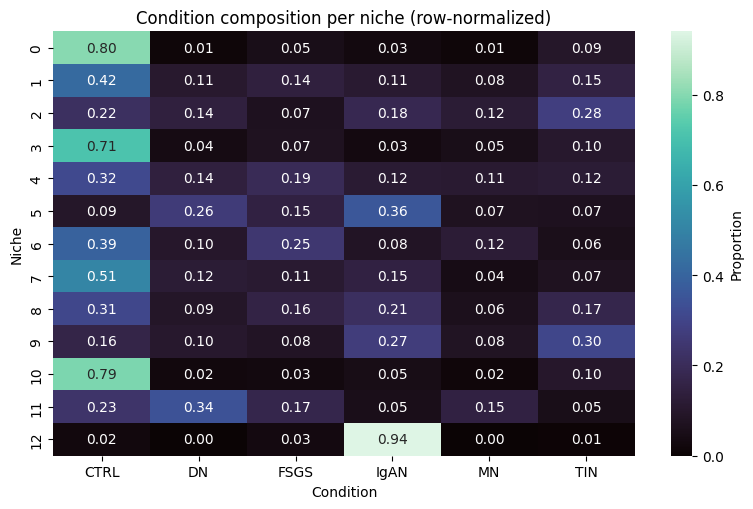

2025-09-04 13:25:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:25:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


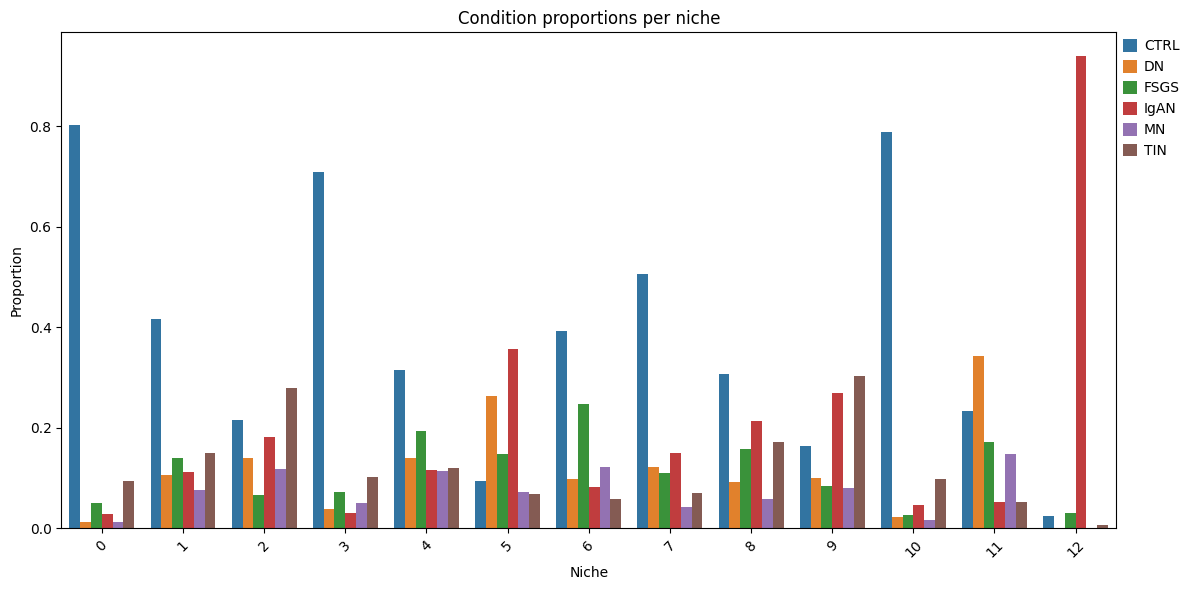

In [85]:
# Counts table
counts = pd.crosstab(adata.obs[latent_cluster_key], adata.obs[condition_key])
counts.index.name = "niche"
counts.columns.name = "condition"

# Proportions (row-normalized)
props = counts.div(counts.sum(axis=1), axis=0)

# Save
counts.to_csv(f"{figure_folder_path}/condition_counts_by_niche.csv")
props.to_csv(f"{figure_folder_path}/condition_proportions_by_niche.csv")

# Plot proportions heatmap
plt.figure(figsize=(max(8, 0.6*counts.shape[1]), max(4, 0.4*counts.shape[0])))
sns.heatmap(props, annot=True, fmt=".2f", cmap="mako", cbar_kws={"label":"Proportion"})
plt.title("Condition composition per niche (row-normalized)")
plt.xlabel("Condition")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/condition_proportions_by_niche_heatmap.pdf", bbox_inches="tight")
plt.show()

# Stacked barplot
props_plot = props.reset_index().melt(id_vars="niche", var_name="condition", value_name="proportion")
plt.figure(figsize=(12, 6))
sns.barplot(data=props_plot, x="niche", y="proportion", hue="condition")
plt.title("Condition proportions per niche")
plt.ylabel("Proportion")
plt.xlabel("Niche")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1,1))
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/condition_proportions_by_niche_stacked.pdf", bbox_inches="tight")
plt.show()

In [86]:
adata.obs.TMA_ID.unique()

['Appollo t0 E6 CTRL', 'Appollo t0 C6 CTRL', 'Appollo t0 F6 CTRL', 'Appollo t0 D2 CTRL', 'Appollo t0 E2 CTRL', ..., 'Utrecht1 A2 T19-14716 K49 MN', 'Utrecht1 A4 T19-12818 K48 MN', 'Utrecht1 D6 T13-04560 K107 MN', 'Utrecht1 C5 T15-19491 K45 MN', 'Utrecht1 C6 T15-11246 K6 DN']
Length: 84
Categories (84, object): ['Appollo d0 A1 CTRL', 'Appollo d0 A3 CTRL', 'Appollo d0 A4 CTRL', 'Appollo d0 B1 CTRL', ..., 'Utrecht2 F5 T04-20357 K82 FSGS', 'Utrecht 2 A3 T04-14807 K77 FSGS', 'Utrecht 2 B2 T19-13338 K27 TIN', 'Utrecht 2 B3 T19-01871 K8 DN']

In [87]:
obs = adata.obs[[latent_cluster_key, condition_key]].copy()
all_counts = obs[condition_key].value_counts()
N_total = len(obs)

# Global baseline probability for each condition
p_global = (all_counts / N_total).to_dict()

records = []
for niche, sub in obs.groupby(latent_cluster_key):
    n = len(sub)
    cond_counts = sub[condition_key].value_counts()
    for cond, k in cond_counts.items():
        p0 = p_global[cond]
        # one-sided test: enrichment (probability of >= k successes)
        bt = binomtest(k=k, n=n, p=p0, alternative="greater")
        records.append({"niche": niche, "condition": cond, "n": n, "k": k, "p0": p0, "p_binom": bt.pvalue,
                        "prop": k/n if n>0 else np.nan,
                        "prop_enrichment": (k/n - p0) if n>0 else np.nan})

binom_df = pd.DataFrame(records)
# Multiple testing correction across all niche-condition pairs
binom_df["p_adj"] = multipletests(binom_df["p_binom"], method="fdr_bh")[1]
binom_df = binom_df.sort_values(["p_adj", "prop_enrichment"], ascending=[True, False])
binom_df.to_csv(f"{figure_folder_path}/condition_enrichment_binomial.csv", index=False)
binom_df.head(15)

,niche,condition,n,k,p0,p_binom,prop,prop_enrichment,p_adj
0,0,CTRL,2240,1796,0.423104,6.630146e-295,0.801786,0.378682,5.171514e-293
60,10,CTRL,1332,1050,0.423104,3.482871e-163,0.788288,0.365184,1.358320e-161
18,3,CTRL,1756,1246,0.423104,4.986663e-130,0.709567,0.286463,1.296532e-128
72,12,IgAN,167,157,0.140181,8.448303e-120,0.940120,0.799939,1.647419e-118
30,5,IgAN,1662,593,0.140181,4.154102e-108,0.356799,0.216618,6.480399e-107
66,11,DN,1129,387,0.114766,3.931754e-90,0.342781,0.228015,5.111281e-89
54,9,TIN,1362,412,0.129382,1.136282e-62,0.302496,0.173114,1.266143e-61
12,2,TIN,1781,496,0.129382,1.718996e-62,0.278495,0.149113,1.676021e-61
31,5,DN,1662,437,0.114766,4.556717e-62,0.262936,0.148170,3.949155e-61
37,6,FSGS,1651,409,0.119940,2.367026e-46,0.247729,0.127789,1.846280e-45


In [88]:
records = []
for niche, sub in obs.groupby(latent_cluster_key):
    n = len(sub)
    for cond in obs[condition_key].unique():
        k = (sub[condition_key] == cond).sum()
        # Build 2x2: in-niche vs out-of-niche, cond vs not-cond
        rest = obs[obs[latent_cluster_key] != niche]
        a = k
        b = n - k
        c = (rest[condition_key] == cond).sum()
        d = len(rest) - c
        # one-sided greater (enrichment in niche)
        oddsratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        prop = k/n if n>0 else np.nan
        p0 = (c + a) / (len(rest) + n)
        records.append({"niche": niche, "condition": cond, "n": n, "k": k,
                        "oddsratio": oddsratio, "p_fisher": p,
                        "prop": prop, "p0": p0, "prop_enrichment": prop - p0})
fisher_df = pd.DataFrame(records)
fisher_df["p_adj"] = multipletests(fisher_df["p_fisher"], method="fdr_bh")[1]
fisher_df = fisher_df.sort_values(["p_adj", "oddsratio"], ascending=[True, False])
fisher_df.to_csv(f"{figure_folder_path}/condition_enrichment_fisher.csv", index=False)
fisher_df.head(15)

,niche,condition,n,k,oddsratio,p_fisher,prop,p0,prop_enrichment,p_adj
0,0,CTRL,2240,1796,6.738894,0.000000e+00,0.801786,0.423104,0.378682,0.000000e+00
60,10,CTRL,1332,1050,5.657312,1.418548e-174,0.788288,0.423104,0.365184,5.532336e-173
18,3,CTRL,1756,1246,3.735842,1.671830e-142,0.709567,0.423104,0.286463,4.346759e-141
77,12,IgAN,167,157,101.978474,1.933649e-121,0.940120,0.140181,0.799939,3.102336e-120
35,5,IgAN,1662,593,4.050646,1.988677e-121,0.356799,0.140181,0.216618,3.102336e-120
68,11,DN,1129,387,4.639386,6.203879e-98,0.342781,0.114766,0.228015,8.065043e-97
15,2,TIN,1781,496,2.978264,3.084963e-70,0.278495,0.129382,0.149113,3.437530e-69
32,5,DN,1662,437,3.165827,2.038538e-69,0.262936,0.114766,0.148170,1.987575e-68
57,9,TIN,1362,412,3.283495,1.312675e-68,0.302496,0.129382,0.173114,1.137652e-67
37,6,FSGS,1651,409,2.709008,1.655681e-51,0.247729,0.119940,0.127789,1.291431e-50


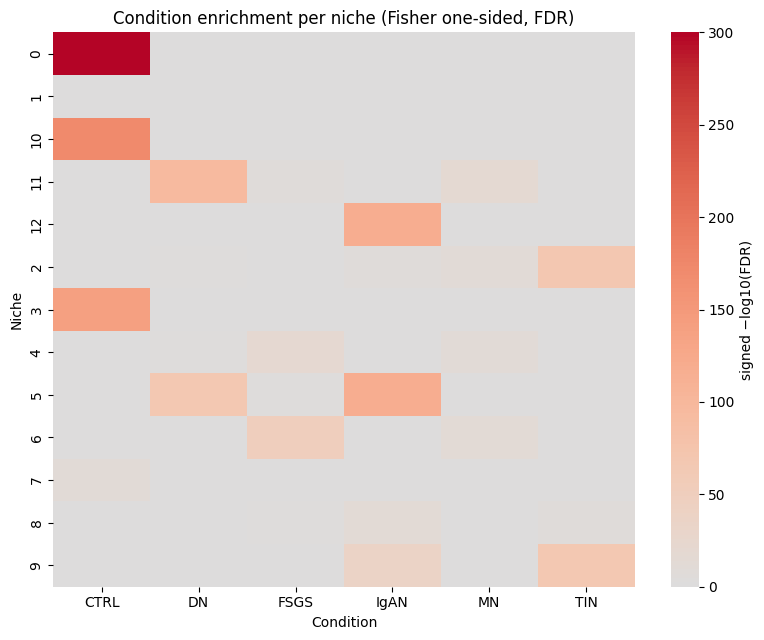

,niche,condition,n,k,oddsratio,p_fisher,prop,p0,prop_enrichment,p_adj,sign,neglog10_fdr,signed_score
0,0,CTRL,2240,1796,6.738894,0.000000e+00,0.801786,0.423104,0.378682,0.000000e+00,1.0,300.000000,300.000000
60,10,CTRL,1332,1050,5.657312,1.418548e-174,0.788288,0.423104,0.365184,5.532336e-173,1.0,172.257091,172.257091
18,3,CTRL,1756,1246,3.735842,1.671830e-142,0.709567,0.423104,0.286463,4.346759e-141,1.0,140.361834,140.361834
77,12,IgAN,167,157,101.978474,1.933649e-121,0.940120,0.140181,0.799939,3.102336e-120,1.0,119.508311,119.508311
35,5,IgAN,1662,593,4.050646,1.988677e-121,0.356799,0.140181,0.216618,3.102336e-120,1.0,119.508311,119.508311
68,11,DN,1129,387,4.639386,6.203879e-98,0.342781,0.114766,0.228015,8.065043e-97,1.0,96.093393,96.093393
15,2,TIN,1781,496,2.978264,3.084963e-70,0.278495,0.129382,0.149113,3.437530e-69,1.0,68.463753,68.463753
32,5,DN,1662,437,3.165827,2.038538e-69,0.262936,0.114766,0.148170,1.987575e-68,1.0,67.701676,67.701676
57,9,TIN,1362,412,3.283495,1.312675e-68,0.302496,0.129382,0.173114,1.137652e-67,1.0,66.943991,66.943991
37,6,FSGS,1651,409,2.709008,1.655681e-51,0.247729,0.119940,0.127789,1.291431e-50,1.0,49.888929,49.888929


In [89]:
# Use Fisher results for display (similar for binomial)
df = fisher_df.copy()
df["sign"] = np.sign(df["prop_enrichment"])
df["neglog10_fdr"] = -np.log10(df["p_adj"].clip(lower=1e-300))
df["signed_score"] = df["neglog10_fdr"] * df["sign"]

pivot = df.pivot(index="niche", columns="condition", values="signed_score").fillna(0)

plt.figure(figsize=(max(8, 0.6*pivot.shape[1]), max(4, 0.5*pivot.shape[0])))
sns.heatmap(pivot, cmap="coolwarm", center=0, cbar_kws={"label":"signed −log10(FDR)"})
plt.title("Condition enrichment per niche (Fisher one-sided, FDR)")
plt.xlabel("Condition")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/condition_enrichment_signedlog10fdr_heatmap.pdf", bbox_inches="tight")
plt.show()

# List significant niche-condition pairs
sig = df[df["p_adj"] < 0.05].sort_values(["p_adj", "oddsratio"], ascending=[True, False])
sig.to_csv(f"{figure_folder_path}/condition_enriched_pairs_fdr05.csv", index=False)
sig.head(20)

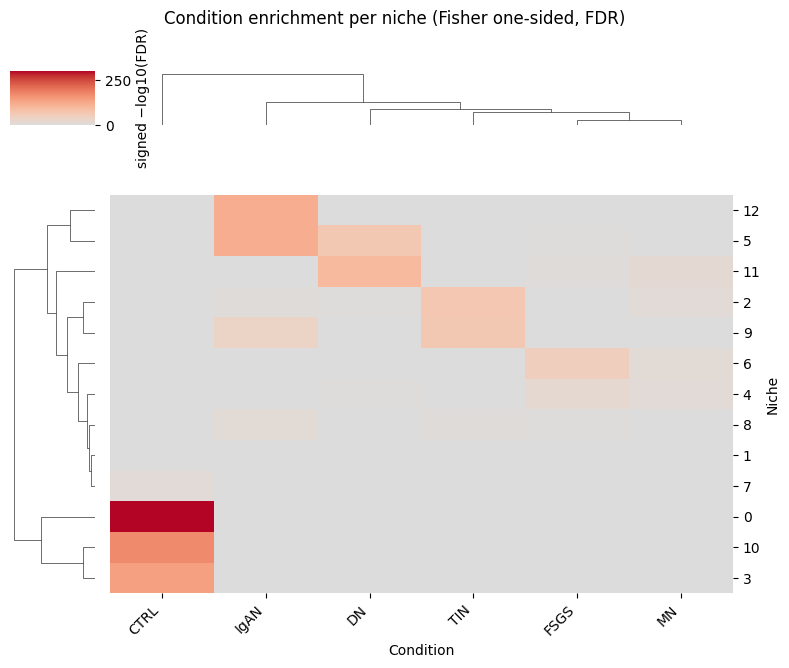

In [90]:
# Compute pivot as before
#df = fisher_df.copy()
df["sign"] = np.sign(df["prop_enrichment"])
df["neglog10_fdr"] = -np.log10(df["p_adj"].clip(lower=1e-300))
df["signed_score"] = df["neglog10_fdr"] * df["sign"]

pivot = df.pivot(index="niche", columns="condition", values="signed_score").fillna(0)

# Use clustermap instead of heatmap
g = sns.clustermap(
    pivot,
    cmap="coolwarm",
    center=0,
    row_cluster=True,    # set False to keep original row order
    col_cluster=True,    # set False to keep original column order
    figsize=(max(8, 0.6*pivot.shape[1]), max(6, 0.5*pivot.shape[0])),
    dendrogram_ratio=0.12,      # adjust dendrogram vs heatmap space
    cbar_pos=(0.02, 0.8, 0.03, 0.15),  # x, y, w, h (fraction of figure); tweak as needed
    cbar_kws={"label": "signed −log10(FDR)"},
    xticklabels=True,
    yticklabels=True,
    linewidths=0,  # optional
)

# Rotate x tick labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)

# Title and axis labels (clustermap returns a Figure embedded in g.fig)
g.ax_heatmap.set_xlabel("Condition")
g.ax_heatmap.set_ylabel("Niche")
g.fig.suptitle("Condition enrichment per niche (Fisher one-sided, FDR)", y=1.02)

# Tight layout and save
g.fig.tight_layout()
g.fig.savefig(f"{figure_folder_path}/condition_enrichment_signedlog10fdr_clustermap.pdf",
              bbox_inches="tight")
plt.show()



In [113]:
import re
import pandas as pd

# 1) Helper functions
def normalize_key(x: str) -> str | None:
    """Normalize keys to a canonical form for matching."""
    if x is None:
        return None
    x = str(x).strip()
    if x == "" or x.lower() == "na":
        return None
    # Remove spaces
    x = re.sub(r"\s+", "", x)
    # If pure K-number variants like K094 or k 94 → K94
    m = re.fullmatch(r"(?i)K0*(\d+)", x)
    if m:
        return f"K{int(m.group(1))}"
    # If Apollo variants: Apollot0_A01, apollo d0 a1, apollod0A1 → APOLLOT0_A1 / APOLLOD0_A1
    m = re.fullmatch(r"(?i)(APOLLO[TD]0)_?([A-H])0*(\d+)", x)
    if m:
        base = m.group(1).upper()        # APOLLOT0 or APOLLOD0
        well = f"{m.group(2).upper()}{int(m.group(3))}"  # A1, B6, etc.
        return f"{base}_{well}"
    # General cleanup and uppercase (keeps underscores)
    return x.upper()

def derive_join_key_from_tma(tma_id: str) -> str | None:
    """Derive a normalized join key from a TMA_ID string."""
    if not isinstance(tma_id, str):
        return None
    s = tma_id

    # 1) If there's a K-number anywhere, prefer that (e.g., Utrecht1 ... K26 TIN → K26)
    m = re.search(r"\bK\s*0*(\d+)\b", s, flags=re.IGNORECASE)
    if m:
        return normalize_key(f"K{int(m.group(1))}")

    # 2) Apollo t0/d0 + well code (letter+number), e.g., "Appollo t0 F6 CTRL" → Apollot0_F6
    stage = None
    if re.search(r"\bt\s*0\b", s, flags=re.IGNORECASE):
        stage = "APOLLOT0"
    elif re.search(r"\bd\s*0\b", s, flags=re.IGNORECASE):
        stage = "APOLLOD0"

    m = re.search(r"\b([A-H])\s*0*(\d+)\b", s, flags=re.IGNORECASE)
    if stage and m:
        well = f"{m.group(1).upper()}{int(m.group(2))}"
        return f"{stage}_{well}"

    return None

# 2) Read supplemental CSV (semicolon-separated, first row is a title)
supp_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/Supplemental.csv"
meta = pd.read_csv(supp_path, sep=";", skiprows=1, dtype=str)

# Drop stray unnamed first column if present (looks like row numbers 1,2,... in your sample)
if meta.columns[0].startswith("Unnamed") or meta.columns[0] == "":
    meta = meta.drop(columns=meta.columns[0])

# Clean whitespace in column names and values
meta.columns = [c.strip() for c in meta.columns]
meta = meta.applymap(lambda x: x.strip() if isinstance(x, str) else x)

# 3) Build an alias → row-index map from several possible columns
possible_alias_cols = [c for c in ["sample_ID", "ck_number_rna", "ck_number_atac", "patient_ID"] if c in meta.columns]
aliases = []
for ridx, row in meta.iterrows():
    for c in possible_alias_cols:
        alias = normalize_key(row[c])
        if alias is not None:
            aliases.append({"alias": alias, "meta_idx": ridx})

aliases_df = pd.DataFrame(aliases)
# Keep first occurrence if duplicates; warn if duplicates exist
dups = aliases_df["alias"].duplicated(keep=False)
if dups.any():
    dup_aliases = aliases_df.loc[dups, "alias"].unique().tolist()
    print(f"Warning: duplicate aliases in metadata for {len(dup_aliases)} keys. Using first occurrence:\n{dup_aliases[:20]}{' ...' if len(dup_aliases)>20 else ''}")

aliases_df = aliases_df.drop_duplicates(subset="alias", keep="first")
alias_to_metaidx = aliases_df.set_index("alias")["meta_idx"]

# 4) Derive join keys from adata.obs['TMA_ID'] and map to metadata rows
# Assumes you already have 'adata' loaded and adata.obs['TMA_ID'] present
def attach_supplemental_to_adata(adata, meta_df, alias_to_metaidx, prefix="supp_"):
    if "TMA_ID" not in adata.obs.columns:
        raise KeyError("adata.obs must contain a 'TMA_ID' column.")

    join_keys = adata.obs["TMA_ID"].apply(derive_join_key_from_tma)
    # Map to metadata row indices
    meta_idx_series = join_keys.map(alias_to_metaidx)

    # Build a DataFrame aligned to adata.obs.index with supplemental columns
    supp_cols = [c for c in meta_df.columns]  # keep all columns
    out = pd.DataFrame(index=adata.obs.index, columns=[prefix + c for c in supp_cols])

    mask = meta_idx_series.notna()
    if mask.any():
        # meta_df.loc[indices] will return rows in the order of indices
        matched_meta = meta_df.loc[meta_idx_series[mask].astype(int)].set_index(adata.obs.index[mask])
        out.loc[mask, :] = matched_meta.rename(columns=lambda c: prefix + c)

    # Attach to adata.obs
    adata.obs = pd.concat([adata.obs, out], axis=1)

    # Simple report
    n_matched = int(mask.sum())
    n_total = adata.n_obs
    print(f"Matched {n_matched}/{n_total} observations "
          f"({n_matched/n_total:.1%}). Unmatched: {n_total - n_matched}.")

    # Optionally, inspect a few unmatched TMA_IDs
    unmatched_examples = adata.obs.loc[~mask, "TMA_ID"].dropna().unique().tolist()[:20]
    if len(unmatched_examples) > 0:
        print("Examples of unmatched TMA_IDs (first 20):")
        for u in unmatched_examples:
            print(" -", u)

# 5) Run the attachment
# from anndata import AnnData  # if needed
# import scanpy as sc          # if using Scanpy
attach_supplemental_to_adata(adata, meta, alias_to_metaidx, prefix="supp_")

['APOLLOT0_A1', 'NAN', 'APOLLOT0_A3', 'APOLLOT0_A4', 'APOLLOT0_B1', 'APOLLOT0_B2', 'APOLLOT0_B3', 'APOLLOT0_B4', 'APOLLOT0_B5', 'APOLLOT0_B6', 'APOLLOT0_C1', 'APOLLOT0_C2', 'APOLLOT0_C3', 'APOLLOT0_C4', 'APOLLOT0_C5', 'APOLLOT0_C6', 'APOLLOT0_D1', 'APOLLOT0_D2', 'APOLLOT0_D3', 'APOLLOT0_D4'] ...
Matched 17231/19924 observations (86.5%). Unmatched: 2693.
Examples of unmatched TMA_IDs (first 20):
 - Appollo d0 B1 CTRL
 - Appollo d0 C1 CTRL
 - Appollo d0 A1 CTRL
 - Appollo d0 B2 CTRL
 - Appollo d0 B4 CTRL
 - Appollo d0 A4 CTRL
 - Appollo d0 B5 CTRL
 - Appollo d0 B6 CTRL
 - Appollo d0 B3 CTRL
 - Appollo d0 A3 CTRL


In [92]:
adata

AnnData object with n_obs × n_vars = 19910 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

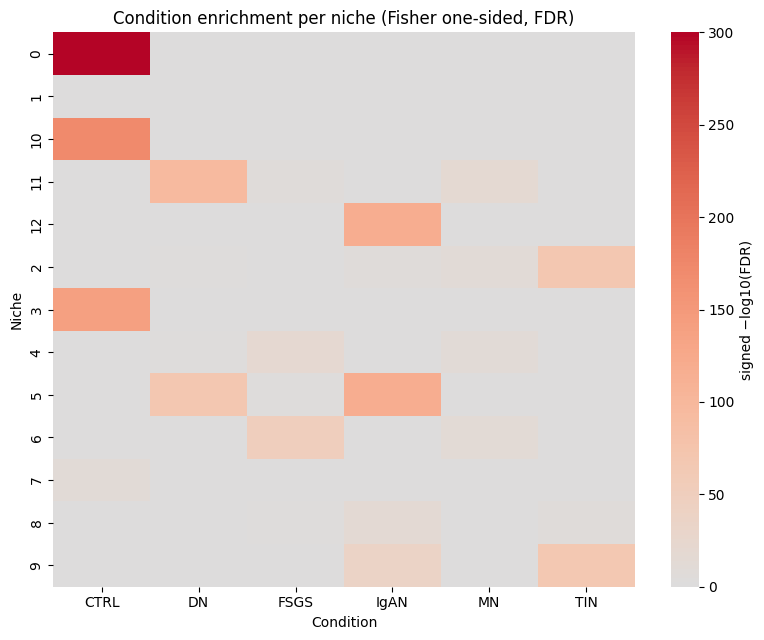

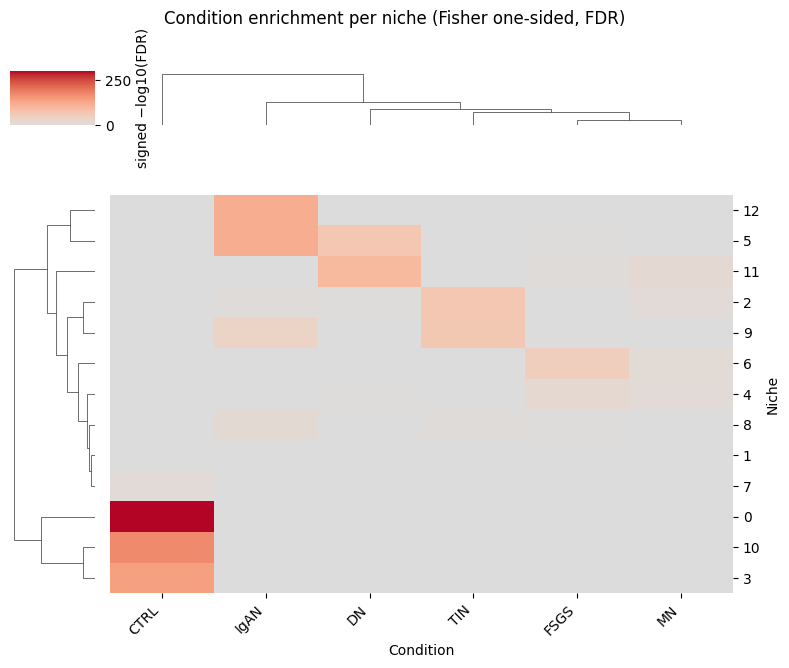

In [114]:
obs = adata.obs[[latent_cluster_key, condition_key]].copy()
all_counts = obs[condition_key].value_counts()
N_total = len(obs)

# Global baseline probability for each condition
p_global = (all_counts / N_total).to_dict()

records = []
for niche, sub in obs.groupby(latent_cluster_key):
    n = len(sub)
    cond_counts = sub[condition_key].value_counts()
    for cond, k in cond_counts.items():
        p0 = p_global[cond]
        # one-sided test: enrichment (probability of >= k successes)
        bt = binomtest(k=k, n=n, p=p0, alternative="greater")
        records.append({"niche": niche, "condition": cond, "n": n, "k": k, "p0": p0, "p_binom": bt.pvalue,
                        "prop": k/n if n>0 else np.nan,
                        "prop_enrichment": (k/n - p0) if n>0 else np.nan})

binom_df = pd.DataFrame(records)
# Multiple testing correction across all niche-condition pairs
binom_df["p_adj"] = multipletests(binom_df["p_binom"], method="fdr_bh")[1]
binom_df = binom_df.sort_values(["p_adj", "prop_enrichment"], ascending=[True, False])
binom_df.to_csv(f"{figure_folder_path}/condition_enrichment_binomial.csv", index=False)
binom_df.head(15)

records = []
for niche, sub in obs.groupby(latent_cluster_key):
    n = len(sub)
    for cond in obs[condition_key].unique():
        k = (sub[condition_key] == cond).sum()
        # Build 2x2: in-niche vs out-of-niche, cond vs not-cond
        rest = obs[obs[latent_cluster_key] != niche]
        a = k
        b = n - k
        c = (rest[condition_key] == cond).sum()
        d = len(rest) - c
        # one-sided greater (enrichment in niche)
        oddsratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
        prop = k/n if n>0 else np.nan
        p0 = (c + a) / (len(rest) + n)
        records.append({"niche": niche, "condition": cond, "n": n, "k": k,
                        "oddsratio": oddsratio, "p_fisher": p,
                        "prop": prop, "p0": p0, "prop_enrichment": prop - p0})
fisher_df = pd.DataFrame(records)
fisher_df["p_adj"] = multipletests(fisher_df["p_fisher"], method="fdr_bh")[1]
fisher_df = fisher_df.sort_values(["p_adj", "oddsratio"], ascending=[True, False])
fisher_df.to_csv(f"{figure_folder_path}/condition_enrichment_fisher.csv", index=False)
fisher_df.head(15)

# Use Fisher results for display (similar for binomial)
df = fisher_df.copy()
df["sign"] = np.sign(df["prop_enrichment"])
df["neglog10_fdr"] = -np.log10(df["p_adj"].clip(lower=1e-300))
df["signed_score"] = df["neglog10_fdr"] * df["sign"]

pivot = df.pivot(index="niche", columns="condition", values="signed_score").fillna(0)

plt.figure(figsize=(max(8, 0.6*pivot.shape[1]), max(4, 0.5*pivot.shape[0])))
sns.heatmap(pivot, cmap="coolwarm", center=0, cbar_kws={"label":"signed −log10(FDR)"})
plt.title("Condition enrichment per niche (Fisher one-sided, FDR)")
plt.xlabel("Condition")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/condition_enrichment_signedlog10fdr_heatmap.pdf", bbox_inches="tight")
plt.show()

# List significant niche-condition pairs
sig = df[df["p_adj"] < 0.05].sort_values(["p_adj", "oddsratio"], ascending=[True, False])
sig.to_csv(f"{figure_folder_path}/condition_enriched_pairs_fdr05.csv", index=False)
sig.head(20)

# Compute pivot as before
#df = fisher_df.copy()
df["sign"] = np.sign(df["prop_enrichment"])
df["neglog10_fdr"] = -np.log10(df["p_adj"].clip(lower=1e-300))
df["signed_score"] = df["neglog10_fdr"] * df["sign"]

pivot = df.pivot(index="niche", columns="condition", values="signed_score").fillna(0)

# Use clustermap instead of heatmap
g = sns.clustermap(
    pivot,
    cmap="coolwarm",
    center=0,
    row_cluster=True,    # set False to keep original row order
    col_cluster=True,    # set False to keep original column order
    figsize=(max(8, 0.6*pivot.shape[1]), max(6, 0.5*pivot.shape[0])),
    dendrogram_ratio=0.12,      # adjust dendrogram vs heatmap space
    cbar_pos=(0.02, 0.8, 0.03, 0.15),  # x, y, w, h (fraction of figure); tweak as needed
    cbar_kws={"label": "signed −log10(FDR)"},
    xticklabels=True,
    yticklabels=True,
    linewidths=0,  # optional
)

# Rotate x tick labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)

# Title and axis labels (clustermap returns a Figure embedded in g.fig)
g.ax_heatmap.set_xlabel("Condition")
g.ax_heatmap.set_ylabel("Niche")
g.fig.suptitle("Condition enrichment per niche (Fisher one-sided, FDR)", y=1.02)

# Tight layout and save
g.fig.tight_layout()
g.fig.savefig(f"{figure_folder_path}/condition_enrichment_signedlog10fdr_clustermap.pdf",
              bbox_inches="tight")
plt.show()



In [118]:
import re
import pandas as pd

# 1) Helper functions
def normalize_key(x: str) -> str | None:
    """Normalize keys to a canonical form for matching."""
    if x is None:
        return None
    x = str(x).strip()
    if x == "" or x.lower() == "na":
        return None
    # Remove spaces
    x = re.sub(r"\s+", "", x)
    # If pure K-number variants like K094 or k 94 → K94
    m = re.fullmatch(r"(?i)K0*(\d+)", x)
    if m:
        return f"K{int(m.group(1))}"
    # If Apollo variants: Apollot0_A01, apollo d0 a1, apollod0A1 → APOLLOT0_A1 / APOLLOD0_A1
    m = re.fullmatch(r"(?i)(APOLLO[TD]0)_?([A-H])0*(\d+)", x)
    if m:
        base = m.group(1).upper()        # APOLLOT0 or APOLLOD0
        well = f"{m.group(2).upper()}{int(m.group(3))}"  # A1, B6, etc.
        return f"{base}_{well}"
    # General cleanup and uppercase (keeps underscores)
    return x.upper()

def derive_join_key_from_tma(tma_id: str) -> str | None:
    """Derive a normalized join key from a TMA_ID string."""
    if not isinstance(tma_id, str):
        return None
    s = tma_id

    # 1) If there's a K-number anywhere, prefer that (e.g., Utrecht1 ... K26 TIN → K26)
    m = re.search(r"\bK\s*0*(\d+)\b", s, flags=re.IGNORECASE)
    if m:
        return normalize_key(f"K{int(m.group(1))}")

    # 2) Apollo t0/d0 + well code (letter+number), e.g., "Appollo t0 F6 CTRL" → Apollot0_F6
    stage = None
    if re.search(r"\bt\s*0\b", s, flags=re.IGNORECASE):
        stage = "APOLLOT0"
    elif re.search(r"\bd\s*0\b", s, flags=re.IGNORECASE):
        stage = "APOLLOD0"

    m = re.search(r"\b([A-H])\s*0*(\d+)\b", s, flags=re.IGNORECASE)
    if stage and m:
        well = f"{m.group(1).upper()}{int(m.group(2))}"
        return f"{stage}_{well}"

    return None

# 2) Read supplemental CSV (semicolon-separated, first row is a title)
supp_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/Supplemental.csv"
meta = pd.read_csv(supp_path, sep=";", skiprows=1, dtype=str)

# Drop stray unnamed first column if present (looks like row numbers 1,2,... in your sample)
if meta.columns[0].startswith("Unnamed") or meta.columns[0] == "":
    meta = meta.drop(columns=meta.columns[0])

# Clean whitespace in column names and values
meta.columns = [c.strip() for c in meta.columns]
meta = meta.applymap(lambda x: x.strip() if isinstance(x, str) else x)

# 3) Build an alias → row-index map from several possible columns
possible_alias_cols = [c for c in ["sample_ID", "ck_number_rna", "ck_number_atac", "patient_ID"] if c in meta.columns]
aliases = []
for ridx, row in meta.iterrows():
    for c in possible_alias_cols:
        alias = normalize_key(row[c])
        if alias is not None:
            aliases.append({"alias": alias, "meta_idx": ridx})

aliases_df = pd.DataFrame(aliases)
# Keep first occurrence if duplicates; warn if duplicates exist
dups = aliases_df["alias"].duplicated(keep=False)
if dups.any():
    dup_aliases = aliases_df.loc[dups, "alias"].unique().tolist()
    print(f"Warning: duplicate aliases in metadata for {len(dup_aliases)} keys. Using first occurrence:\n{dup_aliases[:20]}{' ...' if len(dup_aliases)>20 else ''}")

aliases_df = aliases_df.drop_duplicates(subset="alias", keep="first")
alias_to_metaidx = aliases_df.set_index("alias")["meta_idx"]

# 4) Derive join keys from adata.obs['TMA_ID'] and map to metadata rows
# Assumes you already have 'adata' loaded and adata.obs['TMA_ID'] present
def attach_supplemental_to_adata(adata, meta_df, alias_to_metaidx, prefix="supp_"):
    if "TMA_ID" not in adata.obs.columns:
        raise KeyError("adata.obs must contain a 'TMA_ID' column.")

    join_keys = adata.obs["TMA_ID"].apply(derive_join_key_from_tma)
    # Map to metadata row indices
    meta_idx_series = join_keys.map(alias_to_metaidx)

    # Build a DataFrame aligned to adata.obs.index with supplemental columns
    supp_cols = [c for c in meta_df.columns]  # keep all columns
    out = pd.DataFrame(index=adata.obs.index, columns=[prefix + c for c in supp_cols])

    mask = meta_idx_series.notna()
    if mask.any():
        # meta_df.loc[indices] will return rows in the order of indices
        matched_meta = meta_df.loc[meta_idx_series[mask].astype(int)].set_index(adata.obs.index[mask])
        out.loc[mask, :] = matched_meta.rename(columns=lambda c: prefix + c)

    # Attach to adata.obs
    adata.obs = pd.concat([adata.obs, out], axis=1)

    # Simple report
    n_matched = int(mask.sum())
    n_total = adata.n_obs
    print(f"Matched {n_matched}/{n_total} observations "
          f"({n_matched/n_total:.1%}). Unmatched: {n_total - n_matched}.")

    # Optionally, inspect a few unmatched TMA_IDs
    unmatched_examples = adata.obs.loc[~mask, "TMA_ID"].dropna().unique().tolist()[:20]
    if len(unmatched_examples) > 0:
        print("Examples of unmatched TMA_IDs (first 20):")
        for u in unmatched_examples:
            print(" -", u)

# 5) Run the attachment
# from anndata import AnnData  # if needed
# import scanpy as sc          # if using Scanpy
attach_supplemental_to_adata(adata, meta, alias_to_metaidx, prefix="supp_")

['APOLLOT0_A1', 'NAN', 'APOLLOT0_A3', 'APOLLOT0_A4', 'APOLLOT0_B1', 'APOLLOT0_B2', 'APOLLOT0_B3', 'APOLLOT0_B4', 'APOLLOT0_B5', 'APOLLOT0_B6', 'APOLLOT0_C1', 'APOLLOT0_C2', 'APOLLOT0_C3', 'APOLLOT0_C4', 'APOLLOT0_C5', 'APOLLOT0_C6', 'APOLLOT0_D1', 'APOLLOT0_D2', 'APOLLOT0_D3', 'APOLLOT0_D4'] ...
Matched 17231/19924 observations (86.5%). Unmatched: 2693.
Examples of unmatched TMA_IDs (first 20):
 - Appollo d0 B1 CTRL
 - Appollo d0 C1 CTRL
 - Appollo d0 A1 CTRL
 - Appollo d0 B2 CTRL
 - Appollo d0 B4 CTRL
 - Appollo d0 A4 CTRL
 - Appollo d0 B5 CTRL
 - Appollo d0 B6 CTRL
 - Appollo d0 B3 CTRL
 - Appollo d0 A3 CTRL


In [95]:
adata

AnnData object with n_obs × n_vars = 19910 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

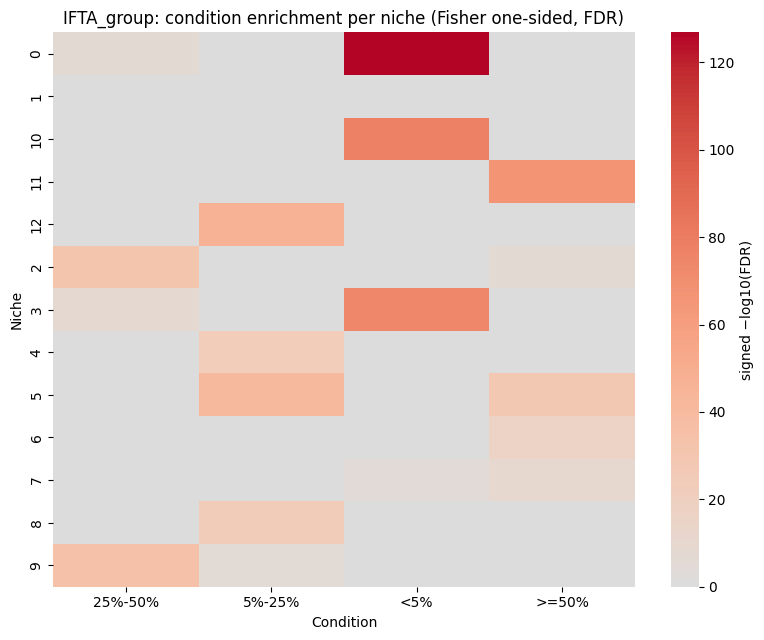

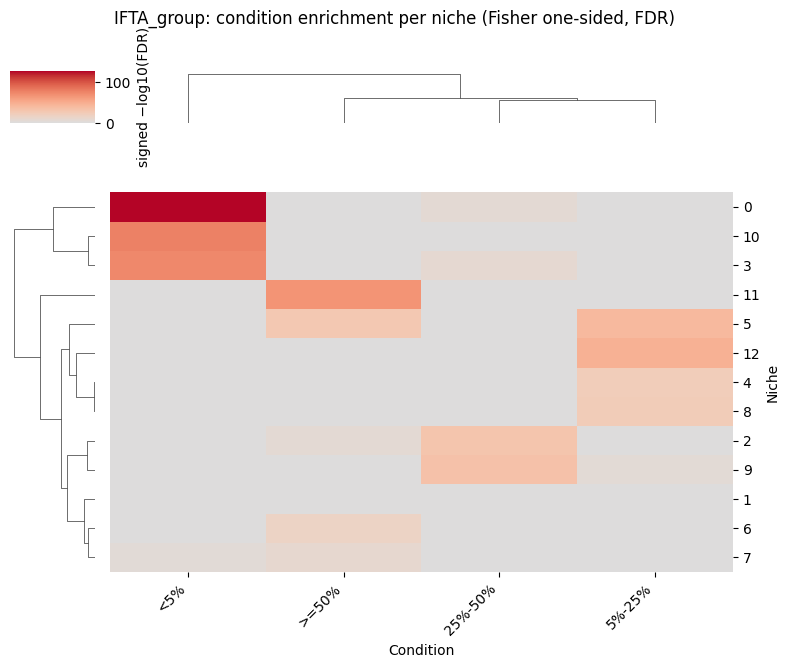

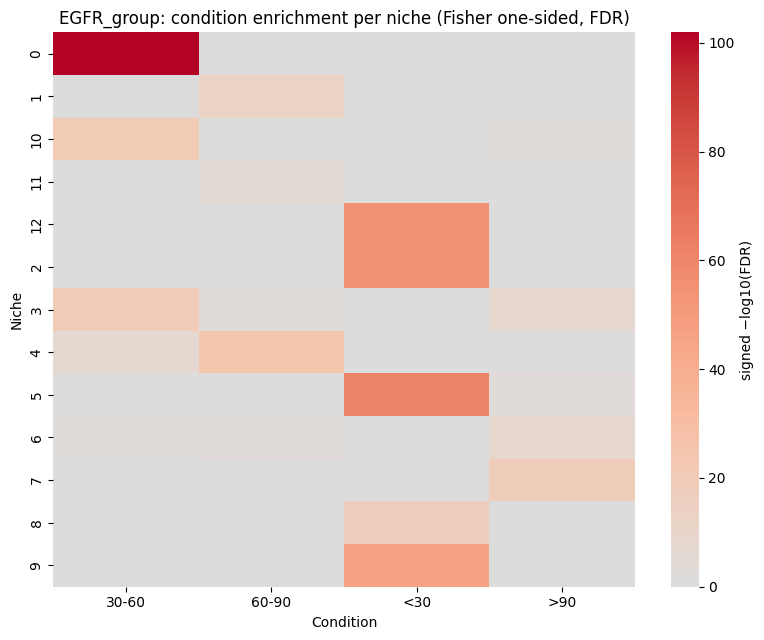

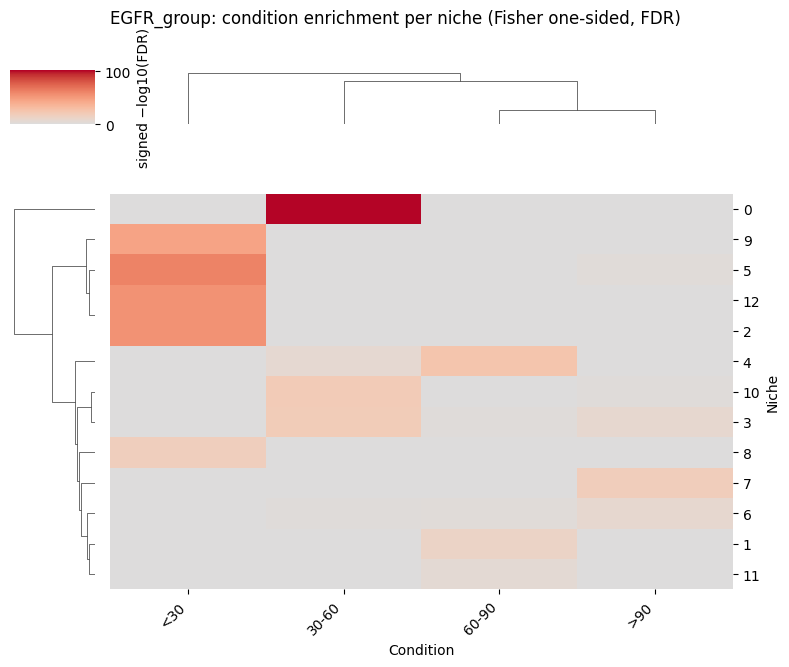

AttributeError: 'DataFrame' object has no attribute 'dtype'

In [129]:
# Imports
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import binomtest, fisher_exact
from statsmodels.stats.multitest import multipletests

# -----------------------------
# 1) Parsers
# -----------------------------
def parse_ifta_to_pct(x, treat_one_as_percent=False):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    s = str(x).strip()
    if s == "" or s.lower() == "na":
        return np.nan
    s = s.replace(",", ".").replace("%", "")

    # Handle "<5" or "≤5"
    m = re.match(r"^\s*[<≤]\s*(\d+(\.\d+)?)\s*$", s)
    if m:
        val = float(m.group(1))
        return max(val - 1e-3, 0.0)

    # Plain number
    try:
        val = float(s)
    except Exception:
        return np.nan

    if val > 1.0:
        pct = val
    elif val < 1.0:
        pct = val * 100.0
    else:
        pct = 1.0 if treat_one_as_percent else 1.0

    if not np.isfinite(pct) or pct < 0 or pct > 100:
        return np.nan
    return pct

def parse_numeric(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    s = str(x).strip()
    if s == "" or s.lower() == "na":
        return np.nan
    s = s.replace(",", ".")
    try:
        return float(s)
    except Exception:
        return np.nan

# -----------------------------
# 1b) Extract and assign clean IFTA_pct and EGFR
# -----------------------------
# Handle the strange 3-column "supp_IFTA" by collapsing to 1D first
if "supp_IFTA" in adata.obs.columns:
    s_raw = adata.obs["supp_IFTA"]

    # If it's a DataFrame with multiple identical columns named "supp_IFTA", pick the first
    if isinstance(s_raw, pd.DataFrame):
        s1d = s_raw.iloc[:, 0]
    else:
        # If entries are sequences/dicts, extract a scalar
        s = s_raw.astype("object")
        def to_scalar(x):
            if isinstance(x, (list, tuple, np.ndarray)):
                return x[0] if len(x) > 0 else np.nan
            if isinstance(x, dict):
                for k in ("value", "ifta", "IFTA", "val"):
                    if k in x:
                        return x[k]
                return np.nan
            return x
        s1d = s.map(to_scalar)

    # Parse to percent and assign by position to avoid index alignment quirks
    adata.obs["IFTA_pct"] = s1d.astype("object").map(parse_ifta_to_pct).to_numpy()
else:
    adata.obs["IFTA_pct"] = np.nan

# EGFR
if "supp_egfr_at_time_of_biopsy" in adata.obs.columns:
    # In case EGFR is also nested, extract scalar similarly
    s_raw = adata.obs["supp_egfr_at_time_of_biopsy"]
    if isinstance(s_raw, pd.DataFrame):
        s1d = s_raw.iloc[:, 0]
    else:
        s = s_raw.astype("object")
        def to_scalar2(x):
            if isinstance(x, (list, tuple, np.ndarray)):
                return x[0] if len(x) > 0 else np.nan
            if isinstance(x, dict):
                for k in ("egfr", "EGFR", "value", "val"):
                    if k in x:
                        return x[k]
                return np.nan
            return x
        s1d = s.map(to_scalar2)
    adata.obs["EGFR"] = s1d.map(parse_numeric).to_numpy()
else:
    adata.obs["EGFR"] = np.nan

# -----------------------------
# 2) Binning
# -----------------------------
ifta_bins = [-np.inf, 5, 25, 50, np.inf]
ifta_labels = ['<5%', '5%-25%', '25%-50%', '>=50%']
adata.obs['ifta_group'] = pd.cut(
    adata.obs['IFTA_pct'],
    bins=ifta_bins,
    labels=ifta_labels,
    right=False,
    include_lowest=True
)

egfr_bins = [-np.inf, 30, 60, 90, np.inf]
egfr_labels = ['<30', '30-60', '60-90', '>90']
adata.obs['egfr_group'] = pd.cut(
    adata.obs['EGFR'],
    bins=egfr_bins,
    labels=egfr_labels,
    right=False,
    include_lowest=True
)

# Ensure categorical order
adata.obs['ifta_group'] = adata.obs['ifta_group'].cat.set_categories(ifta_labels, ordered=True)
adata.obs['egfr_group'] = adata.obs['egfr_group'].cat.set_categories(egfr_labels, ordered=True)

# -----------------------------
# 3) Enrichment tests (cell-level)
# -----------------------------
def run_enrichment_cell_level(adata, latent_cluster_key, condition_key, figure_folder_path, prefix):
    obs = adata.obs[[latent_cluster_key, condition_key]].dropna().copy()
    obs[condition_key] = obs[condition_key].astype(str)

    all_counts = obs[condition_key].value_counts()
    N_total = len(obs)
    p_global = (all_counts / N_total).to_dict()

    records = []
    for niche, sub in obs.groupby(latent_cluster_key):
        n = len(sub)
        cond_counts = sub[condition_key].value_counts()
        for cond, k in cond_counts.items():
            p0 = p_global.get(cond, 0.0)
            bt = binomtest(k=k, n=n, p=p0, alternative="greater")
            records.append({
                "niche": niche, "condition": cond, "n": n, "k": k, "p0": p0,
                "p_binom": bt.pvalue,
                "prop": k/n if n>0 else np.nan,
                "prop_enrichment": (k/n - p0) if n>0 else np.nan
            })
    binom_df = pd.DataFrame(records)
    if not binom_df.empty:
        binom_df["p_adj"] = multipletests(binom_df["p_binom"], method="fdr_bh")[1]
        binom_df = binom_df.sort_values(["p_adj", "prop_enrichment"], ascending=[True, False])

    os.makedirs(figure_folder_path, exist_ok=True)
    binom_df.to_csv(os.path.join(figure_folder_path, f"{prefix}_enrichment_binomial.csv"), index=False)

    # Fisher
    records = []
    for niche, sub in obs.groupby(latent_cluster_key):
        n = len(sub)
        rest = obs[obs[latent_cluster_key] != niche]
        for cond in obs[condition_key].unique():
            k = (sub[condition_key] == cond).sum()
            a = k
            b = n - k
            c = (rest[condition_key] == cond).sum()
            d = len(rest) - c
            oddsratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
            prop = k/n if n>0 else np.nan
            p0 = (c + a) / (len(rest) + n) if (len(rest)+n) > 0 else np.nan
            records.append({
                "niche": niche, "condition": cond, "n": n, "k": k,
                "oddsratio": oddsratio, "p_fisher": p,
                "prop": prop, "p0": p0, "prop_enrichment": prop - p0
            })
    fisher_df = pd.DataFrame(records)
    if not fisher_df.empty:
        fisher_df["p_adj"] = multipletests(fisher_df["p_fisher"], method="fdr_bh")[1]
        fisher_df = fisher_df.sort_values(["p_adj", "oddsratio"], ascending=[True, False])

    fisher_path = os.path.join(figure_folder_path, f"{prefix}_enrichment_fisher.csv")
    fisher_df.to_csv(fisher_path, index=False)

    # Heatmaps
    df = fisher_df.copy()
    if not df.empty:
        df["sign"] = np.sign(df["prop_enrichment"])
        df["neglog10_fdr"] = -np.log10(df["p_adj"].clip(lower=1e-300))
        df["signed_score"] = df["neglog10_fdr"] * df["sign"]
        pivot = df.pivot(index="niche", columns="condition", values="signed_score").fillna(0)

        plt.figure(figsize=(max(8, 0.6*pivot.shape[1]), max(4, 0.5*pivot.shape[0])))
        sns.heatmap(pivot, cmap="coolwarm", center=0, cbar_kws={"label":"signed −log10(FDR)"})
        plt.title(f"{prefix}: condition enrichment per niche (Fisher one-sided, FDR)")
        plt.xlabel("Condition")
        plt.ylabel("Niche")
        plt.tight_layout()
        plt.savefig(os.path.join(figure_folder_path, f"{prefix}_signedlog10fdr_heatmap.pdf"), bbox_inches="tight")
        plt.show()

        g = sns.clustermap(
            pivot,
            cmap="coolwarm",
            center=0,
            row_cluster=True,
            col_cluster=True,
            figsize=(max(8, 0.6*pivot.shape[1]), max(6, 0.5*pivot.shape[0])),
            dendrogram_ratio=0.12,
            cbar_pos=(0.02, 0.8, 0.03, 0.15),
            cbar_kws={"label": "signed −log10(FDR)"},
            xticklabels=True,
            yticklabels=True,
        )
        plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
        plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)
        g.ax_heatmap.set_xlabel("Condition")
        g.ax_heatmap.set_ylabel("Niche")
        g.fig.suptitle(f"{prefix}: condition enrichment per niche (Fisher one-sided, FDR)", y=1.02)
        g.fig.tight_layout()
        g.fig.savefig(os.path.join(figure_folder_path, f"{prefix}_signedlog10fdr_clustermap.pdf"), bbox_inches="tight")
        plt.show()

    sig = df[df["p_adj"] < 0.05].sort_values(["p_adj", "oddsratio"], ascending=[True, False]) if not df.empty else df
    sig.to_csv(os.path.join(figure_folder_path, f"{prefix}_enriched_pairs_fdr05.csv"), index=False)
    return binom_df, fisher_df, sig

# -----------------------------
# 4) Sample-level enrichment
# -----------------------------
def run_enrichment_sample_presence(adata, latent_cluster_key, condition_key, tma_key, figure_folder_path, prefix):
    obs = adata.obs[[latent_cluster_key, condition_key, tma_key]].dropna().copy()
    obs[condition_key] = obs[condition_key].astype(str)

    presence = (obs.groupby([tma_key, latent_cluster_key]).size() > 0).reset_index(name="present").query("present").drop(columns="present")

    cond_per_sample = obs[[tma_key, condition_key]].drop_duplicates(subset=tma_key)
    pres = presence.merge(cond_per_sample, on=tma_key, how="left")

    sample_counts = cond_per_sample[condition_key].value_counts()
    N_samples = len(cond_per_sample)
    p_global = (sample_counts / N_samples).to_dict()

    records = []
    for niche, sub in pres.groupby(latent_cluster_key):
        in_samples = sub[tma_key].unique()
        out_samples = np.setdiff1d(cond_per_sample[tma_key].values, in_samples)

        in_cond = cond_per_sample[cond_per_sample[tma_key].isin(in_samples)]
        out_cond = cond_per_sample[cond_per_sample[tma_key].isin(out_samples)]

        for cond in cond_per_sample[condition_key].unique():
            a = (in_cond[condition_key] == cond).sum()
            b = len(in_cond) - a
            c = (out_cond[condition_key] == cond).sum()
            d = len(out_cond) - c
            oddsratio, p = fisher_exact([[a, b], [c, d]], alternative="greater")
            prop = a / len(in_cond) if len(in_cond) > 0 else np.nan
            p0 = p_global.get(cond, np.nan)
            records.append({
                "niche": niche, "condition": cond,
                "a_in_cond": a, "b_in_other": b, "c_out_cond": c, "d_out_other": d,
                "n_in": len(in_cond), "n_out": len(out_cond),
                "oddsratio": oddsratio, "p_fisher": p,
                "prop": prop, "p0": p0, "prop_enrichment": prop - p0 if pd.notna(prop) and pd.notna(p0) else np.nan
            })
    fisher_df = pd.DataFrame(records)
    if not fisher_df.empty:
        fisher_df["p_adj"] = multipletests(fisher_df["p_fisher"], method="fdr_bh")[1]
        fisher_df = pd.DataFrame(fisher_df).sort_values(["p_adj", "oddsratio"], ascending=[True, False])

    os.makedirs(figure_folder_path, exist_ok=True)
    fisher_df.to_csv(os.path.join(figure_folder_path, f"{prefix}_sample_presence_fisher.csv"), index=False)
    return fisher_df

# -----------------------------
# 5) Sample-level plots
# -----------------------------
def niche_sample_long_df(adata, niche_col, tma_col, value_cols, color_by, min_cells_per_niche=1):
    counts = adata.obs.groupby([tma_col, niche_col]).size().reset_index(name="cell_count")
    counts = counts[counts["cell_count"] >= min_cells_per_niche]

    cols = [c for c in [tma_col, color_by] + value_cols if c in adata.obs.columns]
    sample_meta = adata.obs[cols].drop_duplicates(subset=tma_col)

    df = counts.merge(sample_meta, on=tma_col, how="left")

    df_long = df.melt(
        id_vars=[niche_col, tma_col, "cell_count", color_by],
        value_vars=[c for c in value_cols if c in df.columns],
        var_name="measure", value_name="value"
    )
    df_long = df_long[pd.notna(df_long["value"])]
    return df_long

def plot_niche_sample_scatter(df_long, niche_col, color_by, figure_folder_path, prefix, kind="violin+swarm"):
    os.makedirs(figure_folder_path, exist_ok=True)

    for measure, sub in df_long.groupby("measure"):
        n_niches = sub[niche_col].nunique()
        plt.figure(figsize=(max(8, 0.6*n_niches), 5))

        if kind == "strip":
            sns.stripplot(data=sub, x=niche_col, y="value", hue=color_by, dodge=True, jitter=0.25)
        elif kind == "swarm":
            sns.swarmplot(data=sub, x=niche_col, y="value", hue=color_by, dodge=True)
        elif kind == "box+strip":
            sns.boxplot(data=sub, x=niche_col, y="value", showcaps=True, boxprops=dict(alpha=0.5))
            sns.stripplot(data=sub, x=niche_col, y="value", hue=color_by, dodge=True, jitter=0.2)
        else:
            sns.violinplot(data=sub, x=niche_col, y="value", inner=None, color="lightgray")
            sns.swarmplot(data=sub, x=niche_col, y="value", hue=color_by, dodge=True)

        plt.title(f"{measure} per niche (one dot per TMA_ID)")
        plt.xlabel("Niche")
        plt.ylabel(measure)
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        out = os.path.join(figure_folder_path, f"{prefix}_{measure}_per_niche_{kind}.pdf")
        plt.savefig(out, bbox_inches="tight")
        plt.show()

# -----------------------------
# 6) Run everything
# -----------------------------
tma_key = "TMA_ID"
figure_folder_path = "/beegfs/home/lfrommer/projects/kidney_biopsy/niche_compass_results/artifacts/single_sample/04092025_125840/figures/figures_enrichment"

color_by = "supp_disease" if "supp_disease" in adata.obs.columns else "ifta_group"

_ = run_enrichment_cell_level(adata, latent_cluster_key, "ifta_group", figure_folder_path, prefix="IFTA_group")
_ = run_enrichment_cell_level(adata, latent_cluster_key, "egfr_group", figure_folder_path, prefix="EGFR_group")

_ = run_enrichment_sample_presence(adata, latent_cluster_key, "ifta_group", tma_key, figure_folder_path, prefix="IFTA_group")
_ = run_enrichment_sample_presence(adata, latent_cluster_key, "egfr_group", tma_key, figure_folder_path, prefix="EGFR_group")

df_long = niche_sample_long_df(
    adata,
    niche_col=latent_cluster_key,
    tma_col=tma_key,
    value_cols=["EGFR", "IFTA_pct"],
    color_by=color_by,
    min_cells_per_niche=1
)
plot_niche_sample_scatter(
    df_long,
    niche_col=latent_cluster_key,
    color_by=color_by,
    figure_folder_path=figure_folder_path,
    prefix="continuous",
    kind="violin+swarm"
)

# -----------------------------
# 7) Sanity checks
# -----------------------------
print("Assigned IFTA_pct length:", len(adata.obs["IFTA_pct"]), "n_obs:", adata.n_obs)
print("IFTA_pct summary:\n", adata.obs["IFTA_pct"].describe())
print("EGFR summary:\n", adata.obs["EGFR"].describe())
print("ifta_group counts:\n", adata.obs["ifta_group"].value_counts(dropna=False))
print("egfr_group counts:\n", adata.obs["egfr_group"].value_counts(dropna=False))

In [120]:
print("obs index unique?", adata.obs.index.is_unique, "n=", adata.n_obs)

obs index unique? True n= 19924


In [121]:
s = adata.obs["supp_IFTA"]

In [122]:
print("supp_IFTA index unique?", s.index.is_unique, len(s))

supp_IFTA index unique? True 19924


In [123]:
tmp = s.apply(parse_ifta_to_pct)

In [124]:
print("tmp index unique?", tmp.index.is_unique, len(tmp))

tmp index unique? False 3


In [125]:
print(tmp.head())

supp_IFTA   NaN
supp_IFTA   NaN
supp_IFTA   NaN
dtype: float64


In [126]:
s = adata.obs["supp_IFTA"].astype("object")

In [127]:
s

,supp_IFTA,supp_IFTA,supp_IFTA
XETG00229__0041734__Region_3__20250416__104148-18,10,10,10
XETG00229__0041734__Region_3__20250416__104148-19,10,10,10
XETG00229__0041734__Region_3__20250416__104148-216,NaN,NaN,NaN
XETG00229__0041734__Region_3__20250416__104148-255,NaN,NaN,NaN
XETG00229__0041734__Region_3__20250416__104148-256,NaN,NaN,NaN
...,...,...,...
XETG00229__0042348__Region_3__20250416__104148-63824,0.6,0.6,0.6
XETG00229__0042348__Region_3__20250416__104148-63825,0.6,0.6,0.6
XETG00229__0042348__Region_3__20250416__104148-63826,0.6,0.6,0.6
XETG00229__0042348__Region_3__20250416__104148-63827,0.6,0.6,0.6


In [130]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# -----------------------------
# Utilities to load fisher_df saved earlier
# -----------------------------
def load_fisher_df(figure_folder_path, prefix):
    """
    Tries to load the Fisher results you saved, e.g.:
      figure_folder_path/{prefix}_enrichment_fisher.csv
    Returns a DataFrame with columns including:
      niche, condition, n, k, oddsratio, p_fisher, p_adj, prop, p0, prop_enrichment
    """
    path = os.path.join(figure_folder_path, f"{prefix}_enrichment_fisher.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Cannot find {path}. Please provide the correct figure_folder_path/prefix.")
    df = pd.read_csv(path)
    # Basic hygiene
    for col in ["prop_enrichment", "prop", "oddsratio", "p_adj", "k", "n"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

# -----------------------------
# 1) Bubble map: effect + significance + counts
# -----------------------------
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import get_cmap

def plot_bubble_enrichment(fisher_df, out_path, title=None, min_n=10):
    """
    One point per (niche, condition):
      - color: signed −log10(FDR)
      - size: k (count of cells in niche with that condition)
      - transparency: greyed out if niche n < min_n (via overlay)
    """
    df = fisher_df.copy()
    if df.empty:
        print("fisher_df is empty. Skipping bubble plot.")
        return

    # Scores
    df["neglog10_fdr"] = -np.log10(df["p_adj"].astype(float).clip(lower=1e-300))
    df["sign"] = np.sign(df["prop_enrichment"].astype(float))
    df["score"] = df["neglog10_fdr"] * df["sign"]
    df["k"] = pd.to_numeric(df["k"], errors="coerce")
    df["n"] = pd.to_numeric(df["n"], errors="coerce")

    # Order axes by average signed score for readability
    row_order = df.groupby("niche")["score"].mean().sort_values(ascending=False).index.tolist()
    col_order = df.groupby("condition")["score"].mean().sort_values(ascending=False).index.tolist()
    df["niche"] = pd.Categorical(df["niche"], categories=row_order, ordered=True)
    df["condition"] = pd.Categorical(df["condition"], categories=col_order, ordered=True)

    # Color normalization centered at 0
    vmax = max(1.0, np.nanquantile(df["neglog10_fdr"], 0.98))
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
    cmap = get_cmap("coolwarm")

    # Split by n for alpha control
    df_large = df[df["n"] >= min_n]
    df_small = df[df["n"] < min_n]

    plt.figure(figsize=(max(8, 0.55*len(col_order)), max(4, 0.45*len(row_order))))
    ax = plt.gca()

    # Small-n (faint) plotted first
    if not df_small.empty:
        sns.scatterplot(
            data=df_small, x="condition", y="niche",
            hue="score", palette="coolwarm", hue_norm=norm,
            size="k", sizes=(10, 500),
            linewidth=0.5, edgecolor="k", alpha=0.3,
            legend=False, ax=ax
        )

    # Large-n (solid) on top
    sc_ax = sns.scatterplot(
        data=df_large, x="condition", y="niche",
        hue="score", palette="coolwarm", hue_norm=norm,
        size="k", sizes=(10, 500),
        linewidth=0.5, edgecolor="k", alpha=1.0,
        legend="brief", ax=ax
    )

    # Turn off hue legend (we’ll use a colorbar instead); keep size legend
    handles, labels = sc_ax.get_legend_handles_labels()
    # Seaborn legend packs both 'score' and 'k' levels; keep size items only
    keep = []
    if "k" in labels:
        # Find where size legend starts
        start = labels.index("k")
        keep = list(range(start, len(labels)))
    else:
        # If seaborn version differs, just drop legend and we’ll skip size legend
        keep = []

    if keep:
        new_handles = [handles[i] for i in keep]
        new_labels = [labels[i] for i in keep]
        ax.legend(new_handles, new_labels, title="k (count)", bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        ax.legend_.remove() if ax.get_legend() is not None else None

    # Add a proper colorbar and attach it to this axes
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("signed −log10(FDR)")

    # Optional: significance stars for FDR < 0.05
    sig = df[df["p_adj"] < 0.05]
    for _, r in sig.iterrows():
        ax.text(r["condition"], r["niche"], "*", ha="center", va="center", fontsize=10, color="black")

    ax.set_title(title or "Enrichment bubble map (color: signed −log10 FDR, size: k)")
    ax.set_xlabel("Condition")
    ax.set_ylabel("Niche")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# -----------------------------
# 2) Stacked proportion bars per niche
# -----------------------------
def plot_stacked_proportions(adata, latent_cluster_key, condition_key, out_path, order_conditions=None, min_total=20):
    """
    Stacked bars of within-niche proportions for each condition.
    Marks niches with very low total counts (n < min_total) in the title.
    """
    obs = adata.obs[[latent_cluster_key, condition_key]].dropna().copy()
    obs[condition_key] = obs[condition_key].astype(str)

    counts = obs.groupby([latent_cluster_key, condition_key]).size().reset_index(name="count")
    totals = counts.groupby(latent_cluster_key)["count"].sum().reset_index(name="total")
    props = counts.merge(totals, on=latent_cluster_key)
    props["prop"] = props["count"] / props["total"]

    # Order
    niche_order = totals.sort_values("total", ascending=False)[latent_cluster_key].tolist()
    if order_conditions is None:
        # Order conditions by global frequency
        order_conditions = obs[condition_key].value_counts().index.tolist()

    props[latent_cluster_key] = pd.Categorical(props[latent_cluster_key], categories=niche_order, ordered=True)
    props[condition_key] = pd.Categorical(props[condition_key], categories=order_conditions, ordered=True)

    plt.figure(figsize=(max(8, 0.45*len(niche_order)), 5))
    bottom = np.zeros(len(niche_order))
    for cond in order_conditions:
        sub = props[props[condition_key] == cond].set_index(latent_cluster_key).reindex(niche_order)
        vals = sub["prop"].values
        plt.bar(niche_order, vals, bottom=bottom, label=str(cond))
        bottom += np.nan_to_num(vals)

    # Mark small-n niches
    small = totals[totals["total"] < min_total][latent_cluster_key].tolist()
    if small:
        plt.title(f"Within-niche composition of {condition_key} (warning: low n in {len(small)} niches)")

    plt.ylabel("Proportion")
    plt.xlabel("Niche")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title=condition_key, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# -----------------------------
# 3) Effect-size heatmap (prop − global baseline)
# -----------------------------
def plot_effectsize_heatmap(adata, latent_cluster_key, condition_key, out_path):
    """
    Heatmap of (within-niche proportion − global proportion) for each condition.
    Positive = enriched, negative = depleted. No p-values, focuses on effect size.
    """
    obs = adata.obs[[latent_cluster_key, condition_key]].dropna().copy()
    obs[condition_key] = obs[condition_key].astype(str)

    # Global baseline
    global_counts = obs[condition_key].value_counts()
    p0 = (global_counts / len(obs)).to_dict()

    # Within-niche proportions
    counts = obs.groupby([latent_cluster_key, condition_key]).size().unstack(fill_value=0)
    props = counts.div(counts.sum(axis=1), axis=0)

    # Align to global keys
    props = props.reindex(columns=global_counts.index, fill_value=0)
    effect = props - pd.Series(p0)

    plt.figure(figsize=(max(8, 0.6*effect.shape[1]), max(4, 0.5*effect.shape[0])))
    sns.heatmap(effect, cmap="coolwarm", center=0, cbar_kws={"label": "prop − global"})
    plt.title(f"Effect size heatmap for {condition_key}")
    plt.xlabel("Condition")
    plt.ylabel("Niche")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# -----------------------------
# 4) ECDFs for continuous values (cell-level or sample-level)
# -----------------------------
def plot_ecdf_by_niche(adata, latent_cluster_key, value_key, out_path, sample_level=False, tma_key="TMA_ID"):
    """
    ECDF per niche for a continuous measure (EGFR, IFTA_pct).
    - sample_level=True: one value per TMA (median), to avoid cell-level pseudoreplication.
    """
    df = adata.obs[[latent_cluster_key, value_key]].dropna().copy()
    if sample_level and tma_key in adata.obs.columns:
        tmp = adata.obs[[latent_cluster_key, tma_key, value_key]].dropna().copy()
        df = tmp.groupby([latent_cluster_key, tma_key])[value_key].median().reset_index()
        df = df[[latent_cluster_key, value_key]]

    n_niches = df[latent_cluster_key].nunique()
    plt.figure(figsize=(8, max(4, 0.35*n_niches)))
    sns.ecdfplot(data=df, x=value_key, hue=latent_cluster_key, linewidth=1.5)
    plt.title(f"ECDF of {value_key} by niche" + (" (sample-level)" if sample_level else " (cell-level)"))
    plt.xlabel(value_key)
    plt.ylabel("ECDF")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# -----------------------------
# 5) Ridgeline (joy) plot for continuous values across niches (sample-level)
# -----------------------------
def plot_ridgeline_by_niche(adata, latent_cluster_key, value_key, out_path, tma_key="TMA_ID", sort_by="median"):
    """
    Ridgeline plot with one KDE per niche, using sample-level medians (one per TMA_ID per niche).
    """
    # Build sample-level values
    tmp = adata.obs[[latent_cluster_key, tma_key, value_key]].dropna().copy()
    df = tmp.groupby([latent_cluster_key, tma_key])[value_key].median().reset_index()

    # Order niches
    if sort_by == "median":
        order = df.groupby(latent_cluster_key)[value_key].median().sort_values().index.tolist()
    else:
        order = sorted(df[latent_cluster_key].unique())

    plt.figure(figsize=(8, max(4, 0.5*len(order))))
    y_offsets = {n: i for i, n in enumerate(order)}
    x = df[value_key].values

    # Plot per niche
    for niche in order:
        sub = df[df[latent_cluster_key] == niche][value_key].dropna().values
        if len(sub) < 2:
            # fall back to rug only
            y0 = y_offsets[niche]
            plt.plot(sub, np.full_like(sub, y0), "|", color="k", markersize=10)
            continue
        sns.kdeplot(sub, fill=True, alpha=0.6, linewidth=1.0, bw_method="scott", clip=(np.nanmin(sub), np.nanmax(sub)), label=None)
        # Move the last drawn collection to y-offset
        coll = plt.gca().collections[-1]
        # Transform vertices upward: not trivial; simplest: draw with transform.
        # Instead, re-draw using line/area with offset:
        # We'll approximate by overlaying a transparent fill using normalized y-scale
        # Simpler approach: plot horizontally stacked violins per niche
    plt.clf()

    # Simpler and robust: horizontal violins (sample-level)
    plt.figure(figsize=(8, max(4, 0.5*len(order))))
    sns.violinplot(
        data=df,
        y=pd.Categorical(df[latent_cluster_key], categories=order, ordered=True),
        x=value_key,
        inner="quartile", cut=0, scale="width", linewidth=0.8
    )
    sns.stripplot(
        data=df,
        y=pd.Categorical(df[latent_cluster_key], categories=order, ordered=True),
        x=value_key,
        color="k", size=2, alpha=0.6
    )
    plt.xlabel(value_key)
    plt.ylabel("Niche")
    plt.title(f"{value_key} per niche (sample-level violins)")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# -----------------------------
# 6) Lollipop (Cleveland) plot: deviation from global baseline for each condition within a niche
# -----------------------------
def plot_lollipop_diffs(adata, latent_cluster_key, condition_key, niche_of_interest, out_path, top_n=20):
    """
    For a chosen niche, plot (within-niche proportion − global proportion) across conditions.
    """
    obs = adata.obs[[latent_cluster_key, condition_key]].dropna().copy()
    obs[condition_key] = obs[condition_key].astype(str)

    # Global baseline
    p0 = (obs[condition_key].value_counts() / len(obs))

    # In-niche
    sub = obs[obs[latent_cluster_key] == niche_of_interest]
    p_in = (sub[condition_key].value_counts() / len(sub))

    # Align
    df = pd.DataFrame({"p_in": p_in, "p0": p0}).fillna(0.0)
    df["diff"] = df["p_in"] - df["p0"]
    df = df.reindex(df["diff"].abs().sort_values(ascending=False).index)
    if top_n is not None:
        df = df.head(top_n)

    plt.figure(figsize=(8, max(3.5, 0.35*len(df))))
    y = np.arange(len(df))[::-1]
    plt.hlines(y, 0, df["diff"], color=np.where(df["diff"]>=0, "#d62728", "#1f77b4"), linewidth=2)
    plt.plot(df["diff"], y, "o", color="black")
    plt.axvline(0, color="gray", linestyle="--", linewidth=1)
    plt.yticks(y, df.index)
    plt.xlabel("Within-niche proportion − global proportion")
    plt.title(f"{condition_key} deviations in niche: {niche_of_interest}")
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

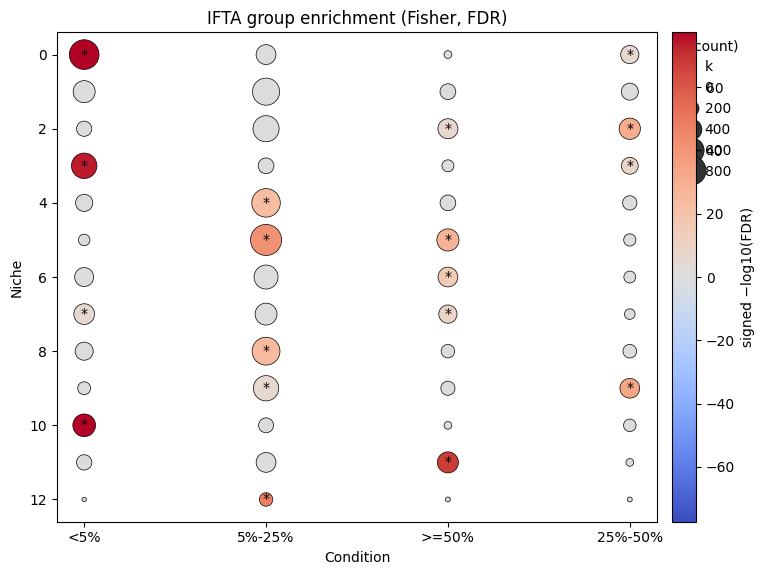

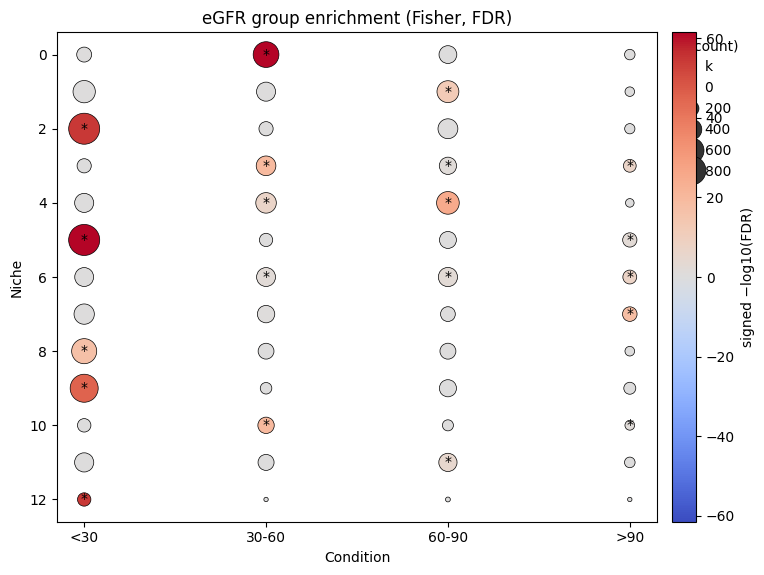

2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

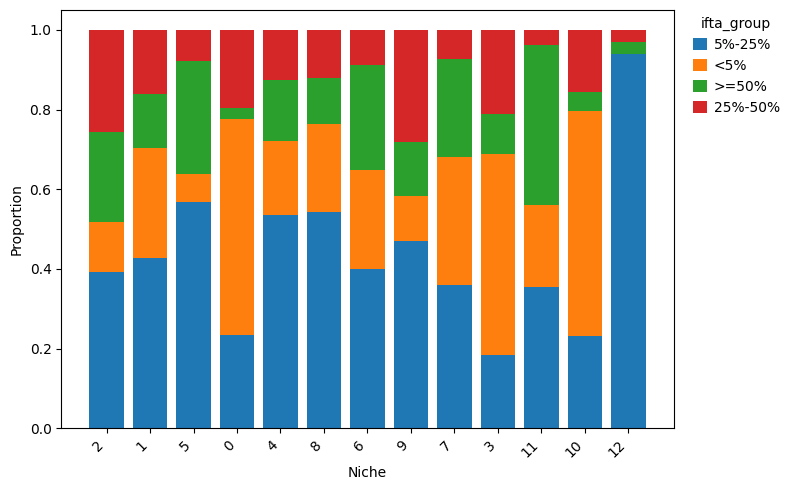

2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:04 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

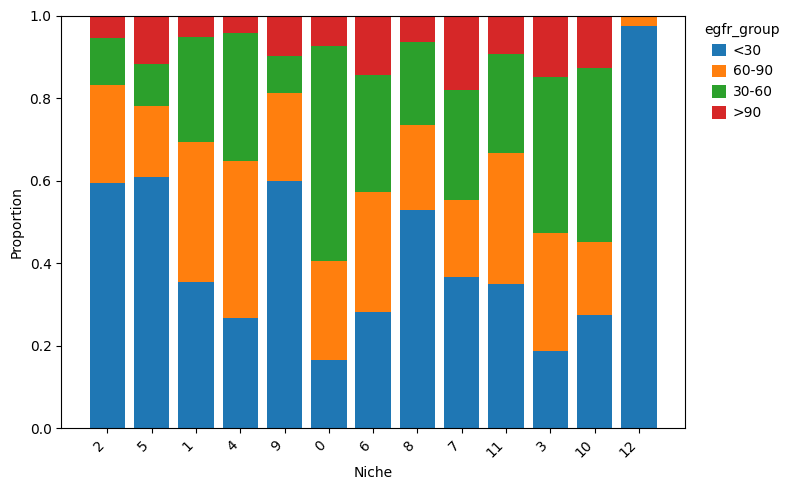

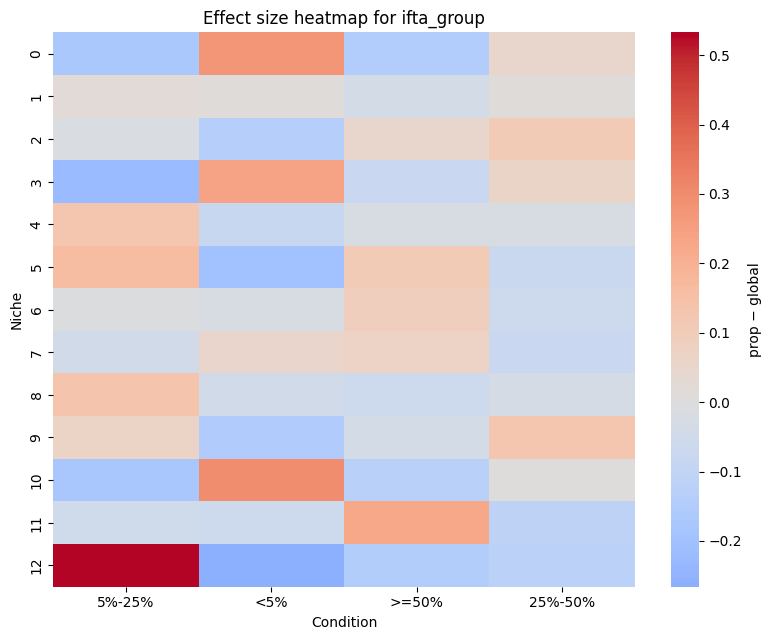

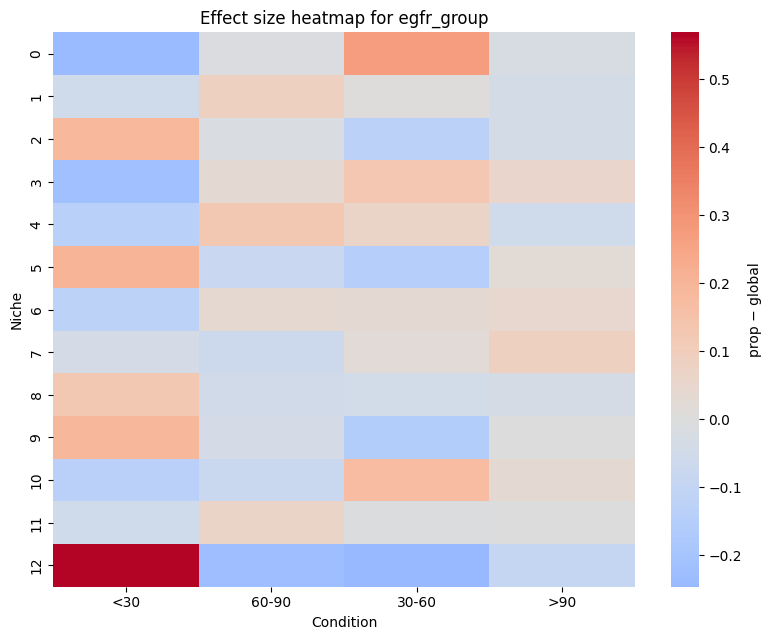

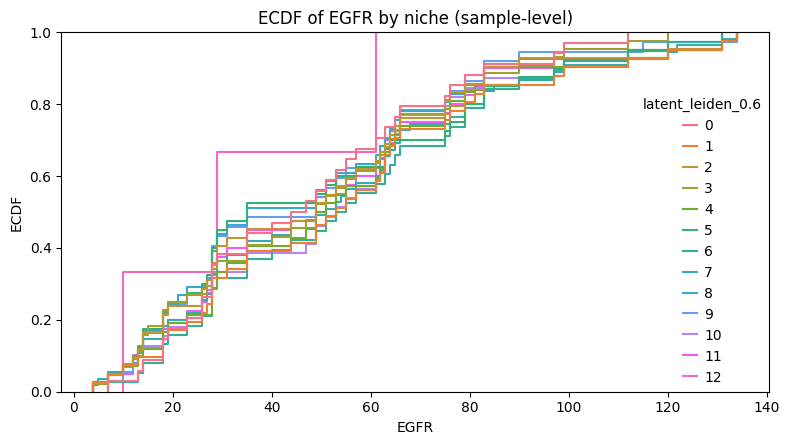

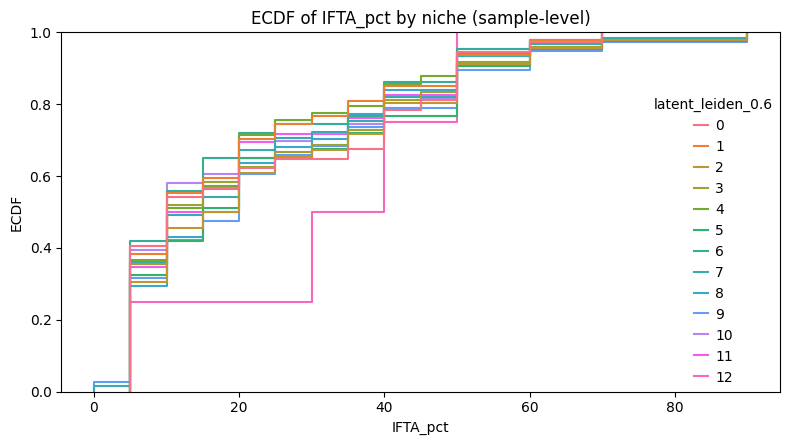

2025-09-04 13:43:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:08 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

<Figure size 800x650 with 0 Axes>

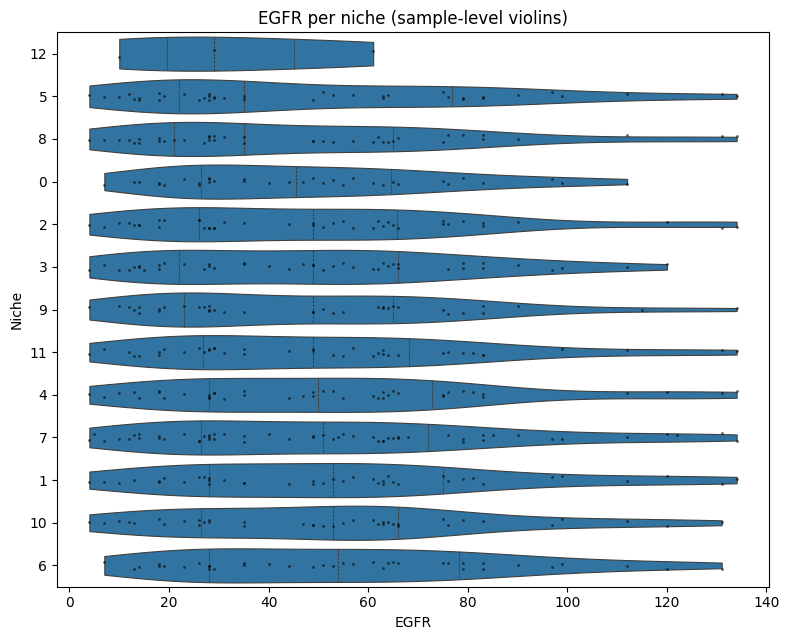

2025-09-04 13:43:09 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:09 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:09 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:09 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:09 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

<Figure size 800x650 with 0 Axes>

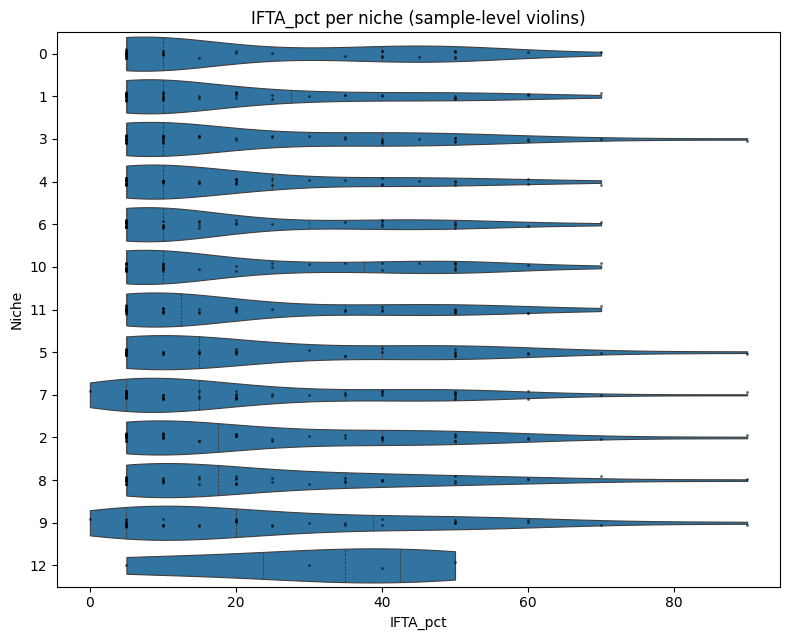

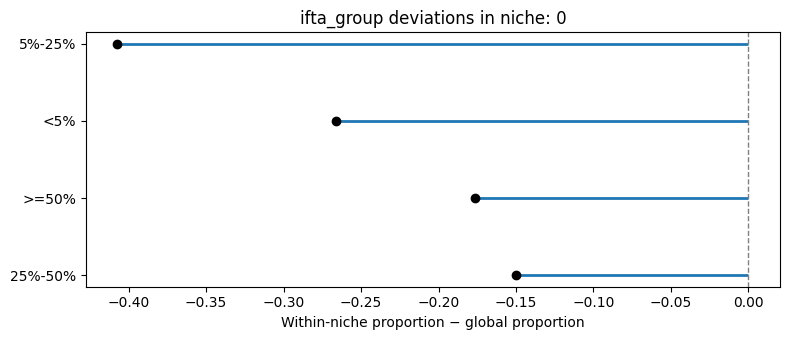

In [131]:
# Paths and keys

tma_key = "TMA_ID"

# 1) Bubble maps for IFTA and eGFR group enrichments (using saved Fisher results)
f_ifta = load_fisher_df(figure_folder_path, prefix="IFTA_group")
f_egfr = load_fisher_df(figure_folder_path, prefix="EGFR_group")

plot_bubble_enrichment(
    f_ifta,
    out_path=os.path.join(figure_folder_path, "IFTA_group_bubble.pdf"),
    title="IFTA group enrichment (Fisher, FDR)",
    min_n=20
)
plot_bubble_enrichment(
    f_egfr,
    out_path=os.path.join(figure_folder_path, "EGFR_group_bubble.pdf"),
    title="eGFR group enrichment (Fisher, FDR)",
    min_n=20
)

# 2) Stacked composition bars (cell-level)
plot_stacked_proportions(
    adata,
    latent_cluster_key=latent_cluster_key,
    condition_key="ifta_group",
    out_path=os.path.join(figure_folder_path, "ifta_group_stacked_bars.pdf"),
    min_total=50
)
plot_stacked_proportions(
    adata,
    latent_cluster_key=latent_cluster_key,
    condition_key="egfr_group",
    out_path=os.path.join(figure_folder_path, "egfr_group_stacked_bars.pdf"),
    min_total=50
)

# 3) Effect-size heatmaps (prop − global), complementary to FDR heatmaps
plot_effectsize_heatmap(
    adata,
    latent_cluster_key=latent_cluster_key,
    condition_key="ifta_group",
    out_path=os.path.join(figure_folder_path, "ifta_group_effectsize_heatmap.pdf")
)
plot_effectsize_heatmap(
    adata,
    latent_cluster_key=latent_cluster_key,
    condition_key="egfr_group",
    out_path=os.path.join(figure_folder_path, "egfr_group_effectsize_heatmap.pdf")
)

# 4) ECDFs for continuous EGFR and IFTA (sample-level)
plot_ecdf_by_niche(
    adata,
    latent_cluster_key=latent_cluster_key,
    value_key="EGFR",
    out_path=os.path.join(figure_folder_path, "EGFR_ecdf_samplelevel.pdf"),
    sample_level=True,
    tma_key=tma_key
)
plot_ecdf_by_niche(
    adata,
    latent_cluster_key=latent_cluster_key,
    value_key="IFTA_pct",
    out_path=os.path.join(figure_folder_path, "IFTA_ecdf_samplelevel.pdf"),
    sample_level=True,
    tma_key=tma_key
)

# 5) Ridgeline-style (violin + dots) for continuous values (sample-level)
plot_ridgeline_by_niche(
    adata,
    latent_cluster_key=latent_cluster_key,
    value_key="EGFR",
    out_path=os.path.join(figure_folder_path, "EGFR_ridgeline_violin.pdf"),
    tma_key=tma_key
)
plot_ridgeline_by_niche(
    adata,
    latent_cluster_key=latent_cluster_key,
    value_key="IFTA_pct",
    out_path=os.path.join(figure_folder_path, "IFTA_ridgeline_violin.pdf"),
    tma_key=tma_key
)

# 6) Lollipop deviations for a niche of interest (pick based on your results)
niche_of_interest = f_ifta.groupby("niche")["p_adj"].min().sort_values().index[0]  # best niche in IFTA
plot_lollipop_diffs(
    adata,
    latent_cluster_key=latent_cluster_key,
    condition_key="ifta_group",
    niche_of_interest=niche_of_interest,
    out_path=os.path.join(figure_folder_path, f"ifta_group_lollipop_{niche_of_interest}.pdf"),
    top_n=None  # show all groups
)

Found in_* flags: ['in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule', 'in_whole']


,niche,flag,pct_true,n_cells
0,0,in_damaged,0.000000,2243
1,1,in_damaged,0.249626,2003
2,2,in_damaged,0.000000,1783
3,3,in_damaged,0.000000,1757
4,4,in_damaged,0.000000,1715


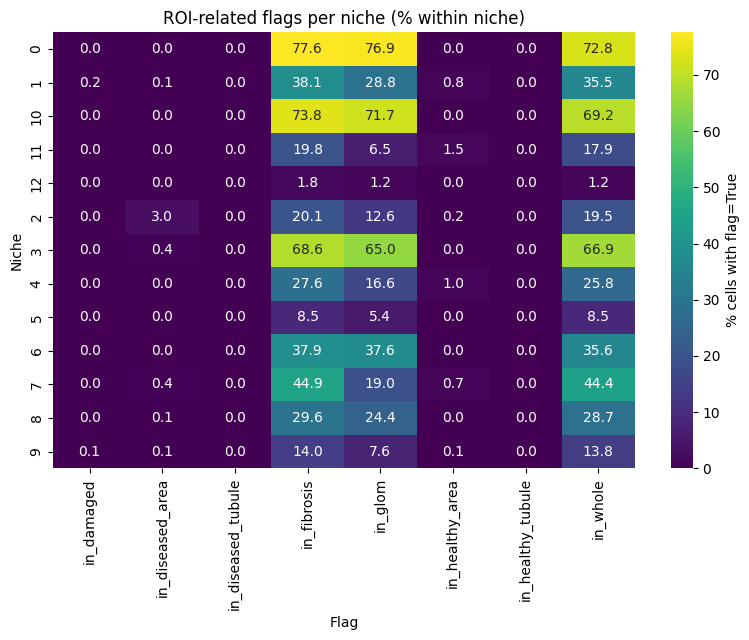

2025-09-04 13:43:37 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:37 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


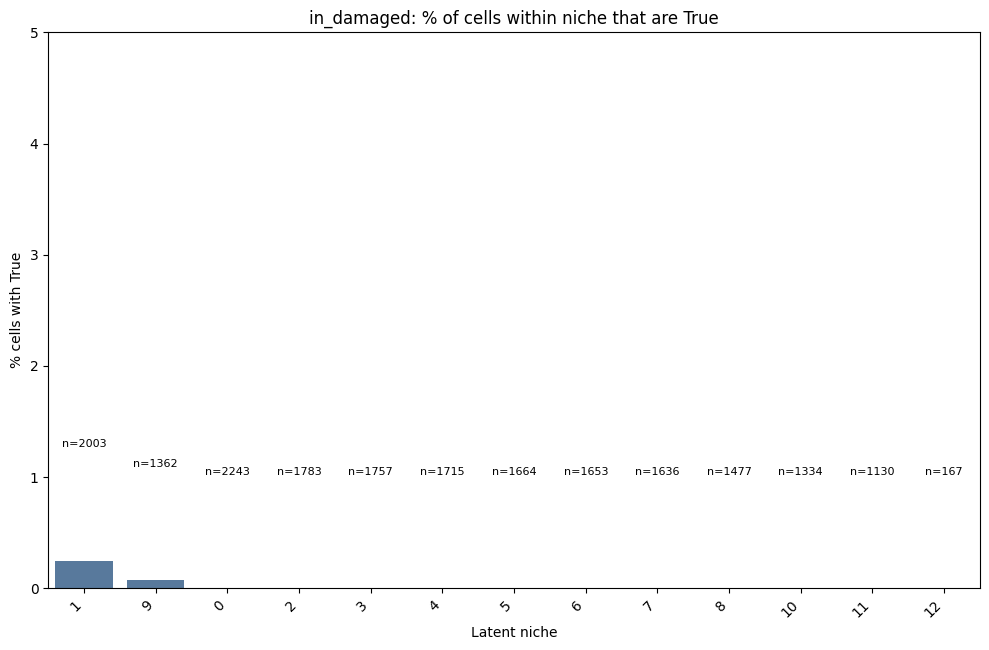

2025-09-04 13:43:38 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:38 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


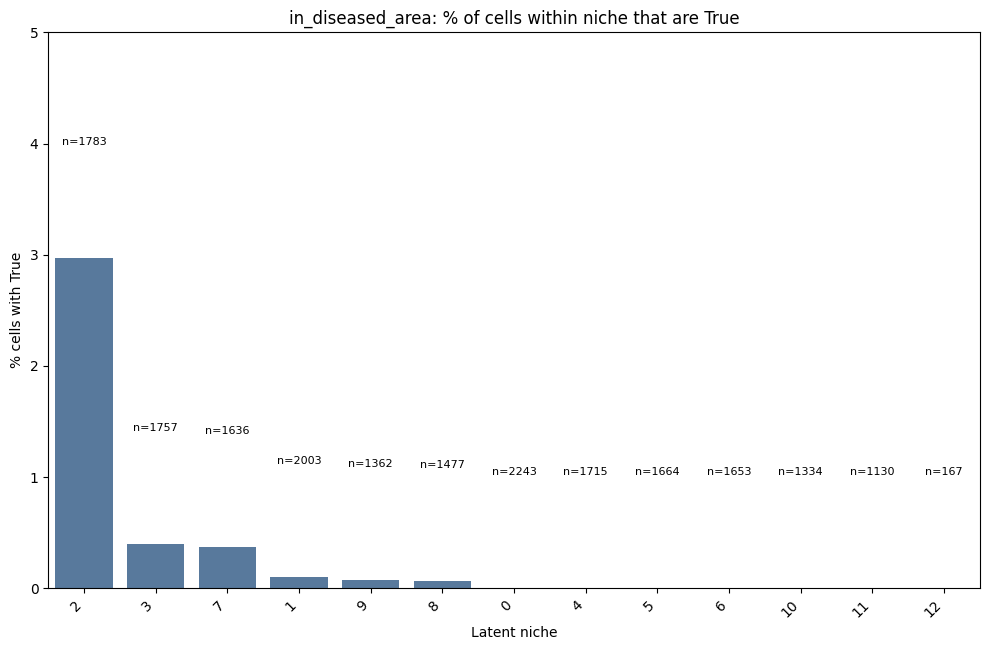

2025-09-04 13:43:39 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:39 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


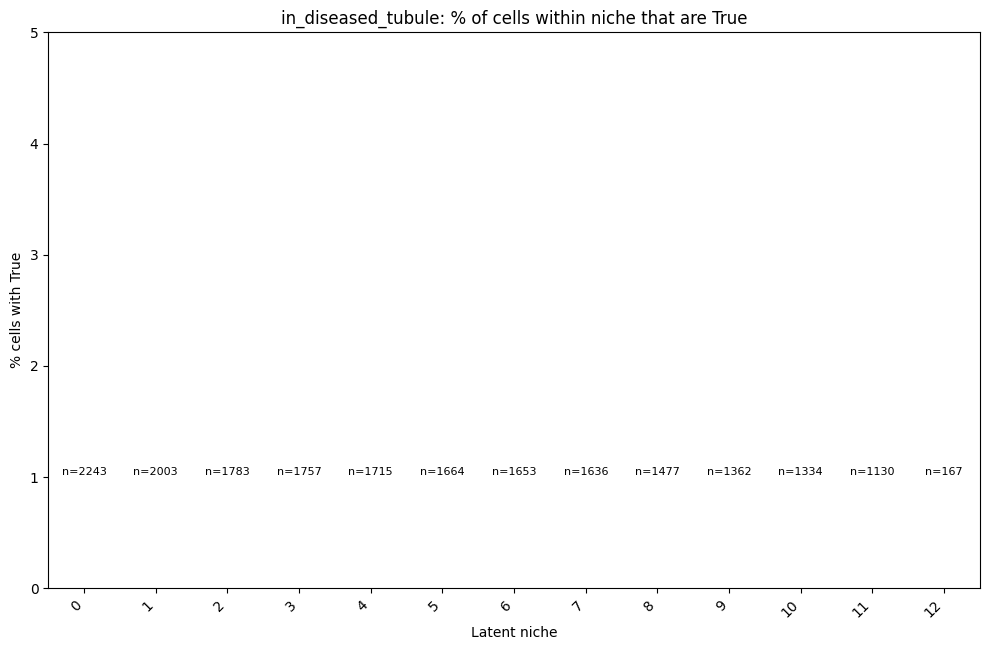

2025-09-04 13:43:40 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:40 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


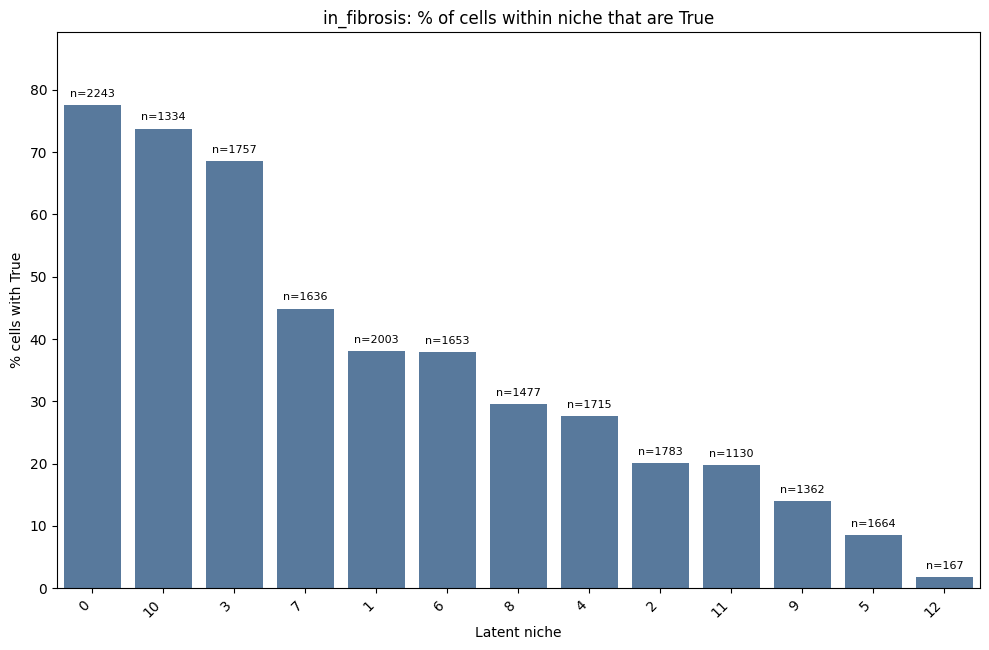

2025-09-04 13:43:41 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:41 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


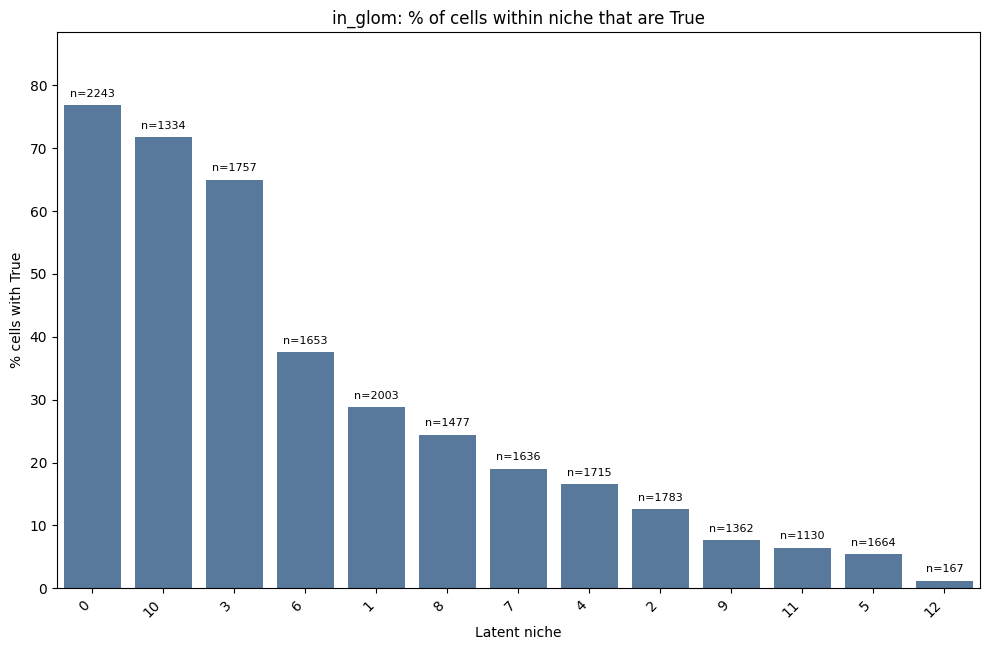

2025-09-04 13:43:41 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:41 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


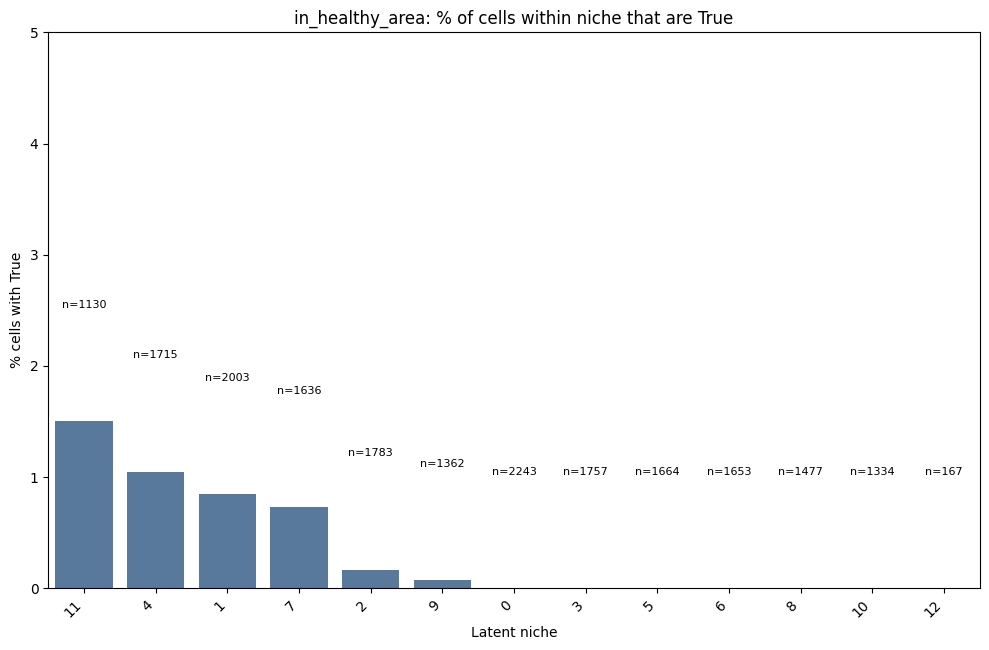

2025-09-04 13:43:42 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:42 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


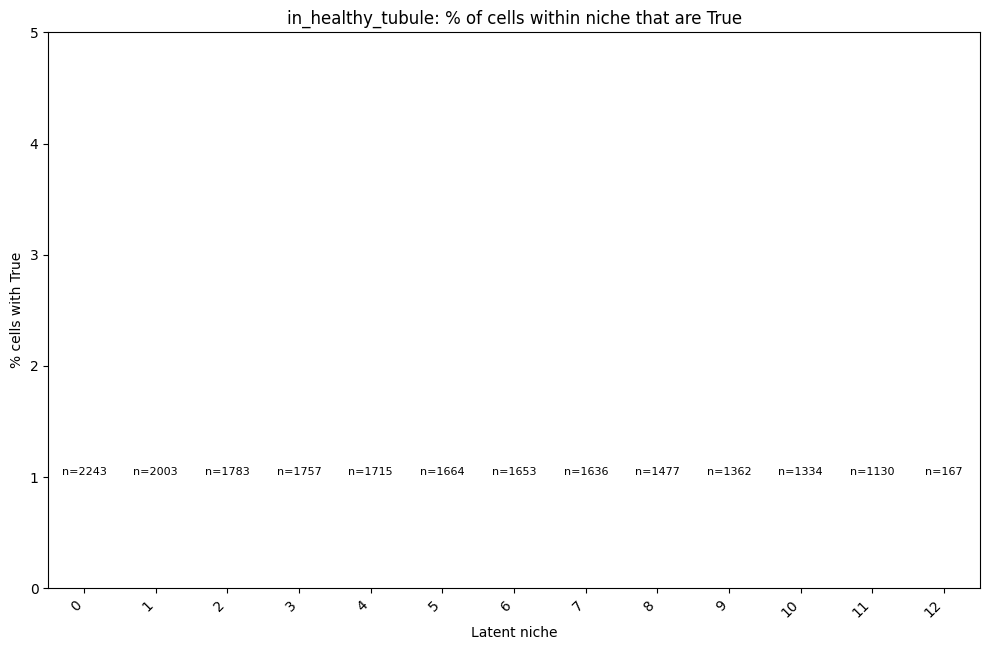

2025-09-04 13:43:43 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:43 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


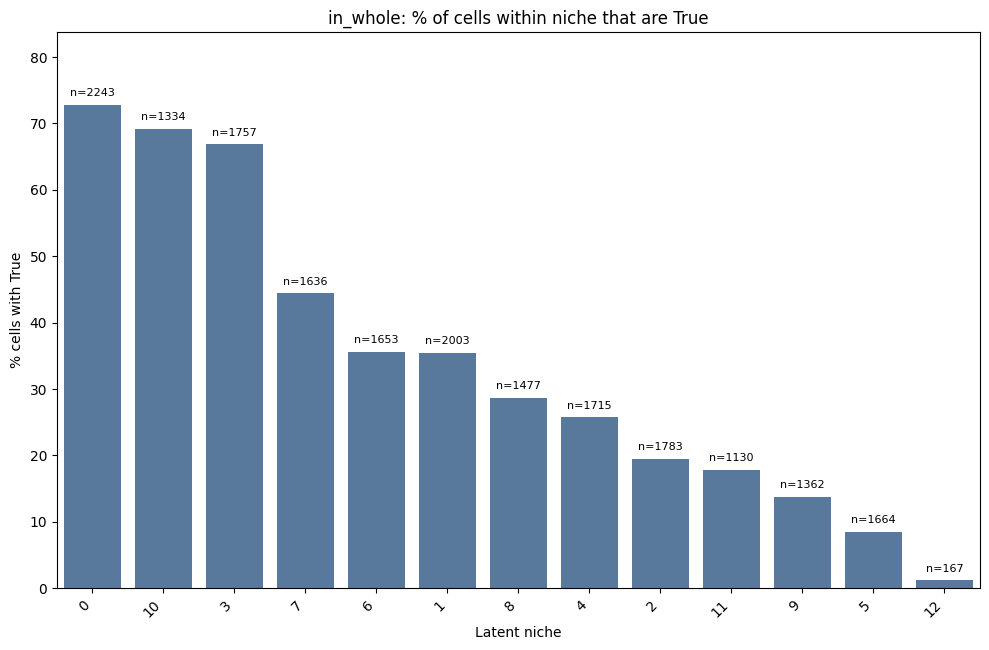

In [132]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc
from pathlib import Path

# --- CONFIG ---
adata = model.adata  # your main AnnData

# Paths to the three CSVs
meta_paths = [
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/1734__Region_3_roi.csv",
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/42348__Region_2_roi.csv",
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/42348__Region_3_roi.csv",
]

# Output folder for figures and tables
figure_folder_path = "./figures"
Path(figure_folder_path).mkdir(parents=True, exist_ok=True)

# --- 1) Load CSVs and collect all in_* columns ---
dfs = []
all_in_cols = set()
for p in meta_paths:
    df = pd.read_csv(p)
    if "cell_id" not in df.columns:
        raise KeyError(f"{p} is missing 'cell_id' column.")
    in_cols = [c for c in df.columns if c.startswith("in_")]
    # ensure booleans
    for c in in_cols:
        # Some CSVs may store as strings "True"/"False" or 0/1
        df[c] = df[c].map({True: True, False: False, "True": True, "False": False}).fillna(df[c]).astype(bool)
    dfs.append(df[["cell_id"] + in_cols].copy())
    all_in_cols.update(in_cols)

all_in_cols = sorted(all_in_cols)
print(f"Found in_* flags: {all_in_cols}")

# --- 2) Build a combined per-cell map for each in_* flag (logical OR across files) ---
# Start with an empty DataFrame indexed by cell_id
combined = None
for i, df in enumerate(dfs):
    if combined is None:
        combined = df.set_index("cell_id")
    else:
        combined = combined.join(df.set_index("cell_id"), how="outer", rsuffix=f"__{i}")

# Now reduce columns with the same base name (since some files may not have all flags).
# Strategy: for each flag in all_in_cols, OR across all columns that equal that name or came from joins.
combined_flags = pd.DataFrame(index=combined.index.unique())
for flag in all_in_cols:
    # columns that exactly match the flag (no suffix) or have identical names from different DataFrames due to aligned join
    # Note: since we used rsuffix only when overlapping column names occurred, exact matches suffice.
    if flag in combined.columns:
        cols = [flag]
    else:
        cols = [c for c in combined.columns if c.split("__")[0] == flag or c == flag]
        if len(cols) == 0:
            # look for exact name occurrences that might have been suffixed
            cols = [c for c in combined.columns if c.endswith(flag)]
    # Extract and cast to bool, fill NaN with False
    vals = combined[cols].copy() if len(cols) > 0 else pd.DataFrame(index=combined.index)
    if vals.shape[1] == 0:
        combined_flags[flag] = False
    else:
        vals = vals.fillna(False).astype(bool)
        combined_flags[flag] = vals.any(axis=1)

combined_flags = combined_flags.reset_index().rename(columns={"index": "cell_id"})

# --- 3) Map combined flags into adata.obs via cell_id ---
if "cell_id" not in adata.obs.columns:
    raise KeyError("Main AnnData is missing obs['cell_id'].")

id_to_row = pd.Series(adata.obs_names, index=adata.obs["cell_id"]).dropna()
# Initialize all flags to False; then set True where matched
for flag in all_in_cols:
    adata.obs[flag] = False

# Map values
flag_map = combined_flags.set_index("cell_id")
matched_mask = adata.obs["cell_id"].isin(flag_map.index)
matched_ids = adata.obs.loc[matched_mask, "cell_id"]
for flag in all_in_cols:
    vals = flag_map.loc[matched_ids, flag].astype(bool).values
    adata.obs.loc[matched_mask, flag] = vals

# Any cells not present in any CSV remain False, as requested.

# --- 4) Compute percentages within each niche for every in_* flag ---
if latent_cluster_key not in adata.obs.columns:
    raise KeyError(f"{latent_cluster_key} not found in adata.obs")

results = []
for flag in all_in_cols:
    grp = adata.obs.groupby(latent_cluster_key)[flag]
    pct = grp.mean() * 100.0
    n_cells = adata.obs.groupby(latent_cluster_key).size()
    out = pd.DataFrame({
        "niche": pct.index.astype(str),
        "flag": flag,
        "pct_true": pct.values,
        "n_cells": n_cells.values,
    })
    results.append(out)

summary = pd.concat(results, axis=0)
summary.to_csv(f"{figure_folder_path}/roi_flag_percentages_by_niche.csv", index=False)
display(summary.head())

# --- 5) Plot: one heatmap of percent True per niche x flag ---
pivot = summary.pivot(index="niche", columns="flag", values="pct_true").fillna(0)
plt.figure(figsize=(max(8, 0.6*pivot.shape[1]), max(4, 0.5*pivot.shape[0])))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="viridis", cbar_kws={"label":"% cells with flag=True"})
plt.title("ROI-related flags per niche (% within niche)")
plt.xlabel("Flag")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/roi_flags_percent_heatmap.pdf", bbox_inches="tight")
plt.show()

# --- 6) Optional: per-flag barplots (percent True per niche) ---
for flag in all_in_cols:
    sub = summary[summary["flag"] == flag].sort_values("pct_true", ascending=False)
    plt.figure(figsize=(10, 4 + 0.2*len(sub)))
    sns.barplot(data=sub, x="niche", y="pct_true", color="#4C78A8", order=sub["niche"])
    for i, (x, y, n) in enumerate(zip(sub["niche"], sub["pct_true"], sub["n_cells"])):
        plt.text(i, y + 1.0, f"n={n}", ha="center", va="bottom", fontsize=8)
    plt.ylabel("% cells with True")
    plt.xlabel("Latent niche")
    plt.title(f"{flag}: % of cells within niche that are True")
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, max(5, sub["pct_true"].max() * 1.15))
    plt.tight_layout()
    plt.savefig(f"{figure_folder_path}/roi_flag_pct_by_niche__{flag}.pdf", bbox_inches="tight")
    plt.show()

Detected in_* flags: ['in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule', 'in_whole']


,niche,flag,pct_true,n_cells
0,0,in_damaged,0.000000,2243
1,1,in_damaged,0.249626,2003
2,2,in_damaged,0.000000,1783
3,3,in_damaged,0.000000,1757
4,4,in_damaged,0.000000,1715


2025-09-04 13:43:47 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:47 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


Plotting flags: ['in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule', 'in_whole']


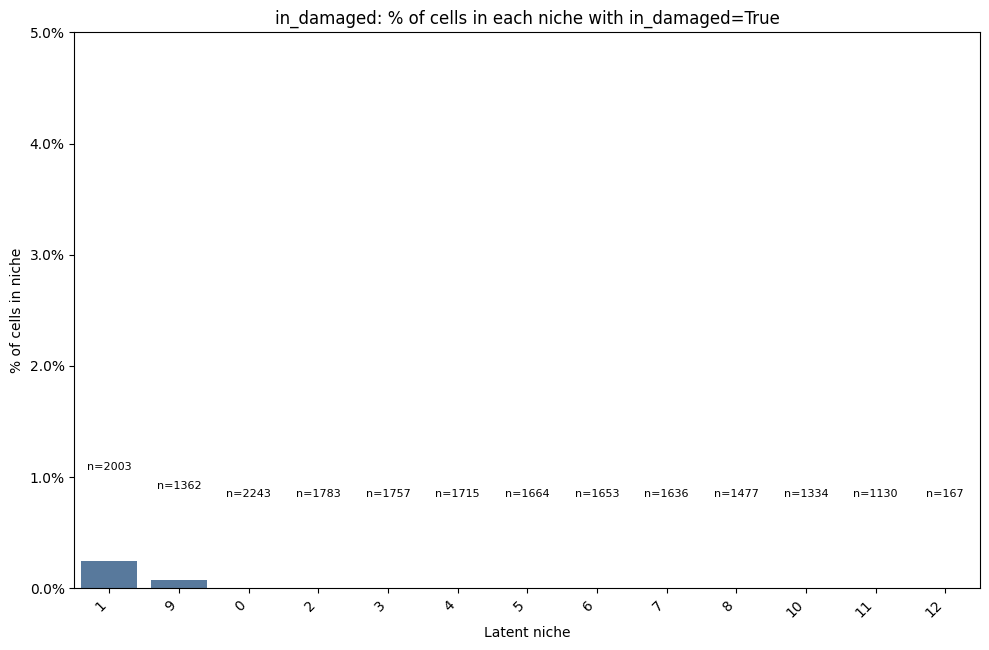

2025-09-04 13:43:48 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:48 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


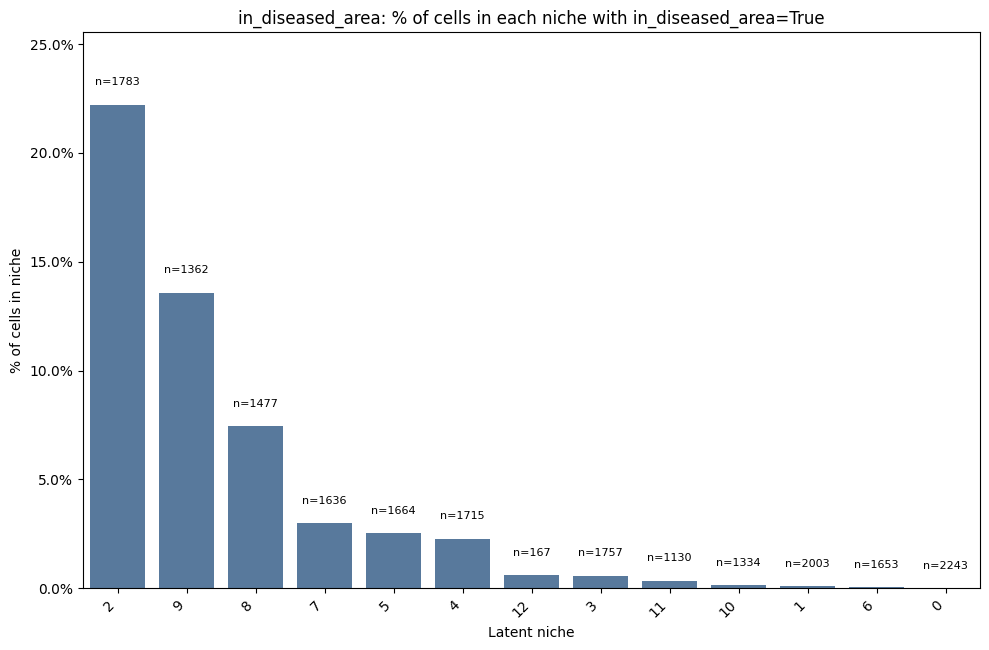

2025-09-04 13:43:48 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:48 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


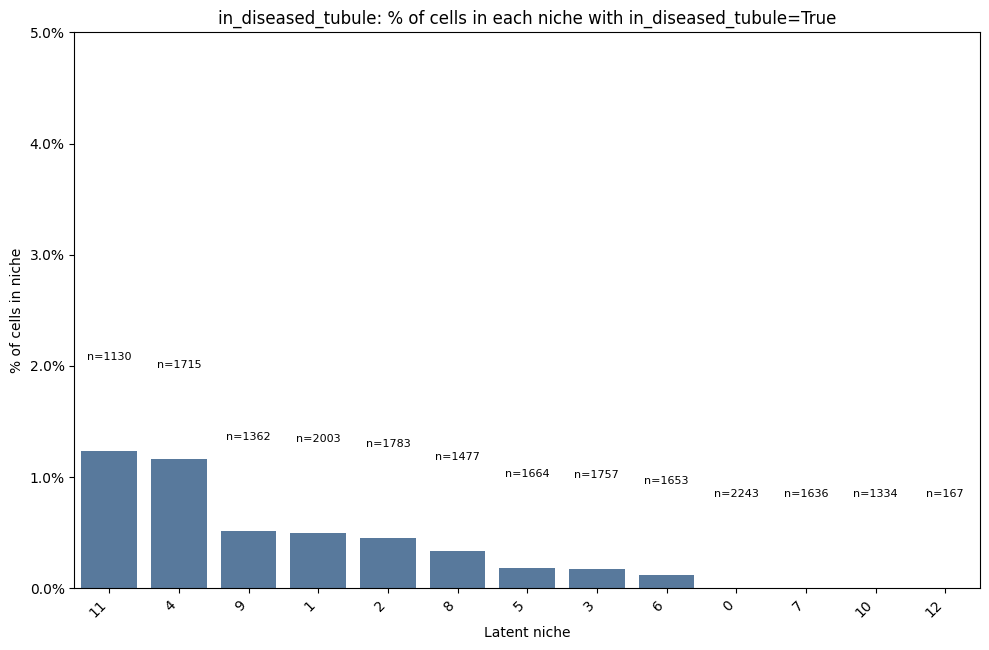

2025-09-04 13:43:49 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:49 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


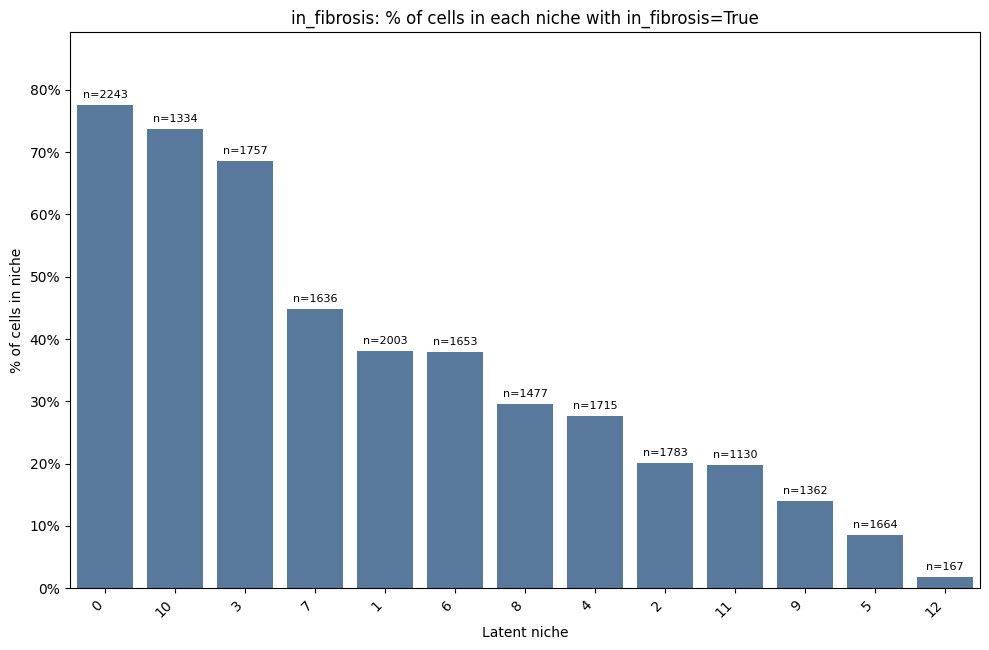

2025-09-04 13:43:50 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:50 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


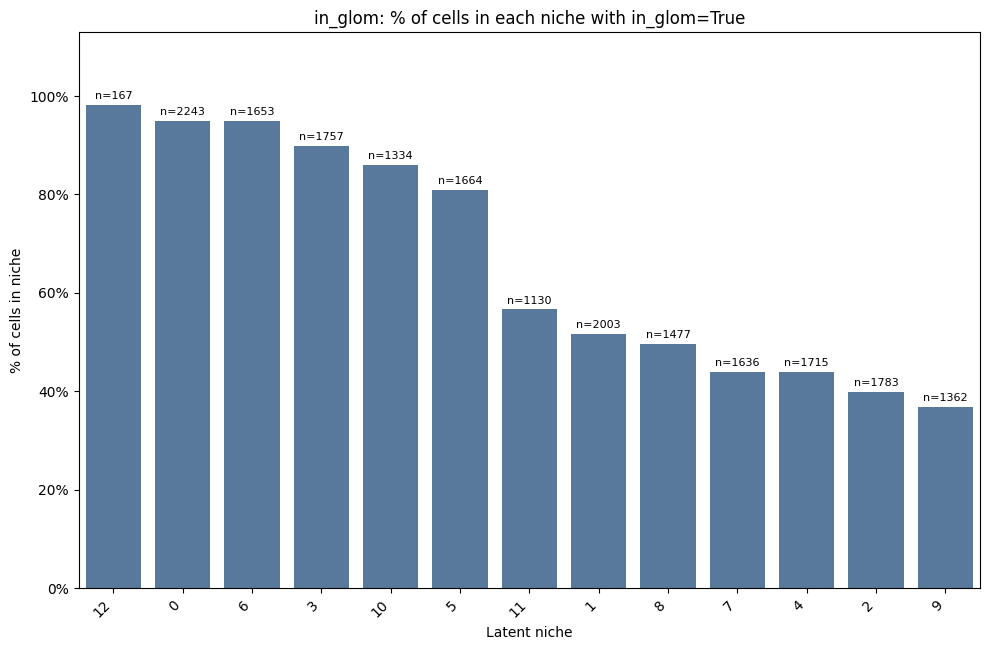

2025-09-04 13:43:51 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:51 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


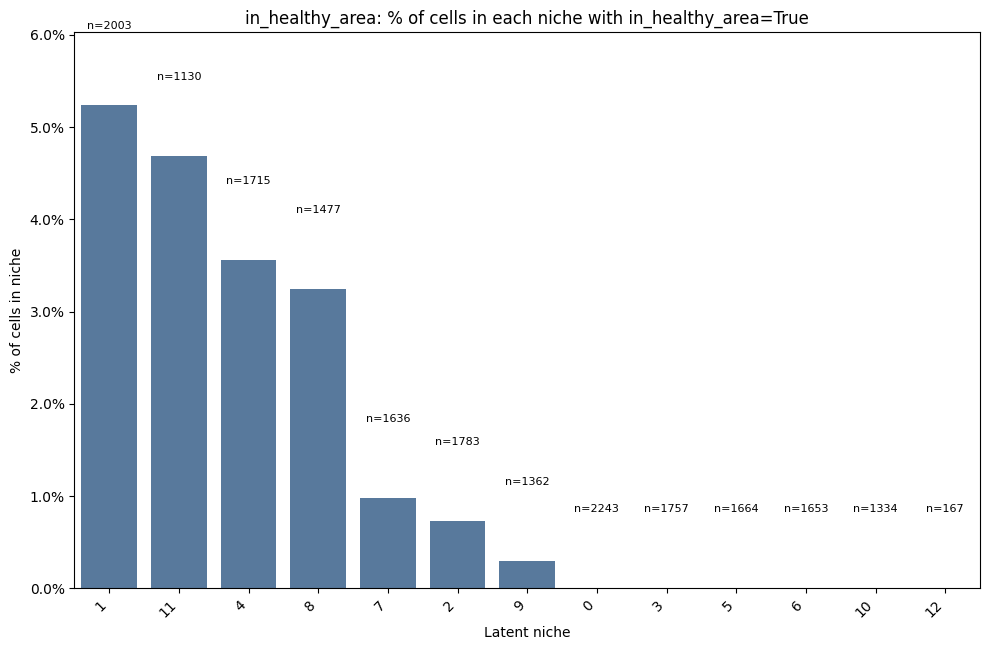

2025-09-04 13:43:53 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:53 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


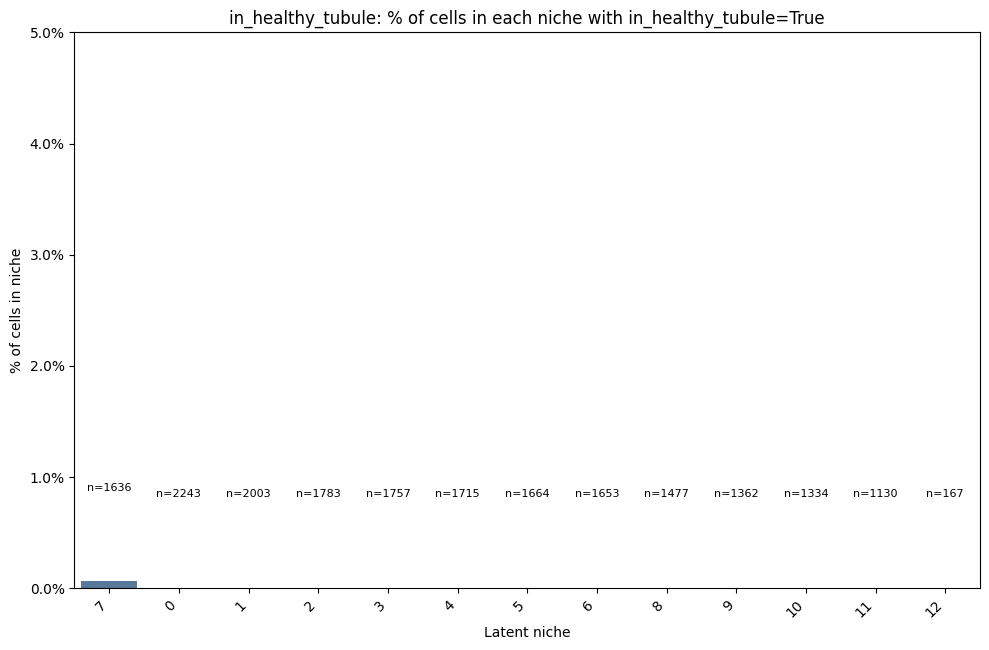

2025-09-04 13:43:54 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-09-04 13:43:54 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


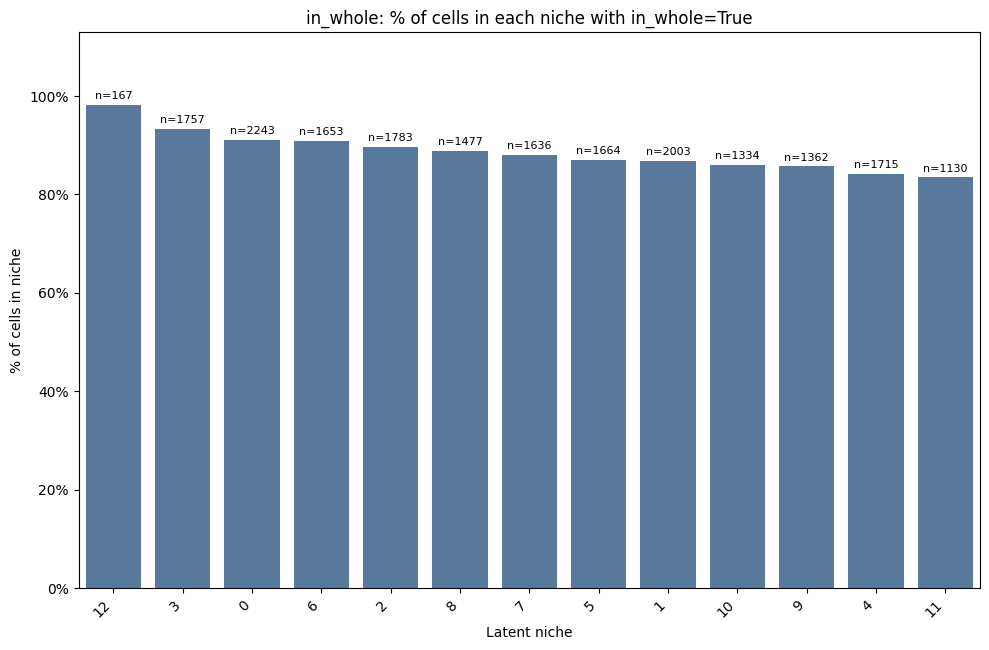

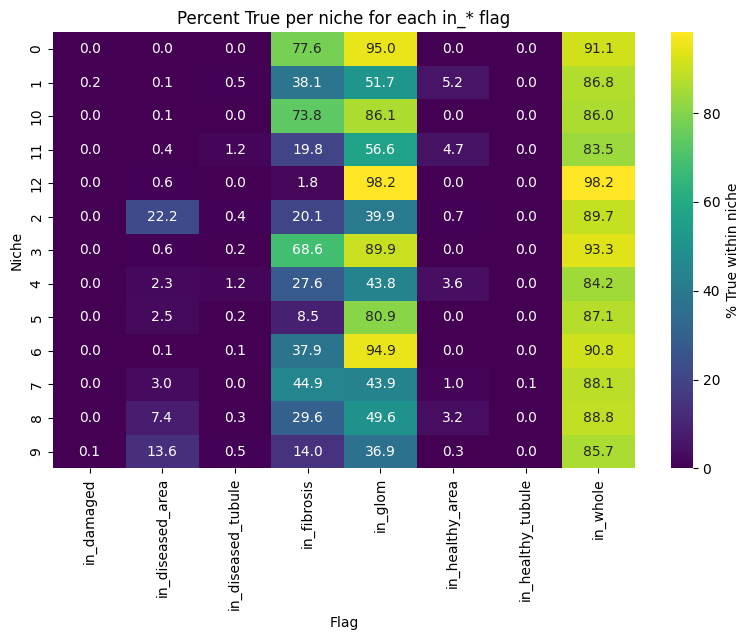

In [133]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# --- CONFIG ---
adata = model.adata  # your main AnnData
latent_leiden_resolution = 0.6
latent_cluster_key = f"latent_leiden_{latent_leiden_resolution}"

meta_paths = [
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/1734__Region_3_roi.csv",
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/42348__Region_2_roi.csv",
    "/beegfs/home/lfrommer/projects/kidney_biopsy/regions_of_interest/42348__Region_3_roi.csv",
]

figure_folder_path = "./figures_roi_flags"
Path(figure_folder_path).mkdir(parents=True, exist_ok=True)

# --- Helpers ---
def coerce_bool_series(s: pd.Series) -> pd.Series:
    def _coerce(x):
        if pd.isna(x):
            return np.nan
        if isinstance(x, bool):
            return x
        if isinstance(x, (int, np.integer)):
            return bool(x)
        if isinstance(x, (float, np.floating)):
            return bool(int(x))
        if isinstance(x, str):
            t = x.strip().lower()
            if t in {"true","t","1","yes","y"}:
                return True
            if t in {"false","f","0","no","n"}:
                return False
        return bool(x)
    return s.map(_coerce)

# --- 1) Load CSVs and gather union of in_* flags ---
dfs_raw = []
all_in_cols = set()
for p in meta_paths:
    df = pd.read_csv(p)
    # Drop unnamed index-like columns
    df = df.loc[:, ~df.columns.str.match(r"^Unnamed")]
    if "cell_id" not in df.columns:
        raise KeyError(f"{p} is missing 'cell_id' column.")
    in_cols = [c for c in df.columns if c.startswith("in_")]
    for c in in_cols:
        df[c] = coerce_bool_series(df[c])
    # Keep only cell_id + in_* columns
    dfs_raw.append(df[["cell_id"] + in_cols].copy())
    all_in_cols.update(in_cols)

all_in_cols = sorted(all_in_cols)
print(f"Detected in_* flags: {all_in_cols}")

# --- 2) Standardize frames, fill missing flags as False, OR within and across files ---
stds = []
for df in dfs_raw:
    # Ensure all flags exist; fill missing with False
    for flag in all_in_cols:
        if flag not in df.columns:
            df[flag] = False
    df_std = df[["cell_id"] + all_in_cols].copy()
    # OR within file for duplicated cell_id
    df_std = df_std.groupby("cell_id", as_index=False)[all_in_cols].any()
    stds.append(df_std)

# OR across files
combined_flags = pd.concat(stds, ignore_index=True).groupby("cell_id", as_index=False)[all_in_cols].any()

# --- 3) Map flags into adata.obs via cell_id (unmatched -> False) ---
if "cell_id" not in adata.obs.columns:
    raise KeyError("Main AnnData is missing obs['cell_id'].")

flag_map = combined_flags.set_index("cell_id")
for flag in all_in_cols:
    adata.obs[flag] = adata.obs["cell_id"].map(flag_map[flag]).fillna(False).astype(bool)

# Optional: save the combined mapping
combined_flags.to_csv(f"{figure_folder_path}/combined_in_flags_by_cell_id.csv", index=False)

# --- 4) Compute % within each niche (denominator = all cells in the niche) ---
if latent_cluster_key not in adata.obs.columns:
    raise KeyError(f"{latent_cluster_key} not found in adata.obs")

n_cells_by_niche = adata.obs.groupby(latent_cluster_key).size()

summary_list = []
for flag in all_in_cols:
    pct = adata.obs.groupby(latent_cluster_key)[flag].mean() * 100.0
    out = pd.DataFrame({
        "niche": pct.index.astype(str),
        "flag": flag,
        "pct_true": pct.values,
        "n_cells": n_cells_by_niche.values,
    })
    summary_list.append(out)

summary = pd.concat(summary_list, axis=0)
summary.to_csv(f"{figure_folder_path}/percent_true_by_niche_all_flags.csv", index=False)
display(summary.head())

# --- 5) Plot: one barplot per flag ---
import matplotlib.ticker as mtick

def plot_flag_bar(flag: str):
    sub = summary[summary["flag"] == flag].copy()
    sub = sub.sort_values("pct_true", ascending=False)
    order = sub["niche"]
    plt.figure(figsize=(10, 4 + 0.2*len(sub)))
    sns.barplot(data=sub, x="niche", y="pct_true", order=order, color="#4C78A8")
    for i, (x, y, n) in enumerate(zip(order, sub["pct_true"], sub["n_cells"])):
        plt.text(i, y + 0.8, f"n={n}", ha="center", va="bottom", fontsize=8)
    plt.ylabel("% of cells in niche")
    plt.xlabel("Latent niche")
    plt.title(f"{flag}: % of cells in each niche with {flag}=True")
    plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter())
    plt.xticks(rotation=45, ha="right")
    plt.ylim(0, max(5, sub["pct_true"].max() * 1.15))
    plt.tight_layout()
    plt.savefig(f"{figure_folder_path}/pct_by_niche__{flag}.pdf", bbox_inches="tight")
    plt.show()

# Choose which flags to plot (set to None to plot all)
selected_flags = None  # e.g., ["in_glom", "in_fibrosis"]

flags_to_plot = [f for f in (selected_flags or all_in_cols) if f in all_in_cols]
print("Plotting flags:", flags_to_plot)
for flag in flags_to_plot:
    plot_flag_bar(flag)

# --- Optional: a single heatmap across all flags ---
pivot = summary.pivot(index="niche", columns="flag", values="pct_true").fillna(0)
plt.figure(figsize=(max(8, 0.6*pivot.shape[1]), max(4, 0.5*pivot.shape[0])))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="viridis", cbar_kws={"label":"% True within niche"})
plt.title("Percent True per niche for each in_* flag")
plt.xlabel("Flag")
plt.ylabel("Niche")
plt.tight_layout()
plt.savefig(f"{figure_folder_path}/percent_true_heatmap.pdf", bbox_inches="tight")
plt.show()

In [107]:
adata

AnnData object with n_obs × n_vars = 19924 × 468
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'TMA_ID', 'sample', 'predic', 'leiden', 'cell_type_manual', 'condition', 'latent_leiden_0.4', 'Add-on_26_GP', 'TENM4_ligand_receptor_GP', 'Add-on_66_GP', 'Add-on_33_GP', 'Add-on_55_GP', 'Add-on_15_GP', 'Add-on_12_GP', 'Add-on_75_GP', 'NTN4_combined_GP', 'CA12_ligand_receptor_target_gene_GP', 'Add-on_39_GP', 'Add-on_38_GP', 'Add-on_8_GP', 'Add-on_24_GP', 'CCL8_combined_GP', 'Add-on_76_GP', 'MMP7_ligand_receptor_target_gene_GP', 'TGFBR3_ligand_receptor_GP', 'PTPRC_ligand_receptor_target_gene_GP', 'Add-on_22_GP', 'Add-on_18_GP', 'in_damaged', 'in_diseased_area', 'in_diseased_tubule', 'in_fibrosis', 'in_glom', 'in_healthy_area', 'in_healthy_tubule'

In [136]:
# Option 1: rename just that column
adata.obs = adata.obs.rename(columns={"supp_DBD/DCD": "supp_DBD_DCD"})

# Option 2: sanitize all obs column names (replace "/" with "_")
adata.obs.columns = adata.obs.columns.str.replace("/", "_", regex=False)

# If you also have slashes in var or obsm keys, sanitize them similarly:
adata.var.columns = adata.var.columns.str.replace("/", "_", regex=False)
adata.obsm = {k.replace("/", "_"): v for k, v in adata.obsm.items()}
adata.varm = {k.replace("/", "_"): v for k, v in adata.varm.items()}
adata.obsp = {k.replace("/", "_"): v for k, v in adata.obsp.items()}
adata.uns = {k.replace("/", "_"): v for k, v in adata.uns.items()}  # careful if nested; see below

In [ ]:
import pandas as pd

# 1) Identify duplicated columns in obs
dupe_mask = adata.obs.columns.duplicated(keep="first")
dupe_cols = adata.obs.columns[dupe_mask]
print(f"Dropping {dupe_mask.sum()} duplicated columns from obs: {list(dupe_cols[:10])}...")

# 2) Drop the duplicates (keep first occurrence)
adata.obs = adata.obs.loc[:, ~dupe_mask].copy()
assert adata.obs.columns.is_unique
"""
# 3) (Optional) Do the same for var if you suspect duplicates there too
if not adata.var.columns.is_unique:
    dupe_mask_var = adata.var.columns.duplicated(keep="first")
    dupe_cols_var = adata.var.columns[dupe_mask_var]
    print(f"Dropping {dupe_mask_var.sum()} duplicated columns from var: {list(dupe_cols_var[:10])}...")
    adata.var = adata.var.loc[:, ~dupe_mask_var].copy()
    assert adata.var.columns.is_unique
"""
# 4) (Optional) If you accidentally created duplicated layers/obsm/obsp keys, ensure uniqueness
# For obsm/varm/obsp/varp you can’t have duplicate keys in dict-like containers, so usually fine.
# But you might have columns inside obsm dataframes; handle similarly if needed.

# 5) Write
adata.write_h5ad("/beegfs/home/lfrommer/projects/kidney_biopsy/xenium_with_niches_in_glom_niche.h5ad")

In [137]:
adata.write_h5ad("/beegfs/home/lfrommer/projects/kidney_biopsy/xenium_with_niches_in_glom_niche.h5ad")

In [4]:
adata = sc.read_h5ad("/beegfs/home/lfrommer/projects/kidney_biopsy/xenium_with_niches_in_glom_niche.h5ad")

In [6]:
# Prereqs:
# pip install scanpy anndata pandas numpy matplotlib seaborn

import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path

# Assume adata is loaded
# adata = sc.read_h5ad("your_file.h5ad")

assert "latent_leiden_0.6" in adata.obs.columns, "latent_leiden_0.6 missing"
assert "cell_type_manual" in adata.obs.columns, "cell_type_manual missing"

# Optional: ensure categories are categorical
for col in ["latent_leiden_0.4", "cell_type_manual"]:
    if adata.obs[col].dtype.name != "category":
        adata.obs[col] = adata.obs[col].astype("category")

# Settings
outdir = Path("/beegfs/home/lfrommer/projects/kidney_biopsy/niche_marker_results_compass_niche")
outdir.mkdir(parents=True, exist_ok=True)
sc.settings.figdir = str(outdir)  # so scanpy saves into this folder


import numpy as np
import pandas as pd

def rgg_get_field(r, field, group, length):
    # Handles that r[field] can be a structured array with fields or a dict-like
    if field not in r:
        return np.full(length, np.nan)
    val = r[field]
    # structured array with dtype.names
    if hasattr(val, "dtype") and getattr(val.dtype, "names", None):
        return val[group]
    # mapping (as returned by earlier code)
    if isinstance(val, dict):
        return val.get(group, np.full(length, np.nan))
    # 2D array shaped (n_groups, n_genes)
    if isinstance(val, np.ndarray):
        if val.ndim == 2:
            # Map group name to index
            groups = r["names"].dtype.names
            gi = list(groups).index(group)
            return val[gi, :]
        # 1D array (shouldn't happen here); broadcast/trim
        if val.ndim == 1:
            if len(val) == length:
                return val
            return val[:length] if len(val) > length else np.pad(val, (0, length-len(val)), constant_values=np.nan)
    # fallback
    return np.full(length, np.nan)

def rank_genes_to_tidy_safe(uns_dict):
    r = uns_dict
    groups = list(r["names"].dtype.names)
    dfs = []
    for g in groups:
        names_g = np.array(r["names"][g])
        n = len(names_g)
        df_g = pd.DataFrame({
            "group": g,
            "gene": names_g,
            "score": np.array(r["scores"][g]),
            "logfoldchange": rgg_get_field(r, "logfoldchanges", g, n),
            "pval": np.array(r["pvals"][g]),
            "pval_adj": np.array(r["pvals_adj"][g]),
            "pct_in_group": rgg_get_field(r, "pts", g, n),
            "pct_out_group": rgg_get_field(r, "pts_rest", g, n),
        })
        dfs.append(df_g)
    return pd.concat(dfs, ignore_index=True)
    
# Choose expression source: use_raw=True if normalized log1p data is in adata.raw
# Create a log-normalized layer for DE (leaves .X unchanged if you prefer)
adata.layers["counts"] = adata.X.copy()  # optional, keep counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()
# Optionally restore counts to X to avoid affecting other steps
adata.X = adata.layers["counts"]

USE_RAW = False
LAYER = "lognorm" # set based on A)
N_TOP_TABLE = 200
N_TOP_PLOT = 10
N_TOP_DOTPLOT = 5

all_clusters_dfs = []

for cl in adata.obs["latent_leiden_0.6"].cat.categories:
    ad_sub = adata[adata.obs["latent_leiden_0.6"] == cl].copy()
    # Filter sparse cell types
    vc = ad_sub.obs["cell_type_manual"].value_counts()
    keep = vc[vc >= 5].index
    ad_sub = ad_sub[ad_sub.obs["cell_type_manual"].isin(keep)].copy()
    if ad_sub.n_obs < 20 or ad_sub.obs["cell_type_manual"].nunique() < 2:
        print(f"Skipping cluster {cl}: insufficient cells or <2 cell types.")
        continue

    sc.tl.rank_genes_groups(
        ad_sub,
        groupby="cell_type_manual",
        method="wilcoxon",
        n_genes=N_TOP_TABLE,
        use_raw=USE_RAW if LAYER is None else False,
        layer=LAYER,
        corr_method="benjamini-hochberg",
        tie_correct=True,
        pts=True,
    )

    df = rank_genes_to_tidy_safe(ad_sub.uns["rank_genes_groups"])
    df.insert(0, "latent_cluster", cl)
    df.to_csv(outdir / f"markers_celltypes_within_cluster_{cl}.csv", index=False)
    all_clusters_dfs.append(df)

    # Plots
    sc.pl.rank_genes_groups(ad_sub, n_genes=min(20, N_TOP_TABLE), sharey=False, show=False,
                            save=f"_cluster_{cl}_ranked.png")
    sc.pl.rank_genes_groups_heatmap(ad_sub, n_genes=min(N_TOP_PLOT, N_TOP_TABLE), show=False,
                                    use_raw=USE_RAW, swap_axes=True, dendrogram=False,
                                    save=f"_cluster_{cl}_heatmap.png")
    # Dotplot
    r = ad_sub.uns["rank_genes_groups"]
    groups = r["names"].dtype.names
    genes_for_dot = []
    seen = set()
    for g in groups:
        for gn in list(r["names"][g][:N_TOP_DOTPLOT]):
            if gn not in seen:
                genes_for_dot.append(gn)
                seen.add(gn)
    sc.pl.dotplot(ad_sub, var_names=genes_for_dot, groupby="cell_type_manual", use_raw=USE_RAW,
                  standard_scale="var", show=False, save=f"_cluster_{cl}_dotplot.png")

if all_clusters_dfs:
    combined = pd.concat(all_clusters_dfs, ignore_index=True)
    combined.to_csv(outdir / "markers_celltypes_within_each_cluster_combined.csv", index=False)
    combined.query("pval_adj < 0.05 and logfoldchange > 0.25").to_csv(
        outdir / "markers_celltypes_within_each_cluster_filtered.csv", index=False
    )
print("Done.")

print("Done. Outputs saved to:", outdir.resolve())

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:196: UserWarning: Some cells have zero counts
  warn(UserWarning('Some cells have zero counts'))
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Paramete

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Paramete

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of

... (19 outputs left out)

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/numpy/core/fromnumeric.py:86: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:322: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:322: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:322: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/beegfs/home/lfrommer/mi

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  d = d.stack(level=1).reset_index()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/get/get.py:69: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of

/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/beegfs/home/lfrommer/miniforge3/envs/nichecompass/lib/python3.11/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Paramete

Done.
Done. Outputs saved to: /beegfs/home/lfrommer/projects/kidney_biopsy/niche_marker_results_compass_niche
